# Project ID: (A02)

**Anggota kelompok**:



1.   231110955 - Andika Dermawan
2.   231110822 - Bagas Arma Prayoga
3. 231111638 - Muhammad Rizki


**Topik Project**:
Faktor Penentu Harga Mobil Bekas di Pasar Online Indonesia (prediksi harga dan pencarian pola)

---

### 1. Masalah yang ingin dikaji
Harga mobil bekas di iklan online sangat bervariasi: dari sekitar Rp 20 juta sampai puluhan miliar rupiah. Penjual dan pembeli sulit menilai apakah suatu harga wajar, karena harga dipengaruhi banyak faktor sekaligus (merek, model, tahun, kilometer, transmisi, kapasitas mesin, lokasi). Data iklan juga mentah: ada format kolom yang tidak seragam, iklan ganda, dan harga yang tampak salah ketik, sehingga data tidak bisa langsung dipakai untuk memodelkan harga.

---

### 2. Tujuan project
1. memahami struktur dan kualitas data iklan mobil bekas.
2. menemukan faktor yang paling berkaitan dengan harga mobil.
3. menyiapkan data yang bersih dan bebas kebocoran (*data leakage*) untuk model prediksi harga.

---

### 3. Unit analisis
* Satu iklan mobil (satu baris = satu unit mobil yang diiklankan)

---

### 4. Target/variabel yang akan dianalisis
* **Pendekatan:** *Supervised Learning* (regresi).
* **Target:** `price` (harga dalam rupiah). Karena sangat miring, model memakai `log(price)`.
* **Variabel penjelas:** `year`, `KM_1` (kilometer), `machine_type`, `brand`, `brand_type`, `location`, `listing__type`.
* **Variabel yang tidak dipakai sebagai fitur:** `ellipsize` dan `listing__excerpt` (teks iklan memuat harga/cicilan sehingga membocorkan target), `KM_2`/`KM`/`item` (turunan dari `KM_1`), dan `Unnamed: 0` (nomor baris).

-----

**Pertanyaan penelitian**
1. Variabel apa yang paling kuat berkaitan dengan harga mobil bekas?
2. Apakah mobil baru, mobil bekas, transmisi, dan tipe bodi menghasilkan perbedaan harga yang jelas?
3. Masalah kualitas data apa yang harus ditangani sebelum pemodelan?
4. Seberapa baik fitur awal (umur, kilometer, kapasitas mesin, model) menjelaskan harga?

---

| Informasi | Keterangan |
|---|---|
| Nama dataset | Data iklan mobil bekas (`P0M1_Ali_Abdurrahman_old.xlsx`)
| Sumber | https://github.com/aliabdurrahman10/Used-Car-Analysis-in-Indonesia
| Jumlah Baris | 27.781
| Jumlah Kolom | 14
| Variabel utama | Harga (`price`), tahun (`year`), kilometer (`KM_1`), merek, model, transmisi, lokasi
| Target, jika ada | `price` (Supervised Learning, regresi)
| Jenis data | Numerik dan teks/kategorikal
| Lisensi/keterangan penggunaan | (isi sesuai keterangan dari dosen/sumber data)

**Kamus kolom**

| Kolom | Arti |
|---|---|
| `Unnamed: 0` | nomor baris sisa Excel |
| `listing__type` | status iklan: `Baru` atau `Bekas` |
| `item` | salinan kolom `KM` ditambah kata "KM" |
| `ellipsize` | judul iklan (sering terpotong) |
| `listing__excerpt` | cuplikan deskripsi iklan |
| `machine_type` | transmisi (`Automatic`/`Manual`) |
| `location` | provinsi |
| `price` | harga (rupiah) |
| `year` | tahun produksi |
| `KM` | kilometer dalam rentang (mis. `85 - 90K`) atau angka persis |
| `KM_1` | kilometer (nilai mendekati persis) |
| `KM_2` | batas atas rentang kilometer |
| `brand` | merek |
| `brand_type` | model + varian + tipe bodi (mis. `City 1.5 E Sedan`) |

# Data Understanding

tahap ini hanya melihat dan mencatat data mulai dari ukuran, tipe, nilai kosong, statistik dasar, dan kategori. Belum ada data yang diubah. Temuannya menjadi dasar untuk EDA dan rencana preprocessing.

# Membaca keseluruhan dataset

Satu file Excel (`P0M1_Ali_Abdurrahman_old.xlsx`, sheet `Sheet1`). **Cara menjalankan di Google Colab:** jalankan sel di bawah, klik *Choose Files*, lalu pilih file Excel dari komputer.

In [65]:
from google.colab import files
uploaded = files.upload()            # file P0M1_Ali_Abdurrahman_old.xlsx
NAMA_FILE = list(uploaded.keys())[0]

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

mobil = pd.read_excel(NAMA_FILE)
display(mobil.head())

Saving P0M1_Ali_Abdurrahman_old.xlsx to P0M1_Ali_Abdurrahman_old (1).xlsx


,Unnamed: 0,listing__type,item,ellipsize,listing__excerpt,machine_type,location,price,year,KM,KM_1,KM_2,brand,brand_type
0,0,Bekas,85 - 90K KM,2013 Honda City 1.5 E Sedan - AT Kondisi Bagus,Honda City E Matic Tahun 2013 Kondisi Mulus Te...,Automatic,Jawa Barat,135000000,2013,85 - 90K,85440,90000,Honda,City 1.5 E Sedan
1,1,Bekas,25 - 30K KM,2023 Honda Brio 1.2 Satya E Hatchback - TDP MU...,"🔥 TDP Mulai 5 Juta 🔥 Siapa Cepat Dia Dapat, Ka...",Automatic,DKI Jakarta,153000000,2023,25 - 30K,29087,30000,Honda,Brio 1.2 Satya E Hatchback
2,2,Bekas,15 - 20K KM,2013 Porsche Cayman 2.7 Standard Coupe - Odo 1...,1.175M (Cash) / 1.075M (Credit) Porsche Cayman...,Automatic,Banten,1075000000,2013,15 - 20K,19807,20000,Porsche,Cayman 2.7 Standard Coupe
3,3,Bekas,85 - 90K KM,2015 Nissan Grand Livina 1.5 Highway Star MPV,"MOBIL BEKAS BERKUALITAS, GOOD CONDITION, - Cas...",Automatic,Jawa Barat,130000000,2015,85 - 90K,89370,90000,Nissan,Grand Livina 1.5 Highway Star MPV
4,4,Bekas,20 - 25K KM,2023 Hyundai Stargazer 1.5 Prime MPV - TDP MUL...,"🔥 TDP Mulai 5 Juta 🔥 Siapa Cepat Dia Dapat, Ka...",Automatic,DKI Jakarta,217000000,2023,20 - 25K,20295,25000,Hyundai,Stargazer 1.5 Prime MPV


satu baris berisi **satu iklan mobil**.

In [66]:
print(mobil.shape)
print("\n")
print(mobil.columns.tolist())
print("\n")
print(mobil.dtypes)

(27781, 14)


['Unnamed: 0', 'listing__type', 'item', 'ellipsize', 'listing__excerpt', 'machine_type', 'location', 'price', 'year', 'KM', 'KM_1', 'KM_2', 'brand', 'brand_type']


Unnamed: 0           int64
listing__type       object
item                object
ellipsize           object
listing__excerpt    object
machine_type        object
location            object
price                int64
year                 int64
KM                  object
KM_1                 int64
KM_2                 int64
brand               object
brand_type          object
dtype: object


#### Struktur data

- Dataset ini memiliki **27.781 baris dan 14 kolom**.
- Tipe data: **5 kolom** numerik `int64` (`Unnamed: 0`, `price`, `year`, `KM_1`, `KM_2`) dan **9 kolom** teks/kategori (`listing__excerpt` bertipe `object`, sisanya teks).
- `Unnamed: 0` hanya nomor baris dan tidak ikut dalam analisis.
- variabel numerik yang dianalisis: `price`, `year`, `KM_1`, `KM_2`.
- variabel kategorikal: status iklan, transmisi, provinsi, merek, model/varian.
- Catatan: kolom `KM` bertipe teks karena campuran rentang (`85 - 90K`) dan angka persis (`30000`). Ini dibahas di Data Quality Findings.

In [67]:
mobil.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27781 entries, 0 to 27780
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Unnamed: 0        27781 non-null  int64 
 1   listing__type     27781 non-null  object
 2   item              27781 non-null  object
 3   ellipsize         27781 non-null  object
 4   listing__excerpt  27779 non-null  object
 5   machine_type      27781 non-null  object
 6   location          27781 non-null  object
 7   price             27781 non-null  int64 
 8   year              27781 non-null  int64 
 9   KM                27781 non-null  object
 10  KM_1              27781 non-null  int64 
 11  KM_2              27781 non-null  int64 
 12  brand             27781 non-null  object
 13  brand_type        27781 non-null  object
dtypes: int64(5), object(9)
memory usage: 3.0+ MB


#### Tipe data dan jumlah non-null
`info()` menampilkan tipe setiap kolom dan jumlah nilai yang terisi. Kolom yang jumlah non-null-nya kurang dari 27.781 berarti memiliki nilai kosong.

In [68]:
display(mobil.head(3).T)

,0,1,2
Unnamed: 0,0,1,2
listing__type,Bekas,Bekas,Bekas
item,85 - 90K KM,25 - 30K KM,15 - 20K KM
ellipsize,2013 Honda City 1.5 E Sedan - AT Kondisi Bagus,2023 Honda Brio 1.2 Satya E Hatchback - TDP MU...,2013 Porsche Cayman 2.7 Standard Coupe - Odo 1...
listing__excerpt,Honda City E Matic Tahun 2013 Kondisi Mulus Te...,"🔥 TDP Mulai 5 Juta 🔥 Siapa Cepat Dia Dapat, Ka...",1.175M (Cash) / 1.075M (Credit) Porsche Cayman...
machine_type,Automatic,Automatic,Automatic
location,Jawa Barat,DKI Jakarta,Banten
price,135000000,153000000,1075000000
year,2013,2023,2013
KM,85 - 90K,25 - 30K,15 - 20K


#### Contoh data

Memutar tabel sehingga kolom ditampilkan ke bawah dan 14 kolom mudah dibaca sekaligus.

In [69]:
print(mobil.isna().sum())

Unnamed: 0          0
listing__type       0
item                0
ellipsize           0
listing__excerpt    2
machine_type        0
location            0
price               0
year                0
KM                  0
KM_1                0
KM_2                0
brand               0
brand_type          0
dtype: int64


#### Pengecekan nilai kosong (NaN)

- Hanya `listing__excerpt` yang kosong: **2 baris**. Ada satu nilai lagi yang bukan teks (angka `0`), sehingga seluruhnya 3 nilai tidak valid.
- Kolom penting (`price`, `year`, `KM_1`, `brand`, `brand_type`, `location`, `machine_type`) **lengkap**.
- Data tampak lengkap, tetapi lengkap secara jumlah tidak berarti bersih secara isi (lihat Data Quality Findings).

In [70]:
ringkas = mobil[["price", "year", "KM_1", "KM_2"]].describe()
ringkas.loc["IQR"] = ringkas.loc["75%"] - ringkas.loc["25%"]
display(ringkas.round(0))
print("Skewness price :", round(mobil["price"].skew(), 2))
print("Skewness KM_1  :", round(mobil["KM_1"].skew(), 2))

,price,year,KM_1,KM_2
count,2.778100e+04,27781.0,27781.0,27781.0
mean,4.615192e+08,2019.0,49606.0,51712.0
std,8.659346e+08,5.0,42558.0,42479.0
min,5.000000e+06,1959.0,0.0,1.0
25%,1.650000e+08,2016.0,17969.0,20000.0
50%,2.500000e+08,2019.0,39687.0,40000.0
75%,4.950000e+08,2022.0,72048.0,75000.0
max,8.590000e+10,2025.0,1150000.0,1150000.0
IQR,3.300000e+08,6.0,54079.0,55000.0


Skewness price : 38.73
Skewness KM_1  : 2.32


#### Statistik dasar variabel numerik

- **`price`**: rata-rata Rp 461,5 juta **jauh di atas median Rp 250 juta**, rentang Rp 5 juta sampai Rp 85,9 miliar, Q1 = Rp 165 juta, Q3 = Rp 495 juta, **IQR = Rp 330 juta**. *Skewness* 38,7: sebaran sangat miring ke kanan.
- **`year`**: median 2019, rentang 1959 sampai 2025, IQR hanya 6 tahun. Mayoritas mobil berumur muda.
- **`KM_1`**: median 39.687 km, Q3 72.048 km, maksimum 1.150.000 km (ekor panjang ke kanan, *skewness* 2,32).
- **`KM_2`**: batas atas rentang `KM`, nilainya hampir sama dengan `KM_1` (korelasi 0,9993), sehingga redundan.

In [71]:
ringkasan = pd.Series({
    "Jumlah baris": len(mobil),
    "Baris duplikat (seluruh kolom)": mobil.duplicated().sum(),
    "Jumlah merek unik": mobil["brand"].nunique(),
    "Jumlah provinsi unik": mobil["location"].nunique(),
    "Jumlah judul iklan unik": mobil["ellipsize"].nunique(),
}, name="nilai")
display(ringkasan.to_frame())

def tabel_kategori(data, kolom, ambang_langka=1.0, top=None):
    """Tabel frekuensi + persen, ditandai 'Dominan' dan 'Sangat jarang' (< ambang_langka %)."""
    vc = data[kolom].value_counts(dropna=False)
    t = pd.DataFrame({"jumlah": vc, "persen": (vc / len(data) * 100).round(2)})
    t["Keterangan"] = ""
    t.loc[t["persen"] < ambang_langka, "Keterangan"] = "Sangat jarang"
    t.loc[t.index.isna(), "Keterangan"] = "Kosong"
    t.loc[t.index.notna() & (t["jumlah"] == t.loc[t.index.notna(), "jumlah"].max()), "Keterangan"] = "Dominan"
    return t.head(top) if top else t

for kolom in ["listing__type", "machine_type", "location", "brand"]:
    print(f"\n{kolom}: {mobil[kolom].nunique()} kategori")
    display(tabel_kategori(mobil, kolom, top=12))

,nilai
Jumlah baris,27781
Baris duplikat (seluruh kolom),0
Jumlah merek unik,61
Jumlah provinsi unik,24
Jumlah judul iklan unik,27781



listing__type: 2 kategori


,jumlah,persen,Keterangan
listing__type,,,
Bekas,25034,90.11,Dominan
Baru,2747,9.89,



machine_type: 2 kategori


,jumlah,persen,Keterangan
machine_type,,,
Automatic,24413,87.88,Dominan
Manual,3368,12.12,



location: 24 kategori


,jumlah,persen,Keterangan
location,,,
DKI Jakarta,16005,57.61,Dominan
Banten,4703,16.93,
Jawa Barat,3901,14.04,
Jawa Timur,2034,7.32,
Jawa Tengah,585,2.11,
Yogyakarta,318,1.14,
Kalimantan Barat,98,0.35,Sangat jarang
Sumatera Selatan,46,0.17,Sangat jarang
Bali,38,0.14,Sangat jarang



brand: 61 kategori


,jumlah,persen,Keterangan
brand,,,
Toyota,7422,26.72,Dominan
Honda,4108,14.79,
Mercedes-Benz,2630,9.47,
BMW,1802,6.49,
Daihatsu,1774,6.39,
Suzuki,1688,6.08,
Mitsubishi,1400,5.04,
Hyundai,1309,4.71,
Mazda,957,3.44,


#### Statistik variabel kategorikal (jumlah kategori, frekuensi, dominan, sangat jarang)

Ringkasan umum: **27.781 baris, 61 merek, 24 provinsi**, tanpa baris duplikat penuh. Tabel diurutkan dari frekuensi terbesar, dan kolom `Keterangan` menandai **Dominan**, **Sangat jarang** (< 1%), dan **Kosong**.

- `listing__type`: `Bekas` 25.034 (90,11%) dominan, `Baru` 2.747 (9,89%).
- `machine_type`: `Automatic` 24.413 (87,88%) dominan, `Manual` 3.368 (12,12%). tidak seimbang.
- `location`: `DKI Jakarta` 16.005 (57,61%) dominan; Banten 16,93%; Jawa Barat 14,04%; Jawa Timur 7,32%. **15 dari 24 provinsi** berjumlah kurang dari 20 iklan.
- `brand`: Toyota 7.422 (26,72%) terbanyak, lalu Honda 14,79% dan Mercedes-Benz 9,47%. **48 dari 61 merek** berporsi < 1%.

# EDA (Exploratory Data Analysis)

In [72]:
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)

mobil_eda = mobil.copy()
mobil_eda["price_juta"] = mobil_eda["price"] / 1_000_000

### Grafik Histogram `price`

`price` adalah target, sehingga bentuk sebarannya menentukan apakah perlu transformasi. Dua histogram disandingkan: harga biasa (dipotong Rp 2 miliar agar terbaca) dan `log10(harga)`.

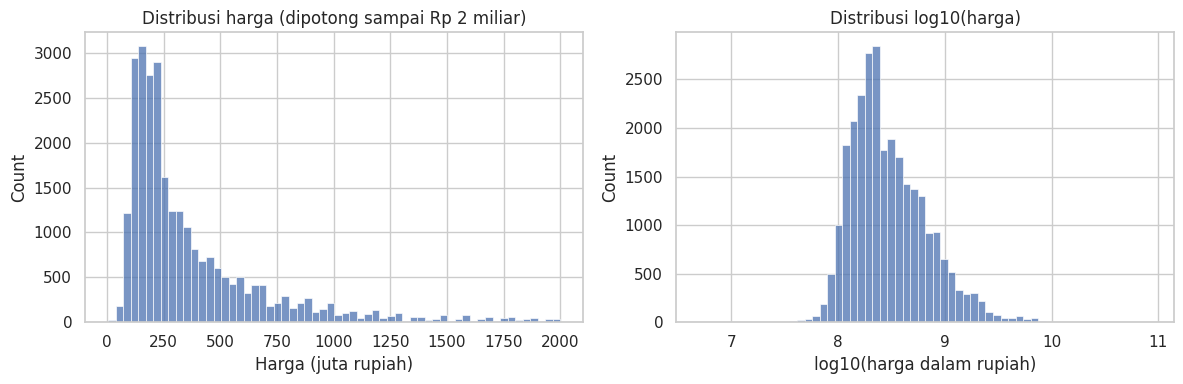

Skewness harga mentah : 38.73
Skewness log(harga)   : 0.84
Batas atas IQR (Rp): 989,999,986 | baris di atasnya: 2396


In [73]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(mobil_eda["price_juta"][mobil_eda["price_juta"] <= 2000], bins=60, ax=axes[0])
axes[0].set_title("Distribusi harga (dipotong sampai Rp 2 miliar)")
axes[0].set_xlabel("Harga (juta rupiah)")
sns.histplot(np.log10(mobil_eda["price"]), bins=60, ax=axes[1])
axes[1].set_title("Distribusi log10(harga)")
axes[1].set_xlabel("log10(harga dalam rupiah)")
plt.tight_layout(); plt.show()
print("Skewness harga mentah :", round(mobil["price"].skew(), 2))
print("Skewness log(harga)   :", round(np.log(mobil["price"]).skew(), 2))
q1, q3 = mobil["price"].quantile([.25, .75]); iqr = q3 - q1
print("Batas atas IQR (Rp):", f"{q3 + 1.5*iqr:,.0f}", "| baris di atasnya:", (mobil["price"] > q3 + 1.5*iqr).sum())

**Temuan, Bukti, Interpretasi, Implikasi**

| Temuan | Bukti | Interpretasi | Implikasi |
|---|---|---|---|
| Harga **sangat miring ke kanan** | Mean Rp 461,5 juta > median Rp 250 juta; *skewness* 38,7; 2.396 iklan di atas batas IQR (Rp 990 juta) | Kebanyakan mobil berharga ratusan juta, sedangkan sedikit mobil mewah (Ferrari, Lamborghini, Rolls-Royce) menarik rata-rata naik | Pakai median dan kuartil untuk gambaran tipikal; jangan memakai rata-rata |
| Setelah log, sebaran jauh lebih simetris | *Skewness* turun dari 38,7 menjadi 0,84 | Selisih harga bersifat proporsional (persen), bukan selisih rupiah | Model memakai `log(price)` sebagai target |
| Nilai ekstrem bukan semuanya salah | Harga di atas Rp 5 miliar: 115 iklan, sebagian besar merek supercar | Harga tinggi pada supercar itu wajar | Jangan hapus outlier berdasarkan batas IQR global; periksa per model |

### Grafik Boxplot `price`: mobil Baru vs Bekas
Membandingkan harga menurut status iklan. Sumbu y memakai skala log agar kotak terlihat.

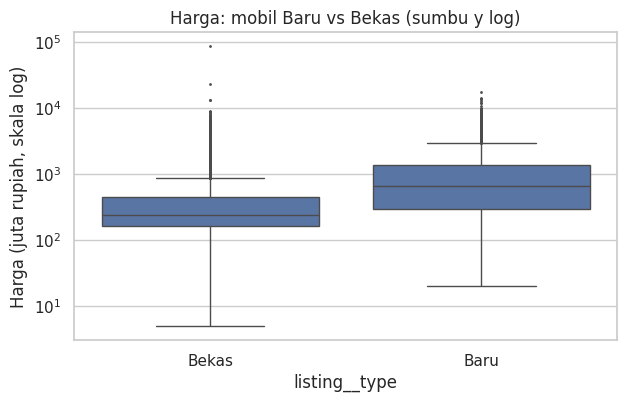

,count,50%,mean
listing__type,,,
Baru,2747.0,645000000.0,1.114375e+09
Bekas,25034.0,235000000.0,3.898808e+08


In [74]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=mobil_eda, x="listing__type", y="price_juta", ax=ax, fliersize=1)
ax.set_yscale("log")
ax.set_title("Harga: mobil Baru vs Bekas (sumbu y log)")
ax.set_ylabel("Harga (juta rupiah, skala log)")
plt.show()
display(mobil.groupby("listing__type")["price"].describe()[["count", "50%", "mean"]].round(0))

**Temuan, Bukti, Interpretasi, Implikasi**

| Temuan | Bukti | Interpretasi | Implikasi |
|---|---|---|---|
| Mobil `Baru` jauh lebih mahal | Median Baru Rp 645 juta vs Bekas Rp 235 juta (sekitar 2,7 kali) | Label `Baru` membawa harga lebih tinggi, sebagian karena `Baru` didominasi mobil tahun 2023 sampai 2025 | Pertahankan `listing__type` sebagai fitur biner (`is_baru`) |
| Kedua kelompok punya banyak titik ekstrem | Titik di luar kumis pada kedua boxplot | Ada mobil sangat mahal pada kedua kelompok | Ekstrem dipertahankan, hanya yang janggal yang ditandai |

### Grafik Boxplot `price` per merek
12 merek terbanyak, diurutkan menurut median harga.

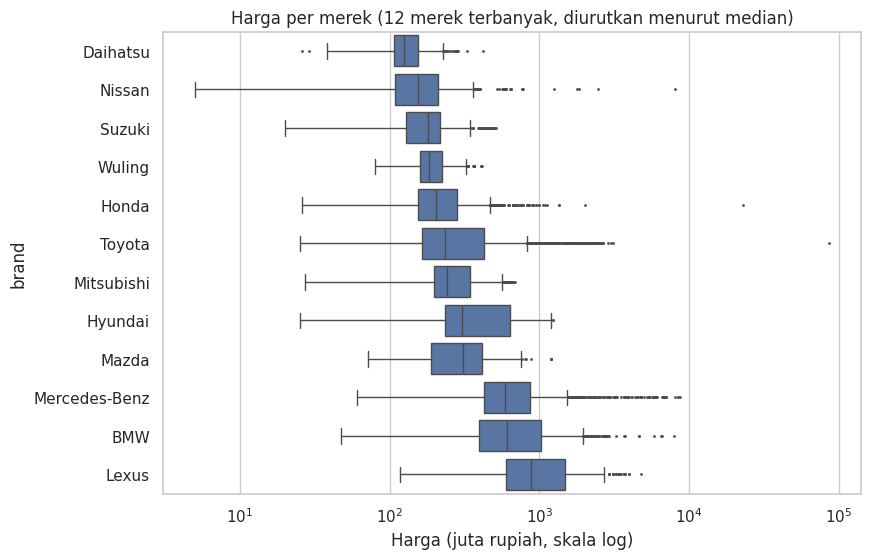

brand
Daihatsu         125 juta
Nissan           155 juta
Suzuki           179 juta
Wuling           182 juta
Honda            203 juta
Toyota           235 juta
Mitsubishi       240 juta
Hyundai          303 juta
Mazda            310 juta
Mercedes-Benz    585 juta
BMW              610 juta
Lexus            880 juta


In [75]:
top_brand = mobil["brand"].value_counts().head(12).index
urutan = (mobil[mobil["brand"].isin(top_brand)].groupby("brand")["price"].median().sort_values().index)
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=mobil_eda[mobil_eda["brand"].isin(top_brand)], y="brand", x="price_juta",
            order=urutan, fliersize=1, ax=ax)
ax.set_xscale("log")
ax.set_title("Harga per merek (12 merek terbanyak, diurutkan menurut median)")
ax.set_xlabel("Harga (juta rupiah, skala log)")
plt.show()
print(mobil[mobil["brand"].isin(top_brand)].groupby("brand")["price"].median().sort_values().apply(lambda x: f"{x/1e6:,.0f} juta").to_string())

**Temuan, Bukti, Interpretasi, Implikasi**

| Temuan | Bukti | Interpretasi | Implikasi |
|---|---|---|---|
| Merek sangat menentukan tingkat harga | Median terendah Daihatsu Rp 125 juta, Nissan Rp 155 juta, Suzuki Rp 179 juta; tertinggi Lexus Rp 880 juta, BMW Rp 610 juta, Mercedes-Benz Rp 585 juta | Merek Jepang segmen massal murah, merek Eropa dan mewah mahal | Merek (dan model) harus masuk sebagai fitur kategorikal |
| Sebaran dalam satu merek lebar | Kotak lebar dan banyak outlier pada merek mewah | Satu merek berisi model murah dan mahal sekaligus | Merek saja tidak cukup; ambil **nama model** dari `brand_type` |

### Grafik Scatter plot `price` vs `year`
Sampel acak 8.000 baris (tahun >= 1995) agar grafik tidak berat. Titik dibuat transparan, sumbu y log.

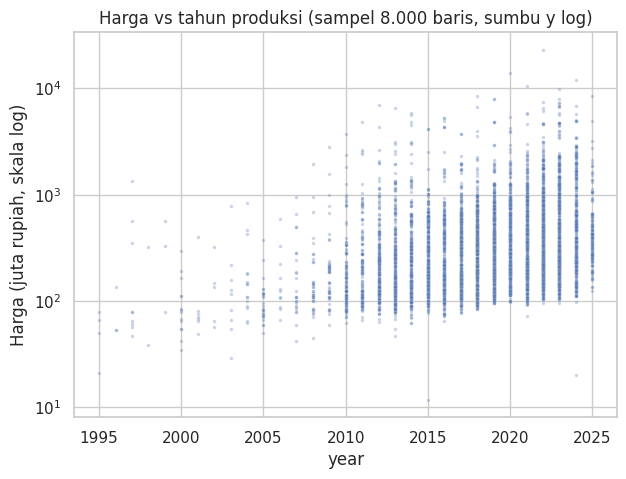

Korelasi Spearman price-year : 0.3
Korelasi Pearson log(price)-year: 0.29
year
2010    155 juta
2011    187 juta
2012    178 juta
2013    190 juta
2014    185 juta
2015    208 juta
2016    208 juta
2017    219 juta
2018    297 juta
2019    309 juta
2020    309 juta
2021    232 juta
2022    257 juta
2023    300 juta
2024    380 juta
2025    397 juta


In [76]:
s = mobil_eda[(mobil_eda["year"] >= 1995)].sample(8000, random_state=42)
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=s, x="year", y="price_juta", s=6, alpha=0.3, ax=ax)
ax.set_yscale("log")
ax.set_title("Harga vs tahun produksi (sampel 8.000 baris, sumbu y log)")
ax.set_ylabel("Harga (juta rupiah, skala log)")
plt.show()
print("Korelasi Spearman price-year :", round(mobil[["price", "year"]].corr(method="spearman").iloc[0, 1], 2))
print("Korelasi Pearson log(price)-year:", round(np.corrcoef(np.log(mobil["price"]), mobil["year"])[0, 1], 2))
print(mobil.groupby("year")["price"].median().loc[2010:2025].apply(lambda x: f"{x/1e6:,.0f} juta").to_string())

**Temuan, Bukti, Interpretasi, Implikasi**

| Temuan | Bukti | Interpretasi | Implikasi |
|---|---|---|---|
| Hubungan harga dan tahun **positif tetapi lemah** | Spearman 0,30; Pearson `log(price)`-`year` 0,29 | Tahun saja tidak cukup menjelaskan harga karena campuran merek dan segmen sangat besar | Jangan menilai harga dari tahun saja; gabungkan dengan merek/model |
| Median harga **tidak naik mulus** menurut tahun | Median 2018 sampai 2020 sekitar Rp 297 sampai 309 juta, turun ke Rp 232 juta pada 2021, lalu naik ke Rp 397 juta pada 2025 | Komposisi merek tiap tahun berbeda (mobil baru 2024 sampai 2025 banyak yang mewah/baru) | Kontrol komposisi lewat fitur model dan merek |

### Grafik Scatter plot `price` vs `KM_1`
Sampel acak 8.000 baris dengan KM <= 300.000.

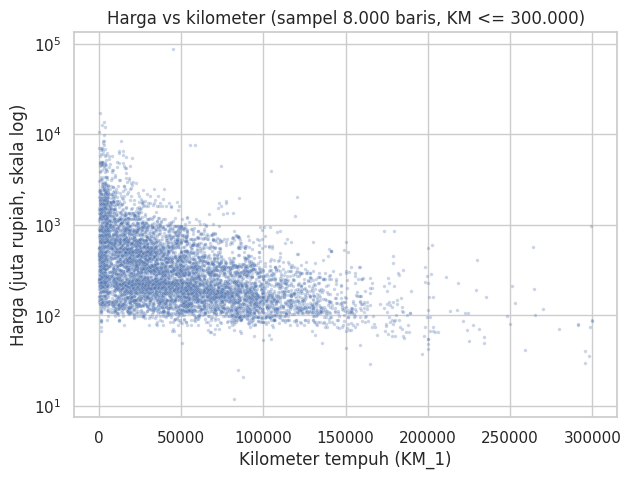

Korelasi Spearman price-KM_1: -0.5
Korelasi Spearman year-KM_1 : -0.68


In [77]:
s = mobil_eda[(mobil_eda["KM_1"] <= 300000)].sample(8000, random_state=42)
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=s, x="KM_1", y="price_juta", s=6, alpha=0.3, ax=ax)
ax.set_yscale("log")
ax.set_title("Harga vs kilometer (sampel 8.000 baris, KM <= 300.000)")
ax.set_xlabel("Kilometer tempuh (KM_1)"); ax.set_ylabel("Harga (juta rupiah, skala log)")
plt.show()
print("Korelasi Spearman price-KM_1:", round(mobil[["price", "KM_1"]].corr(method="spearman").iloc[0, 1], 2))
print("Korelasi Spearman year-KM_1 :", round(mobil[["year", "KM_1"]].corr(method="spearman").iloc[0, 1], 2))

**Temuan, Bukti, Interpretasi, Implikasi**

| Temuan | Bukti | Interpretasi | Implikasi |
|---|---|---|---|
| Kilometer berkorelasi **negatif sedang** dengan harga | Spearman `price`-`KM_1` = -0,50 | Makin jauh ditempuh, makin murah | `KM_1` fitur penting |
| Kilometer dan tahun saling terkait kuat | Spearman `year`-`KM_1` = -0,68 | Mobil lebih tua cenderung berkilometer lebih tinggi; ada tumpang tindih informasi | Perhatikan multikolinearitas pada model linier; model pohon lebih tahan |

### Grafik Bar chart jumlah iklan per provinsi

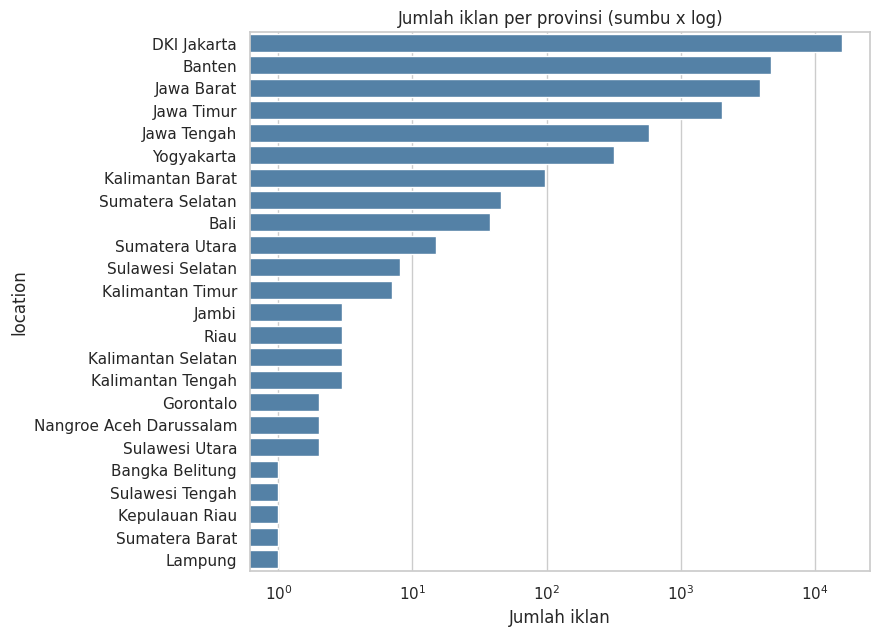

Provinsi terbanyak: DKI Jakarta 16005 (57.6%)
Provinsi dengan < 20 iklan: 15 dari 24


In [78]:
cnt = mobil["location"].value_counts()
fig, ax = plt.subplots(figsize=(8, 7))
sns.barplot(x=cnt.values, y=cnt.index, ax=ax, color="steelblue")
ax.set_xscale("log")
ax.set_title("Jumlah iklan per provinsi (sumbu x log)")
ax.set_xlabel("Jumlah iklan")
plt.show()
print("Provinsi terbanyak:", cnt.index[0], cnt.iloc[0], f"({cnt.iloc[0]/len(mobil):.1%})")
print("Provinsi dengan < 20 iklan:", (cnt < 20).sum(), "dari", len(cnt))

**Temuan, Bukti, Interpretasi, Implikasi**

| Temuan | Bukti | Interpretasi | Implikasi |
|---|---|---|---|
| Data **terpusat di Jabodetabek dan Pulau Jawa** | DKI Jakarta 16.005 (57,6%); empat provinsi teratas 95,9%; 15 dari 24 provinsi < 20 iklan | Hasil model terutama berlaku untuk pasar Jawa | Gabungkan provinsi kecil menjadi `OTHER`; tulis keterbatasan geografis |

### Grafik Boxplot `price` menurut transmisi dan tipe bodi
`body` diambil dari kata terakhir `brand_type` (SUV, MPV, Sedan, dst.).

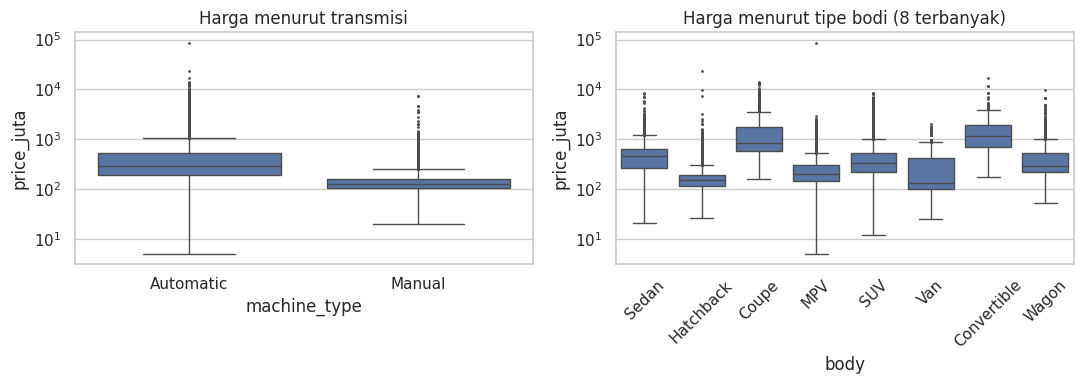

machine_type
Automatic    290 juta
Manual       125 juta
body
Van              129 juta
Hatchback        150 juta
MPV              199 juta
Wagon            285 juta
SUV              328 juta
Sedan            450 juta
Coupe            832 juta
Convertible    1,150 juta


In [79]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=mobil_eda, x="machine_type", y="price_juta", ax=axes[0], fliersize=1)
axes[0].set_yscale("log"); axes[0].set_title("Harga menurut transmisi")
mobil_eda["body"] = mobil_eda["brand_type"].str.split().str[-1]
body_top = mobil_eda["body"].value_counts().head(8).index
sns.boxplot(data=mobil_eda[mobil_eda["body"].isin(body_top)], x="body", y="price_juta", ax=axes[1], fliersize=1)
axes[1].set_yscale("log"); axes[1].set_title("Harga menurut tipe bodi (8 terbanyak)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
print(mobil.groupby("machine_type")["price"].median().apply(lambda x: f"{x/1e6:,.0f} juta").to_string())
print(mobil_eda[mobil_eda["body"].isin(body_top)].groupby("body")["price"].median().sort_values().apply(lambda x: f"{x/1e6:,.0f} juta").to_string())

**Temuan, Bukti, Interpretasi, Implikasi**

| Temuan | Bukti | Interpretasi | Implikasi |
|---|---|---|---|
| Mobil matic lebih mahal | Median Automatic Rp 290 juta vs Manual Rp 125 juta | Manual banyak pada mobil niaga/lama dan segmen murah | `is_matic` fitur biner |
| Tipe bodi membedakan harga | Median Van Rp 129 juta, Hatchback 150 juta, MPV 199 juta, SUV 328 juta, Sedan 450 juta, Coupe 832 juta, Convertible Rp 1,15 miliar | Bodi sportif/mewah jauh lebih mahal | Ekstrak `body_type` dari `brand_type` sebagai fitur |

### Grafik Heatmap korelasi variabel numerik

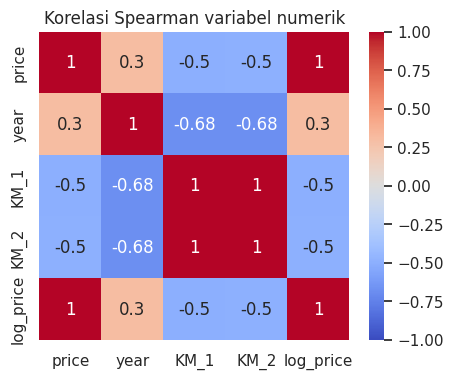

In [80]:
fig, ax = plt.subplots(figsize=(5, 4))
kor = mobil[["price", "year", "KM_1", "KM_2"]].assign(log_price=np.log(mobil["price"])).corr(method="spearman")
sns.heatmap(kor, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Korelasi Spearman variabel numerik")
plt.show()

**Temuan, Bukti, Interpretasi, Implikasi**

| Temuan | Bukti | Interpretasi | Implikasi |
|---|---|---|---|
| `KM_1` dan `KM_2` hampir identik | Korelasi 0,9993 (Pearson); `KM_2` hanyalah batas atas rentang `KM_1` | `KM_2` tidak menambah informasi | Buang `KM_2`, pakai `KM_1` |
| Hanya `KM_1` dan `year` yang cukup berkaitan dengan harga | `price`-`KM_1` -0,50, `price`-`year` 0,30 | Variabel numerik saja tidak cukup; ciri kategorikal (merek, model, mesin) perlu ditambahkan | Bangun fitur tambahan (kapasitas mesin, nama model) |

# Data Quality Findings

Tiap temuan dibuktikan dengan kode, lalu dirangkum dalam satu tabel di akhir bagian ini.

## Temuan 1. Format kolom `KM` tidak konsisten dan ada kolom redundan

Pertanyaannya: apakah kolom `KM`, `item`, `KM_1`, `KM_2` seragam, dan apakah semuanya perlu dipakai?

In [81]:
km_rentang = mobil["KM"].astype(str).str.match(r"^\d+ - \d+K$")
print("KM berformat rentang ('85 - 90K'):", km_rentang.sum(), f"({km_rentang.mean():.2%})")
print("KM berformat angka persis ('30000'):", (~km_rentang).sum(), f"({(~km_rentang).mean():.2%})")
display(mobil.loc[~km_rentang, ["KM", "KM_1", "KM_2", "item"]].head(5))
print("\nKM_1 == KM_2 pada baris format angka persis:", (mobil.loc[~km_rentang, "KM_1"] == mobil.loc[~km_rentang, "KM_2"]).mean())

print("\nitem identik dengan KM + ' KM':", (mobil["item"] == mobil["KM"].astype(str) + " KM").mean())
print("Kolom 'Unnamed: 0' sama dengan nomor baris:", (mobil["Unnamed: 0"] == np.arange(len(mobil))).mean())
# KM_2 adalah batas atas rentang (hasil binning), KM_1 adalah odometer hampir persis
print("Korelasi KM_1 dengan KM_2:", round(mobil[["KM_1", "KM_2"]].corr().iloc[0, 1], 4))

KM berformat rentang ('85 - 90K'): 23433 (84.35%)
KM berformat angka persis ('30000'): 4348 (15.65%)


,KM,KM_1,KM_2,item
98,30000,30000,30000,30000 KM
99,97000,97000,97000,97000 KM
100,69000,69000,69000,69000 KM
101,66000,66000,66000,66000 KM
103,58000,58000,58000,58000 KM



KM_1 == KM_2 pada baris format angka persis: 1.0

item identik dengan KM + ' KM': 1.0
Kolom 'Unnamed: 0' sama dengan nomor baris: 1.0
Korelasi KM_1 dengan KM_2: 0.9993


## Temuan 2. Duplikasi tersembunyi pada iklan

Cek duplikat biasa (seluruh kolom) tidak menemukan apa-apa karena judul dan deskripsi tiap iklan berbeda. Di sini dibandingkan 7 kolom yang mendefinisikan sebuah mobil.

In [82]:
kunci = ["brand", "brand_type", "year", "KM_1", "price", "location", "machine_type"]
print("Duplikat baris penuh (semua kolom):", mobil.duplicated().sum())
print("Duplikat tanpa kolom indeks        :", mobil.drop(columns="Unnamed: 0").duplicated().sum())
print("Duplikat pada 7 kolom kunci         :", mobil.duplicated(kunci).sum(),
      f"({mobil.duplicated(kunci).mean():.2%})")
dup = mobil[mobil.duplicated(kunci, keep=False)].sort_values(kunci)
print("Baris yang terlibat:", len(dup))
display(dup[kunci + ["ellipsize"]].head(6))

Duplikat baris penuh (semua kolom): 0
Duplikat tanpa kolom indeks        : 0
Duplikat pada 7 kolom kunci         : 372 (1.34%)
Baris yang terlibat: 693


,brand,brand_type,year,KM_1,price,location,machine_type,ellipsize
24672,BMW,318i 1.8 E36 1.8 Manual Sedan,1997,178000,59000000,Jawa Barat,Manual,1997 BMW 318i 1.8 E36 1.8 Manual Sedan - E36 M...
24680,BMW,318i 1.8 E36 1.8 Manual Sedan,1997,178000,59000000,Jawa Barat,Manual,"1997 BMW 318i 1.8 E36 1.8 Manual Sedan - 1,8 E..."
20680,BMW,320i 2.0 Dynamic Sedan,2022,32000,600000000,DKI Jakarta,Automatic,"2022 BMW 320i 2.0 Dynamic Sedan - 2,0 G20 Spor..."
20788,BMW,320i 2.0 Dynamic Sedan,2022,32000,600000000,DKI Jakarta,Automatic,"2022 BMW 320i 2.0 Dynamic Sedan - 2,0"
20397,BMW,320i 2.0 Luxury Sedan,2019,34000,395000000,DKI Jakarta,Automatic,2019 BMW 320i 2.0 Luxury Sedan - ( TDP 55jt ) ...
20404,BMW,320i 2.0 Luxury Sedan,2019,34000,395000000,DKI Jakarta,Automatic,2019 BMW 320i 2.0 Luxury Sedan - ( TDP 55jt ) ...


## Temuan 3. Harga ekstrem dan tidak masuk akal

In [83]:
print("Harga terendah:")
display(mobil.nsmallest(6, "price")[["brand", "brand_type", "year", "KM_1", "price"]])
print("Harga tertinggi:")
display(mobil.nlargest(6, "price")[["brand", "brand_type", "year", "KM_1", "price"]])

print("Harga < Rp 30 juta:", (mobil["price"] < 30e6).sum(), "| > Rp 2 miliar:", (mobil["price"] > 2e9).sum(),
      "| > Rp 5 miliar:", (mobil["price"] > 5e9).sum())

# bandingkan dengan median model yang sama (brand + brand_type)
med_model = mobil.groupby(["brand", "brand_type"])["price"].transform("median")
n_model = mobil.groupby(["brand", "brand_type"])["price"].transform("size")
rasio = (mobil["price"] / med_model).where(n_model >= 5)
print("\nHarga > 5x median model yang sama (model >= 5 iklan):", (rasio > 5).sum())
display(mobil.loc[rasio > 5, ["brand", "brand_type", "year", "KM_1", "price"]].assign(
    median_model=med_model[rasio > 5]).sort_values("price", ascending=False).head(8))

Harga terendah:


,brand,brand_type,year,KM_1,price
17636,Nissan,Livina 1.5 VL MPV,2020,600000,5000000
23672,Ford,EcoSport 1.5 Titanium SUV,2015,82366,11800000
16898,Suzuki,Carry 1.5 Pick Up Flat Deck AC/PS Lorry,2024,1891,20000000
13103,Suzuki,Esteem 1.3 Sedan,1995,87576,21000000
3428,Toyota,Kijang 1.5 Kijang Standard Short Van,1991,84271,25000000
13151,Hyundai,Excel 1.5 Sedan,2004,95488,25000000


Harga tertinggi:


,brand,brand_type,year,KM_1,price
8401,Toyota,Alphard 2.5 G MPV,2021,44794,85900000098
811,Honda,City 1.5 RS Hatchback,2022,26934,23000000000
23913,Ferrari,SF90 Spider 4.0 Convertible,2022,634,17000000000
7776,Ferrari,488 Pista 3.9 Coupe,2020,2997,14000000000
7894,Ferrari,488 Pista 3.9 Coupe,2021,2773,13500000000
25021,Ferrari,488 Pista 3.9 Coupe,2021,2122,13500000000


Harga < Rp 30 juta: 13 | > Rp 2 miliar: 671 | > Rp 5 miliar: 115

Harga > 5x median model yang sama (model >= 5 iklan): 6


,brand,brand_type,year,KM_1,price,median_model
8401,Toyota,Alphard 2.5 G MPV,2021,44794,85900000098,850000000.0
811,Honda,City 1.5 RS Hatchback,2022,26934,23000000000,228000000.0
10927,Porsche,Panamera 3.6 Hatchback,2013,25989,7500000000,762500000.0
12921,BMW,530i 2.0 Luxury Sedan,2018,33155,5800000000,499000000.0
5883,Honda,Jazz 1.5 RS Hatchback,2015,120419,2015000000,186000000.0
820,Toyota,Alphard 2.4 X MPV,2013,85371,1955000000,215000000.0


## Temuan 4. Tahun, kilometer, dan label `Baru` yang janggal

In [84]:
baru = mobil[mobil["listing__type"] == "Baru"]
print("Iklan 'Baru':", len(baru), "| KM_1 maks:", baru["KM_1"].max(), "| semua KM '0 - 5K':", (baru["KM"] == "0 - 5K").all())
print("Iklan 'Baru' dengan tahun < 2022:", (baru["year"] < 2022).sum(), "| tahun terlama:", baru["year"].min())
print("Iklan 'Bekas' dengan KM '0 - 5K':", ((mobil["listing__type"] == "Bekas") & (mobil["KM"] == "0 - 5K")).sum())
print("Iklan 'Bekas' dengan KM_1 < 5.000 (format angka persis):", ((mobil["listing__type"] == "Bekas") & (mobil["KM_1"] < 5000)).sum())

print("\nTahun < 2000:", (mobil["year"] < 2000).sum(), "| tahun terlama:", mobil["year"].min(), "| terbaru:", mobil["year"].max())
display(mobil[mobil["year"] < 1985][["brand", "brand_type", "year", "price"]].head(6))

print("\nKM_1 > 300.000:", (mobil["KM_1"] > 300000).sum(), "| maksimum:", mobil["KM_1"].max())
display(mobil.nlargest(5, "KM_1")[["brand", "brand_type", "year", "KM_1", "price"]])

umur = 2025 - mobil["year"]
print("\nUmur <= 3 tahun tetapi KM > 150.000:", ((umur <= 3) & (mobil["KM_1"] > 150000)).sum())

Iklan 'Baru': 2747 | KM_1 maks: 4998 | semua KM '0 - 5K': True
Iklan 'Baru' dengan tahun < 2022: 294 | tahun terlama: 1975
Iklan 'Bekas' dengan KM '0 - 5K': 0
Iklan 'Bekas' dengan KM_1 < 5.000 (format angka persis): 195

Tahun < 2000: 141 | tahun terlama: 1959 | terbaru: 2025


,brand,brand_type,year,price
1418,Toyota,Land Cruiser 4.2 Fj40 Hardtop SUV,1982,260000000
1423,Toyota,Land Cruiser 4.2 Fj40 Hardtop SUV,1980,275000000
3304,Toyota,Land Cruiser 3.0 BJ40 RV-KC (Hardtop) SUV,1983,295000000
11556,Volkswagen,Kombi 1.6 Van,1969,975000000
11631,Land,Rover Defender 2.0 SUV,1959,285000000
12008,Land,Rover Hardtop Short 2.3 88 WB SUV,1975,400000000



KM_1 > 300.000: 8 | maksimum: 1150000


,brand,brand_type,year,KM_1,price
1170,Daihatsu,Gran Max 1.3 Blind Van Van,2012,1150000,55000000
10849,Honda,City 1.5 ES Sedan,2014,880000,144000000
17636,Nissan,Livina 1.5 VL MPV,2020,600000,5000000
18795,Suzuki,Esteem 1.3 Sedan,1994,500000,30000000
10131,Mitsubishi,Kuda 2.5 Super Exceed (Diesel) MPV,2000,440000,78000000



Umur <= 3 tahun tetapi KM > 150.000: 2


## Temuan 5. Kolom teks bermasalah: terpotong, merek terbelah, dan bocoran harga

In [85]:
print("brand_type terpotong ('...'):", mobil["brand_type"].str.endswith("...").sum())
print("ellipsize terpotong ('...') :", mobil["ellipsize"].str.endswith("...").sum(), f"({mobil['ellipsize'].str.endswith('...').mean():.1%})")
print("listing__excerpt kosong     :", mobil["listing__excerpt"].isna().sum())
print("listing__excerpt bukan teks :", mobil["listing__excerpt"].map(lambda x: not isinstance(x, str)).sum(), "(termasuk NaN dan angka 0)")

# merek yang terbelah dua kata
print("\nMerek terbelah (kata kedua masuk ke brand_type):")
for b in ["Land", "Alfa", "Aston"]:
    print(f"  {b}:", mobil.loc[mobil["brand"] == b, "brand_type"].head(2).tolist())

# bocoran informasi harga dan promosi pada teks iklan
teks = mobil["ellipsize"].astype(str) + " " + mobil["listing__excerpt"].astype(str)
pola_harga = r"(?:\d+(?:[.,]\d+)?\s?(?:M|Jt|juta|JT)\b|\bTDP\b|\bDP\b|cash|kredit|credit)"
print("\nIklan yang memuat istilah harga/cicilan (TDP, DP, cash, kredit, 'xx Jt'):",
      teks.str.contains(pola_harga, case=False, regex=True).sum(),
      f"({teks.str.contains(pola_harga, case=False, regex=True).mean():.1%})")

brand_type terpotong ('...'): 140
ellipsize terpotong ('...') : 6211 (22.4%)
listing__excerpt kosong     : 2
listing__excerpt bukan teks : 3 (termasuk NaN dan angka 0)

Merek terbelah (kata kedua masuk ke brand_type):
  Land: ['Rover Range Rover Velar 3.0 P380 R-Dynamic SE SUV', 'Rover Range Rover Evoque 2.0 Dynamic Si4 SUV']
  Alfa: ['Romeo 4C 1.7 Convertible']
  Aston: ['Martin Vantage 4.0 Coupe']

Iklan yang memuat istilah harga/cicilan (TDP, DP, cash, kredit, 'xx Jt'): 14071 (50.6%)


## Temuan 6. Kategori tidak seimbang dan terlalu banyak nilai unik

In [86]:
jar = mobil["location"].value_counts()
print("location: terbesar =", jar.index[0], jar.iloc[0], "| terkecil =", jar.index[-1], jar.iloc[-1],
      "| provinsi < 20 iklan:", (jar < 20).sum(), "dari", len(jar))
print("Jakarta+Banten+Jawa Barat+Jawa Timur:", f"{jar.iloc[:4].sum()/len(mobil):.1%}")

mr = mobil["brand"].value_counts()
print("\nbrand: terbesar =", mr.index[0], mr.iloc[0], "| merek < 20 iklan:", (mr < 20).sum(), "dari", len(mr),
      "| merek < 1% :", (mr / len(mobil) * 100 < 1).sum())
print("machine_type:", mobil["machine_type"].value_counts(normalize=True).round(3).to_dict())
print("listing__type:", mobil["listing__type"].value_counts(normalize=True).round(3).to_dict())

mobil["_body"] = mobil["brand_type"].str.split().str[-1]
print("\nJumlah nilai berbeda pada 'kata terakhir brand_type':", mobil["_body"].nunique())
print("brand_type unik:", mobil["brand_type"].nunique(), "dari", len(mobil), "baris")
mobil.drop(columns="_body", inplace=True)

location: terbesar = DKI Jakarta 16005 | terkecil = Lampung 1 | provinsi < 20 iklan: 15 dari 24
Jakarta+Banten+Jawa Barat+Jawa Timur: 95.9%

brand: terbesar = Toyota 7422 | merek < 20 iklan: 24 dari 61 | merek < 1% : 48
machine_type: {'Automatic': 0.879, 'Manual': 0.121}
listing__type: {'Bekas': 0.901, 'Baru': 0.099}

Jumlah nilai berbeda pada 'kata terakhir brand_type': 61
brand_type unik: 2654 dari 27781 baris


## Ringkasan Data Quality Findings

| No | Temuan | Bukti | Implikasi |
|---|---|---|---|
| 1 | Format kolom `KM` tidak konsisten dan ada kolom redundan | 4.348 baris (15,65%) berformat angka persis (`30000`), 23.433 baris berformat rentang (`85 - 90K`). Pada baris angka persis `KM_1` = `KM_2`. `item` sama persis dengan `KM` + " KM" dan `Unnamed: 0` sama dengan nomor baris. Korelasi `KM_1`-`KM_2` 0,9993 | `KM` tidak bisa dipakai langsung (teks campuran). Pakai `KM_1` sebagai satu-satunya fitur kilometer; buang `KM`, `KM_2`, `item`, `Unnamed: 0` |
| 2 | Duplikasi tersembunyi pada iklan | Duplikat baris penuh = 0, tetapi 372 baris (1,34%) duplikat pada 7 kolom kunci (merek, model, tahun, KM, harga, provinsi, transmisi); 693 baris terlibat. Pasangan hanya beda judul/deskripsi | Buang 372 duplikat (`keep="first"`) agar mobil yang sama tidak terhitung dua kali dan tidak bocor antara data latih dan uji |
| 3 | Harga ekstrem dan tidak masuk akal | Terendah Rp 5 juta (Livina 2020 dengan KM 600.000), Rp 11,8 juta (EcoSport 2015); tertinggi **Rp 85,9 miliar** (Toyota Alphard 2021, median modelnya Rp 850 juta) dan Rp 23 miliar (Honda City RS 2022, median modelnya Rp 228 juta). 13 iklan < Rp 30 juta, 671 iklan > Rp 2 miliar, 115 iklan > Rp 5 miliar. 6 iklan > 5 kali median model yang sama | Harga di luar Rp 20 juta sampai Rp 20 miliar dianggap salah input dan dikeluarkan (4 baris). Harga supercar tinggi tetap dipertahankan; yang > 5x median model hanya ditandai |
| 4 | Tahun, kilometer, dan label `Baru` janggal | 294 iklan `Baru` bertahun < 2022 (terlama 1975); semua `Baru` ber-KM < 5.000, 195 iklan `Bekas` juga ber-KM < 5.000. KM_1 > 300.000: 8 iklan (maks 1.150.000 pada Gran Max 2012); 2 mobil berumur <= 3 tahun ber-KM > 150.000. 141 mobil bertahun < 2000 (klasik: Land Cruiser FJ40, Kombi 1969) | Kilometer > 400.000 atau mobil muda dengan KM > 150.000 dikeluarkan (7 baris, 10 baris total bersama harga mustahil). Mobil klasik dipertahankan karena nyata; umur mobil sangat besar ditafsirkan hati-hati |
| 5 | Kolom teks bermasalah dan membocorkan harga | `brand_type` terpotong ('...') pada 140 baris; `ellipsize` terpotong pada 6.211 baris (22,4%); `listing__excerpt` kosong 2 dan 3 nilai bukan teks. Merek terbelah: `Land` + `Rover ...`, `Alfa` + `Romeo`, `Aston` + `Martin`. Sebanyak 14.071 iklan (50,6%) memuat istilah harga/cicilan (TDP, DP, cash, kredit, "xx Jt") | Merek diperbaiki (Land Rover, Alfa Romeo, Aston Martin). `ellipsize` dan `listing__excerpt` **tidak dipakai sebagai fitur** karena membocorkan target dan berisi noise promosi |
| 6 | Kategori tidak seimbang dan terlalu banyak nilai unik | `location`: Jakarta 57,6%, 15 dari 24 provinsi < 20 iklan. `brand`: 48 dari 61 merek < 1%. `brand_type` punya 2.654 nilai unik; nama model (merek + kata pertama) 563 nilai unik. Transmisi 87,9% Automatic; `Baru` hanya 9,9% | Gabungkan kategori < 1% menjadi `OTHER` (0,3% untuk nama model). *One-hot* hanya setelah penggabungan. Tulis keterbatasan: hasil terutama untuk pasar Jawa dan merek populer |

# RENCANA PREPROCESSING

## 1.0 Ringkasan Rencana

Setiap masalah diuraikan menurut tiga pertanyaan: apa masalahnya, mengapa penting, dan bagaimana rencana penanganannya. Penjelasan rinci dan kode terdapat pada subbagian 1.1 sampai 1.6.

**Masalah utama**

| Masalah | Variabel | Rencana Penanganan | Alasan |
|---|---|---|---|
| **Missing value** | `listing__excerpt` (2 kosong, 1 nilai angka) | Diisi string kosong; kolom ini tidak dipakai sebagai fitur | Hanya 2 baris dan kolomnya tidak masuk model |
| **Outlier** | `price` (skewness 38,7; maks Rp 85,9 miliar); `KM_1` (maks 1.150.000) | Harga di luar Rp 20 juta sampai Rp 20 miliar dan KM janggal dikeluarkan (10 baris). Harga > 5x median model hanya **ditandai**. Target diubah ke `log(price)`; `KM_1` diubah ke akar kuadrat | Harga mustahil merusak model; harga supercar nyata dipertahankan. Transformasi menurunkan skewness (harga 7,0 menjadi 0,83 setelah pembersihan; KM 1,39 menjadi 0,19) |
| **Data kategorikal** | `brand`, `brand_type`, `location`, `machine_type`, `listing__type` | Tipe bodi dan nama model diekstrak dari `brand_type`; kategori < 1% digabung (`OTHER`); biner untuk `listing__type` dan `machine_type`; *one-hot* untuk merek/model/provinsi/bodi | Kategori kecil tidak stabil untuk validasi silang |
| **Perbedaan skala** | `umur`, `km_sqrt`, `engine` | Standardisasi (*z-score*) dalam Pipeline, hanya dari data latih | Skala KM (ratusan ribu) jauh melebihi umur (puluhan); penting bagi model linier |
| **Data leakage** | `ellipsize`, `listing__excerpt`, `price`, flag harga | Lihat bagian 1.6 | Teks iklan memuat harga/cicilan sehingga evaluasi akan terlalu optimistis |

**Penanganan pendukung**

| Masalah | Variabel | Rencana Penanganan | Alasan |
|---|---|---|---|
| Format `KM` campuran dan kolom redundan | `KM`, `KM_2`, `item`, `Unnamed: 0` | Buang; pakai `KM_1` | Informasi sama, format tidak seragam |
| Duplikasi iklan | 7 kolom kunci | Buang 372 duplikat | Mobil sama tidak boleh terhitung dua kali |
| Merek terbelah | `brand`, `brand_type` | Gabung menjadi Land Rover, Alfa Romeo, Aston Martin | Pencocokan merek yang benar |
| Kapasitas mesin tidak ada sebagai kolom | `brand_type` | Ekstrak angka seperti `1.5` dengan regex; kosong diimputasi median dalam Pipeline | Fitur kuat (lihat ablation) |

## 1.1 Penataan Struktur Data

**Kolom.** `Unnamed: 0` (nomor baris) dan `item` (salinan `KM`) dibuang. Spasi di ujung teks dirapikan. Merek yang terbelah (`Land` + `Rover ...`) digabung.

**Duplikasi.** Pemeriksaan seluruh kolom menghasilkan nol, tetapi berdasarkan 7 kolom kunci terdapat 372 duplikat. Baris pertama dipertahankan, **indeks asli tidak direset** agar tiap baris bisa dilacak kembali ke data mentah.

In [87]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

In [88]:
# 1.1 Penataan struktur data
df = mobil.copy()

# buang kolom indeks sisa Excel dan kolom salinan
df = df.drop(columns=["Unnamed: 0", "item"])

# rapikan spasi pada kolom teks
for k in ["listing__type", "machine_type", "location", "brand", "brand_type", "ellipsize"]:
    df[k] = df[k].astype(str).str.strip()

# perbaiki merek yang terbelah dua kata (Land Rover, Alfa Romeo, Aston Martin)
perbaikan = {"Land": "Rover", "Alfa": "Romeo", "Aston": "Martin"}
for depan, belakang in perbaikan.items():
    m = (df["brand"] == depan) & df["brand_type"].str.startswith(belakang)
    df.loc[m, "brand"] = depan + " " + belakang
    df.loc[m, "brand_type"] = df.loc[m, "brand_type"].str[len(belakang):].str.strip()
print("Merek setelah perbaikan:", sorted(df.loc[df["brand"].str.contains(" "), "brand"].unique()))

# ringkasan duplikasi
kunci = ["brand", "brand_type", "year", "KM_1", "price", "location", "machine_type"]
n_dup = df.duplicated(kunci).sum()
df = df.drop_duplicates(kunci, keep="first")      # indeks asli dipertahankan agar baris bisa dilacak
print("Duplikat dibuang:", n_dup, "| sisa baris:", len(df))

Merek setelah perbaikan: ['Alfa Romeo', 'Aston Martin', 'Land Rover']
Duplikat dibuang: 372 | sisa baris: 27409


## 1.2 *Missing Value*

**Masalah.** Hanya `listing__excerpt` yang bermasalah (2 kosong dan 1 angka `0`), dan kolom ini tidak masuk fitur. **Rencana.** Diisi string kosong dan dijadikan teks. Tidak ada imputasi pada `price`, `year`, `KM_1`, karena lengkap. Kapasitas mesin yang tidak terbaca diimputasi **di dalam Pipeline** nanti.

In [89]:
# 1.2 Missing value
print("Missing value sebelum:", df.isna().sum()[lambda s: s > 0].to_dict())
print("listing__excerpt bukan teks:", df["listing__excerpt"].map(lambda x: not isinstance(x, str)).sum())
df["listing__excerpt"] = df["listing__excerpt"].fillna("").astype(str)
print("Missing value sesudah:", df.isna().sum().sum())

Missing value sebelum: {'listing__excerpt': 2}
listing__excerpt bukan teks: 3
Missing value sesudah: 0


## 1.3 *Outlier*

**Masalah.** Ada tiga sumber nilai ekstrem: (a) harga yang mustahil (Rp 5 juta untuk Livina, Rp 85,9 miliar untuk Alphard), (b) harga yang jauh di atas median modelnya, (c) kilometer yang tidak wajar. **Rencana.** Harga di luar Rp 20 juta sampai Rp 20 miliar dan kilometer janggal dikeluarkan. Harga > 5x median model hanya **ditandai** (tidak dibuang) untuk diperiksa pada tahap pemodelan.

In [90]:
med_model = df.groupby(["brand", "brand_type"])["price"].transform("median")
n_model = df.groupby(["brand", "brand_type"])["price"].transform("size")
df["flag_harga_janggal"] = ((df["price"] / med_model > 5) & (n_model >= 5)).astype(int)

df["flag_harga_mustahil"] = ((df["price"] < 20e6) | (df["price"] > 20e9)).astype(int)

umur = 2025 - df["year"]
df["flag_km_janggal"] = ((df["KM_1"] > 400000) | ((umur <= 3) & (df["KM_1"] > 150000))).astype(int)

print(df[["flag_harga_janggal", "flag_harga_mustahil", "flag_km_janggal"]].sum())

bersih = df[(df["flag_harga_mustahil"] == 0) & (df["flag_km_janggal"] == 0)].copy()
print("Baris sebelum:", len(df), "-> sesudah:", len(bersih), f"({len(df)-len(bersih)} dikeluarkan)")

flag_harga_janggal     6
flag_harga_mustahil    4
flag_km_janggal        7
dtype: int64
Baris sebelum: 27409 -> sesudah: 27399 (10 dikeluarkan)


**Temuan:** 6 iklan ditandai harga janggal (> 5x median model), 4 iklan berharga mustahil, 7 iklan berkilometer janggal; karena ada irisan (Livina 2020 masuk keduanya), total **10 baris** dikeluarkan dari 27.409 menjadi 27.399.

## 1.4 Data Kategorikal
**Masalah.** `brand_type` berisi 2.654 nilai unik dan merek/provinsi banyak yang berfrekuensi kecil. **Rencana.** (1) ekstrak tipe bodi dari kata terakhir `brand_type`, (2) buat nama model (merek + kata pertama), (3) gabungkan kategori jarang menjadi `OTHER` (< 1%; model < 0,3%). Penggabungan hanya memakai frekuensi, **tidak memakai harga**, sehingga tidak membocorkan target.

In [91]:
bodi_valid = ["SUV", "MPV", "Hatchback", "Sedan", "Wagon", "Coupe", "Van", "Convertible", "Pickup", "Lorry", "Fastback"]
def ambil_bodi(s):
    kata = s.replace("Pick-up", "Pickup").replace("Pick Up", "Pickup").split()
    return kata[-1] if kata and kata[-1] in bodi_valid else "Lainnya"
bersih["body_type"] = bersih["brand_type"].map(ambil_bodi)

bersih["model"] = bersih["brand"] + " " + bersih["brand_type"].str.split().str[0]

def gabung_jarang(s, ambang=1.0, label="OTHER"):
    persen = s.value_counts(normalize=True) * 100
    jarang = persen[persen < ambang].index
    return s.where(~s.isin(jarang), label)

bersih["brand_g"] = gabung_jarang(bersih["brand"], 1.0)
bersih["location_g"] = gabung_jarang(bersih["location"], 1.0)
bersih["body_g"] = gabung_jarang(bersih["body_type"], 1.0)
bersih["model_g"] = gabung_jarang(bersih["model"], 0.3)
for k in ["brand", "brand_g", "location", "location_g", "model", "model_g", "body_g"]:
    print(f"{k:11s}: {bersih[k].nunique()} kategori")
print(bersih["body_type"].value_counts().head(12).to_dict())

brand      : 61 kategori
brand_g    : 14 kategori
location   : 24 kategori
location_g : 7 kategori
model      : 563 kategori
model_g    : 84 kategori
body_g     : 8 kategori
{'SUV': 9855, 'MPV': 7284, 'Hatchback': 3955, 'Sedan': 3083, 'Wagon': 1269, 'Coupe': 895, 'Van': 280, 'Convertible': 243, 'Pickup': 193, 'Lainnya': 174, 'Lorry': 88, 'Fastback': 80}


## 1.5 Transformasi dan Skala
**Masalah.** `price` sangat miring (7,0 setelah dibersihkan, 38,7 pada data mentah) dan `KM_1` miring ke kanan (1,39). **Rencana.** `log(price)` sebagai target; `sqrt(KM_1)` karena `log1p` malah membuat sebaran miring ke kiri (-1,48) akibat mobil Baru dengan KM mendekati 0 (sqrt menghasilkan 0,19); `umur` = 2025 - `year`; kapasitas mesin diekstrak dari `brand_type`.

In [92]:
bersih["log_price"] = np.log(bersih["price"])
bersih["km_sqrt"] = np.sqrt(bersih["KM_1"])
bersih["umur"] = 2025 - bersih["year"]
bersih["is_baru"] = (bersih["listing__type"] == "Baru").astype(int)
bersih["is_matic"] = (bersih["machine_type"] == "Automatic").astype(int)

bersih["engine"] = bersih["brand_type"].str.extract(r"(?<![\d.])(\d\.\d)(?![\d])")[0].astype(float)
print("Kapasitas mesin terbaca:", f"{bersih['engine'].notna().mean():.1%}", "| kosong:", bersih["engine"].isna().sum(),
      "(diimputasi median DI DALAM pipeline, hanya dari data latih)")

print("\nSkewness price :", round(bersih["price"].skew(), 2), "->  log(price):", round(bersih["log_price"].skew(), 2))
print("Skewness KM_1  :", round(bersih["KM_1"].skew(), 2), "->  sqrt(KM):", round(bersih["km_sqrt"].skew(), 2),
      "| log1p(KM):", round(np.log1p(bersih["KM_1"]).skew(), 2))
display(bersih[["log_price", "km_sqrt", "umur", "engine"]].describe().round(2))

Kapasitas mesin terbaca: 97.4% | kosong: 708 (diimputasi median DI DALAM pipeline, hanya dari data latih)

Skewness price : 7.01 ->  log(price): 0.83
Skewness KM_1  : 1.39 ->  sqrt(KM): 0.19 | log1p(KM): -1.48


,log_price,km_sqrt,umur,engine
count,27399.00,27399.00,27399.00,26691.00
mean,19.52,201.12,6.40,1.89
std,0.82,94.64,4.57,0.71
min,16.81,0.00,0.00,0.50
25%,18.93,133.69,3.00,1.50
50%,19.34,199.00,6.00,1.50
75%,20.02,268.24,9.00,2.40
max,23.56,632.46,66.00,6.70


## 1.6 *Data Leakage*

***Data leakage*** terjadi ketika informasi yang seharusnya tidak tersedia saat pelatihan ikut dipakai (data uji, atau target itu sendiri). Pada proyek ini ada tiga sumber risiko:

1. **Teks iklan** (`ellipsize`, `listing__excerpt`): 50,6% iklan memuat harga/cicilan (TDP, DP, cash, "1.175M"). Dibuang dari fitur.
2. **Statistik praproses**: imputasi median, standardisasi, dan *one-hot* dihitung hanya dari data latih, di dalam `Pipeline`.
3. **Duplikat**: iklan yang sama muncul dua kali bisa jatuh ke data latih dan data uji; sudah dibuang sebelum pembagian data.

Data dibagi 80% latih dan 20% uji **sebelum** statistik apa pun dihitung. Data uji tidak disentuh sampai tahap pemodelan.

In [93]:
FITUR_NUM = ["umur", "km_sqrt", "engine"]
FITUR_BIN = ["is_baru", "is_matic"]
FITUR_KAT = ["model_g", "location_g", "body_g"]
X = bersih[FITUR_NUM + FITUR_BIN + FITUR_KAT]
y = bersih["log_price"]

X_latih, X_uji, y_latih, y_uji = train_test_split(X, y, test_size=0.2, random_state=42)
print("Latih:", X_latih.shape, "| Uji:", X_uji.shape)

def buat_praproses(num, kat, bin_=FITUR_BIN):
    """Imputasi median + standardisasi untuk numerik; one-hot untuk kategorikal. Semua di-fit hanya pada data latih."""
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("bin", "passthrough", bin_),
        ("kat", OneHotEncoder(handle_unknown="ignore"), kat),
    ])

praproses = buat_praproses(FITUR_NUM, FITUR_KAT)
print("Imputer, scaler, dan encoder baru di-fit di dalam Pipeline (hanya pada lipatan latih).")

Latih: (21919, 8) | Uji: (5480, 8)
Imputer, scaler, dan encoder baru di-fit di dalam Pipeline (hanya pada lipatan latih).


# *INITIAL FEATURE ENGINEERING*

Bertujuan menyusun fitur awal yang relevan dengan masalah proyek dan dapat diverifikasi. Pendekatannya **ablation**: fitur ditambahkan satu per satu, lalu dilihat seberapa besar R² (validasi silang 5-fold pada data latih) naik.

In [94]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def nilai_cv(num, kat, mdl):
    pipa = Pipeline([("pra", buat_praproses(num, kat)), ("m", mdl)])
    return cross_val_score(pipa, X_latih.assign(brand_g=bersih.loc[X_latih.index, "brand_g"]),
                           y_latih, cv=kf, scoring="r2", n_jobs=-1)

ridge = lambda: Ridge(alpha=1.0)
rf = lambda: RandomForestRegressor(n_estimators=100, max_depth=14, n_jobs=-1, random_state=42)

skenario = [
    ("A. Ridge: umur + KM + merek + provinsi + bodi", ["umur", "km_sqrt"], ["brand_g", "location_g", "body_g"], ridge),
    ("B. A + kapasitas mesin",                        ["umur", "km_sqrt", "engine"], ["brand_g", "location_g", "body_g"], ridge),
    ("C. B + nama model (ganti merek)",               ["umur", "km_sqrt", "engine"], ["model_g", "location_g", "body_g"], ridge),
    ("D. Random Forest dengan fitur C",               ["umur", "km_sqrt", "engine"], ["model_g", "location_g", "body_g"], rf),
]
hasil = []
for nama, num, kat, mdl in skenario:
    s = nilai_cv(num, kat, mdl())
    hasil.append({"skenario": nama, "R2 rata-rata": round(s.mean(), 3), "std": round(s.std(), 3)})
display(pd.DataFrame(hasil))

,skenario,R2 rata-rata,std
0,A. Ridge: umur + KM + merek + provinsi + bodi,0.623,0.011
1,B. A + kapasitas mesin,0.787,0.010
2,C. B + nama model (ganti merek),0.821,0.014
3,D. Random Forest dengan fitur C,0.918,0.007


**Temuan.** Model linier dengan fitur dasar (umur, KM, merek, provinsi, bodi) hanya mencapai R² sekitar 0,62. Menambah **kapasitas mesin** menaikkan R² ke 0,79 (kenaikan terbesar), dan mengganti merek dengan **nama model** menaikkan ke 0,82. *Random Forest* dengan fitur yang sama mencapai sekitar 0,92, artinya hubungan antar fitur tidak linier (misalnya dampak KM berbeda untuk mobil murah dan mewah). Simpangan baku antar lipatan kecil (0,007 sampai 0,014), sehingga hasilnya stabil. Angka ini baru perkiraan awal dari validasi silang pada data latih, **bukan** hasil akhir pada data uji.

,kepentingan
num__engine,0.483
num__km_sqrt,0.284
num__umur,0.079
bin__is_matic,0.026
kat__body_g_MPV,0.014
kat__model_g_Toyota Alphard,0.011
kat__model_g_OTHER,0.009
kat__model_g_Toyota Kijang,0.008
kat__model_g_Honda CR-V,0.007
kat__body_g_Sedan,0.007


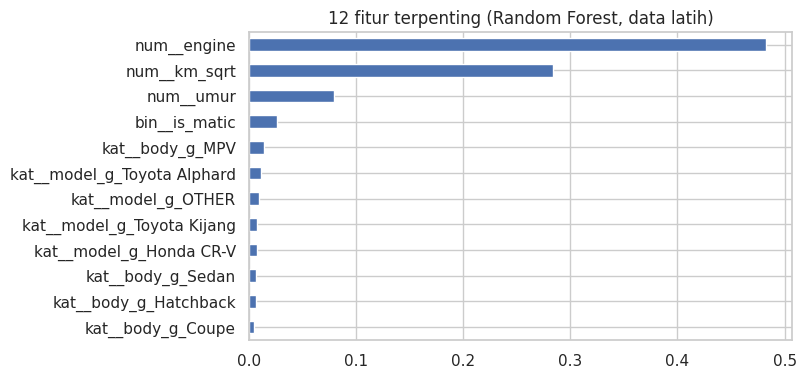

In [95]:
pipa = Pipeline([("pra", praproses), ("m", RandomForestRegressor(n_estimators=150, max_depth=14, n_jobs=-1, random_state=42))])
pipa.fit(X_latih, y_latih)
nama_fitur = pipa.named_steps["pra"].get_feature_names_out()
pent = pd.Series(pipa.named_steps["m"].feature_importances_, index=nama_fitur).sort_values(ascending=False)
display(pent.head(12).round(3).to_frame("kepentingan"))

fig, ax = plt.subplots(figsize=(7, 4))
pent.head(12)[::-1].plot.barh(ax=ax)
ax.set_title("12 fitur terpenting (Random Forest, data latih)")
plt.show()

**Temuan.** Fitur terpenting menurut *Random Forest* adalah kapasitas mesin (kepentingan 0,48), kilometer (0,28), dan umur (0,08), jauh di atas fitur lain. Kapasitas mesin menjadi proksi kelas mobil (mobil 1.5 liter vs 4.0 liter). Ini sejalan dengan EDA: tahun saja lemah (korelasi 0,30), tetapi gabungan umur, kilometer, dan kelas mobil menjelaskan harga dengan baik.

# Initial Data Pipeline

Alur pipeline:

**muat data → rapikan identitas → buang duplikat → keluarkan data mustahil → bangun fitur → validasi**

Seluruh langkah dibungkus satu fungsi, sehingga data baru dapat diproses dengan cara yang sama dan hasilnya bisa diulang. Pipeline berhenti (`assert`) bila ada yang salah.

In [96]:
log = []
def catat(langkah, **info):
    log.append({"langkah": langkah, **info})

def jalankan_pipeline(path_excel, tahun_acuan=2025):
    d = pd.read_excel(path_excel)
    catat("1. muat data", baris=len(d), kolom=d.shape[1])

    d = d.drop(columns=["Unnamed: 0", "item"], errors="ignore")
    for k in ["listing__type", "machine_type", "location", "brand", "brand_type", "ellipsize"]:
        d[k] = d[k].astype(str).str.strip()
    for depan, belakang in {"Land": "Rover", "Alfa": "Romeo", "Aston": "Martin"}.items():
        m = (d["brand"] == depan) & d["brand_type"].str.startswith(belakang)
        d.loc[m, "brand"] = depan + " " + belakang
        d.loc[m, "brand_type"] = d.loc[m, "brand_type"].str[len(belakang):].str.strip()
    d["listing__excerpt"] = d["listing__excerpt"].fillna("").astype(str)
    catat("2. rapikan identitas", merek_unik=d["brand"].nunique())

    kunci = ["brand", "brand_type", "year", "KM_1", "price", "location", "machine_type"]
    sebelum = len(d)
    d = d.drop_duplicates(kunci)
    catat("3. buang duplikat", dibuang=sebelum - len(d), sisa=len(d))

    umur = tahun_acuan - d["year"]
    harga_mustahil = (d["price"] < 20e6) | (d["price"] > 20e9)
    km_janggal = (d["KM_1"] > 400000) | ((umur <= 3) & (d["KM_1"] > 150000))
    sebelum = len(d)
    d = d[~(harga_mustahil | km_janggal)].copy()
    catat("4. keluarkan data mustahil", dibuang=sebelum - len(d), sisa=len(d))

    bodi_valid = ["SUV", "MPV", "Hatchback", "Sedan", "Wagon", "Coupe", "Van", "Convertible", "Pickup", "Lorry", "Fastback"]
    def ambil_bodi(s):
        kata = s.replace("Pick-up", "Pickup").replace("Pick Up", "Pickup").split()
        return kata[-1] if kata and kata[-1] in bodi_valid else "Lainnya"
    d["body_type"] = d["brand_type"].map(ambil_bodi)
    d["model"] = d["brand"] + " " + d["brand_type"].str.split().str[0]
    for kolom, ambang in [("brand", 1.0), ("location", 1.0), ("body_type", 1.0), ("model", 0.3)]:
        d[kolom + "_g"] = gabung_jarang(d[kolom], ambang)
    d["umur"] = tahun_acuan - d["year"]
    d["km_sqrt"] = np.sqrt(d["KM_1"])
    d["engine"] = d["brand_type"].str.extract(r"(?<![\d.])(\d\.\d)(?![\d])")[0].astype(float)
    d["log_price"] = np.log(d["price"])
    d["is_baru"] = (d["listing__type"] == "Baru").astype(int)
    d["is_matic"] = (d["machine_type"] == "Automatic").astype(int)
    catat("5. bangun fitur", kolom=d.shape[1])

    assert d["price"].gt(0).all(), "ada harga <= 0"
    assert d["umur"].ge(0).all(), "ada umur negatif"
    assert d[["umur", "km_sqrt", "log_price"]].notna().all().all(), "ada NaN pada fitur numerik inti"
    assert not d.duplicated(kunci).any(), "masih ada duplikat"
    catat("6. validasi", status="lolos")
    return d

data_siap = jalankan_pipeline(NAMA_FILE)
display(pd.DataFrame(log).fillna("").astype(str))
print("Bentuk data siap:", data_siap.shape)
print("Kapasitas mesin kosong (diimputasi di pipeline model):", data_siap["engine"].isna().sum())

,langkah,baris,kolom,merek_unik,dibuang,sisa,status
0,1. muat data,27781.0,14.0,,,,
1,2. rapikan identitas,,,61.0,,,
2,3. buang duplikat,,,,372.0,27409.0,
3,4. keluarkan data mustahil,,,,10.0,27399.0,
4,5. bangun fitur,,24.0,,,,
5,6. validasi,,,,,,lolos


Bentuk data siap: (27399, 24)
Kapasitas mesin kosong (diimputasi di pipeline model): 708


In [97]:
# Simpan hasil pipeline agar bisa dipakai di tahap pemodelan
data_siap.to_csv("mobil_bekas_siap_model.csv", index=False)
files.download("mobil_bekas_siap_model.csv")    # unduh ke komputer (opsional)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Bukti Temuan: data berkurang dan bias seleksi

Setelah pembersihan, apakah baris yang dikeluarkan terkonsentrasi pada kelompok tertentu?

In [98]:
asli = mobil.copy()
asli["dikeluarkan"] = ~asli.index.isin(data_siap.index)
ringkas = asli.groupby("listing__type")["dikeluarkan"].agg(["sum", "mean"]).round(4)
ringkas.columns = ["jumlah_dikeluarkan", "proporsi"]
display(ringkas)
print("Total baris awal:", len(mobil), "| siap model:", len(data_siap),
      f"| kehilangan: {(1 - len(data_siap)/len(mobil)):.2%}")
print("  - duplikat   :", mobil.duplicated(["brand", "brand_type", "year", "KM_1", "price", "location", "machine_type"]).sum())
print("  - data mustahil:", len(mobil) - len(data_siap) - mobil.duplicated(["brand", "brand_type", "year", "KM_1", "price", "location", "machine_type"]).sum())
print("\nMerek paling terdampak (jumlah baris awal >= 30):")
per_merek = asli.groupby("brand")["dikeluarkan"].agg(["size", "mean"])
display(per_merek[per_merek["size"] >= 30].sort_values("mean", ascending=False).head(6).round(3))

,jumlah_dikeluarkan,proporsi
listing__type,,
Baru,0,0.0000
Bekas,382,0.0153


Total baris awal: 27781 | siap model: 27399 | kehilangan: 1.38%
  - duplikat   : 372
  - data mustahil: 10

Merek paling terdampak (jumlah baris awal >= 30):


,size,mean
brand,,
Isuzu,63,0.079
Ford,160,0.025
Ferrari,42,0.024
Honda,4108,0.021
Mazda,957,0.019
Suzuki,1688,0.018


**Temuan.** Data berkurang dari 27.781 menjadi 27.399 baris (**-1,38%**): 372 duplikat dan 10 baris mustahil. Seluruh baris yang dikeluarkan berstatus `Bekas` (1,53% dari iklan Bekas), karena duplikat dan harga/KM janggal hanya ditemukan pada kelompok itu. Merek dengan porsi terbuang terbesar adalah Isuzu (7,9% dari 63 iklan), tetapi jumlahnya kecil. Kehilangan data kecil dan tidak menggeser komposisi secara berarti, sehingga bias seleksi dinilai rendah.

## Ringkasan dan Langkah Berikutnya

**Keluaran.** `data_siap` (27.399 baris, 24 kolom) berisi fitur `umur`, `km_sqrt`, `engine`, `is_baru`, `is_matic`, `model_g`, `location_g`, `body_g`, dan target `log_price`. File `mobil_bekas_siap_model.csv` disimpan sebagai bahan pemodelan.

**Temuan utama.**
1. Harga sangat miring (skewness 38,7), sehingga target harus `log(price)`.
2. Faktor paling kuat: kapasitas mesin, kilometer, umur, lalu model/merek dan transmisi.
3. Tahun produksi saja lemah menjelaskan harga (Spearman 0,30).
4. Data tampak lengkap tetapi bermasalah di isi: format `KM` campuran, 372 iklan ganda, harga mustahil, dan teks iklan yang memuat harga.

**Keterbatasan.** Data terpusat di Jabodetabek dan Pulau Jawa (95,9% di empat provinsi), merek mewah dan klasik jarang sehingga prediksinya kurang andal, dan harga adalah harga permintaan penjual, bukan harga transaksi.

**Langkah berikutnya.**
1. Latih beberapa model pada `X_latih`, `y_latih` (Ridge, Random Forest, Gradient Boosting) dan bandingkan dengan validasi silang.
2. Pilih model terbaik, lalu evaluasi **satu kali** pada `X_uji` (MAE, RMSE, R², dan MAPE pada skala rupiah).
3. Periksa 6 iklan yang ditandai harga janggal dan analisis galat per merek/segmen.

# MILESTONE PERTEMUAN 3: Preprocessing dan Baseline Model

## A. Problem

**Rumusan masalah.** Harga mobil bekas pada iklan online sangat bervariasi (Rp 20 juta sampai belasan miliar) dan dipengaruhi banyak faktor sekaligus. Penjual dan pembeli sulit menilai apakah suatu harga wajar.

**Tujuan penggunaan Machine Learning.** Membangun model yang memprediksi harga mobil bekas dari karakteristik iklannya, sehingga dapat dipakai sebagai acuan harga wajar.

**Target.** `price` (harga, rupiah). Model dilatih pada `log(price)` karena harga sangat miring (skewness 38,7 pada data mentah).

**Fitur yang digunakan (8 fitur).**

| Fitur | Asal | Jenis |
|---|---|---|
| `umur` | 2025 dikurangi `year` | numerik |
| `km_sqrt` | akar kuadrat `KM_1` | numerik |
| `engine` | kapasitas mesin (liter), diekstrak dari `brand_type` | numerik |
| `is_baru` | `listing__type` (Baru = 1) | biner |
| `is_matic` | `machine_type` (Automatic = 1) | biner |
| `model_g` | merek + kata pertama `brand_type`, kategori jarang digabung | kategorikal |
| `location_g` | provinsi, provinsi kecil digabung | kategorikal |
| `body_g` | tipe bodi dari `brand_type` | kategorikal |

**Fitur yang sengaja tidak dipakai:** `ellipsize` dan `listing__excerpt` (memuat harga/cicilan sehingga membocorkan target), `KM`, `KM_2`, `item`, `Unnamed: 0`.

**Jenis masalah.** *Supervised Learning*, **Regression**.

## B. Dataset

**Sumber.** File Excel `P0M1_Ali_Abdurrahman_old.xlsx` (data iklan mobil online). Tabel di bawah membandingkan kondisi data mentah dengan data siap model.

In [99]:
ringkas = pd.DataFrame({
    "Aspek": ["Jumlah data (baris)", "Jumlah kolom", "Jumlah fitur dipakai model", "Target",
              "Missing value (kolom fitur)", "Data duplikat (7 kolom kunci)", "Harga mustahil / KM janggal",
              "Median harga (Rp juta)", "Rentang harga (Rp juta)"],
    "Data mentah": [
        len(mobil), mobil.shape[1], "-", "price",
        int(mobil[["price", "year", "KM_1", "brand", "brand_type", "location", "machine_type", "listing__type"]].isna().sum().sum()),
        int(mobil.duplicated(["brand", "brand_type", "year", "KM_1", "price", "location", "machine_type"]).sum()),
        "10 baris",
        round(mobil["price"].median() / 1e6, 1),
        f"{mobil['price'].min()/1e6:,.0f} - {mobil['price'].max()/1e6:,.0f}"],
    "Siap model": [
        len(bersih), bersih.shape[1], len(FITUR_NUM + FITUR_BIN + FITUR_KAT), "log_price (log dari price)",
        f"{int(bersih[FITUR_NUM + FITUR_BIN + FITUR_KAT].isna().sum().sum())} (engine, diimputasi di Pipeline)",
        int(bersih.duplicated(["brand", "brand_type", "year", "KM_1", "price", "location", "machine_type"]).sum()),
        "0 baris",
        round(bersih["price"].median() / 1e6, 1),
        f"{bersih['price'].min()/1e6:,.0f} - {bersih['price'].max()/1e6:,.0f}"],
})
display(ringkas)

print("\nTipe data fitur model:")
display(X.dtypes.to_frame("tipe").T)

,Aspek,Data mentah,Siap model
0,Jumlah data (baris),27781,27399
1,Jumlah kolom,14,27
2,Jumlah fitur dipakai model,-,8
3,Target,price,log_price (log dari price)
4,Missing value (kolom fitur),0,"708 (engine, diimputasi di Pipeline)"
5,Data duplikat (7 kolom kunci),372,0
6,Harga mustahil / KM janggal,10 baris,0 baris
7,Median harga (Rp juta),250.0,251.0
8,Rentang harga (Rp juta),"5 - 85,900","20 - 17,000"



Tipe data fitur model:


,umur,km_sqrt,engine,is_baru,is_matic,model_g,location_g,body_g
tipe,int64,float64,float64,int64,int64,object,object,object


**Insight Dataset**

- Data berkurang dari **27.781 menjadi 27.399 baris** (382 baris: 372 duplikat dan 10 harga/kilometer mustahil). Kehilangan hanya 1,4%.
- **Median harga nyaris tidak bergeser** (Rp 250 juta menjadi Rp 251 juta), jadi pembersihan tidak mengubah karakter data.
- Rentang harga mengecil dari Rp 5 juta sampai Rp 85,9 miliar menjadi **Rp 20 juta sampai Rp 17 miliar**. Nilai yang hilang adalah salah input (Alphard Rp 85,9 miliar, Livina Rp 5 juta), sedangkan harga supercar yang nyata tetap ada.
- Dari 8 fitur, hanya `engine` yang punya nilai kosong (**708 baris, 2,6%**, kapasitas mesin tidak tertulis di `brand_type`). Imputasi dilakukan di dalam Pipeline agar tidak bocor.
- Kualitas dan keterbatasan: 95,9% data berasal dari empat provinsi Jawa, harga adalah harga permintaan penjual (bukan transaksi), dan merek mewah jarang sehingga prediksinya kurang andal.

## C. Preprocessing

| No | Langkah | Alasan (berdasarkan kondisi data) |
|---|---|---|
| 1 | Buang `Unnamed: 0`, `item`, `KM`, `KM_2` | Nomor baris dan salinan kolom; `KM` berformat campuran (rentang dan angka persis); `KM_2` berkorelasi 0,9993 dengan `KM_1` |
| 2 | Gabungkan merek terbelah (Land Rover, Alfa Romeo, Aston Martin) | Kata kedua merek masuk ke `brand_type`, sehingga merek terhitung salah |
| 3 | Buang 372 duplikat (7 kolom kunci) | Iklan yang sama dengan judul berbeda bisa jatuh ke data latih dan uji sekaligus (*leakage*) |
| 4 | Keluarkan 10 baris harga/KM mustahil | Harga di luar Rp 20 juta sampai Rp 20 miliar dan KM janggal hampir pasti salah input |
| 5 | Ekstrak `body_type`, `model`, dan `engine` dari `brand_type` | `brand_type` punya 2.654 nilai unik; kapasitas mesin dan model adalah penentu harga yang kuat |
| 6 | Gabungkan kategori jarang menjadi `OTHER` | 48 dari 61 merek dan 15 dari 24 provinsi berfrekuensi sangat kecil (tidak stabil untuk *one-hot*) |
| 7 | Target `log(price)`, `sqrt(KM_1)`, `umur` | Skewness harga 7,0 menjadi 0,83; `sqrt` dipilih karena `log1p` membuat KM miring ke kiri (-1,48) akibat mobil Baru ber-KM mendekati 0 |
| 8 | Bagi data 80% latih dan 20% uji **sebelum** imputasi dan scaling | Mencegah *data leakage* |
| 9 | Imputasi median + *z-score* (numerik) dan *one-hot* (kategorikal) di dalam `Pipeline` | Statistik hanya dihitung dari data latih; Linear Regression sensitif terhadap skala |
| 10 | `ellipsize` dan `listing__excerpt` tidak dipakai | 50,6% teks iklan memuat harga/cicilan (TDP, DP, cash), sehingga membocorkan target |

In [100]:
perbandingan = pd.DataFrame({
    "latih": [len(X_latih), y_latih.mean(), y_latih.std(), np.exp(y_latih).median() / 1e6,
              X_latih["is_baru"].mean(), X_latih["is_matic"].mean(), X_latih["umur"].median()],
    "uji":   [len(X_uji),   y_uji.mean(),   y_uji.std(),   np.exp(y_uji).median() / 1e6,
              X_uji["is_baru"].mean(),   X_uji["is_matic"].mean(),   X_uji["umur"].median()],
}, index=["jumlah baris", "rata-rata log_price", "std log_price", "median harga (Rp juta)",
          "proporsi Baru", "proporsi Automatic", "median umur"]).round(3)
display(perbandingan)

print("Irisan indeks latih-uji:", len(set(X_latih.index) & set(X_uji.index)))

praproses.fit(X_latih)
X_latih_t = praproses.transform(X_latih)
print("Bentuk matriks fitur latih setelah imputasi, scaling, one-hot:", X_latih_t.shape)

,latih,uji
jumlah baris,21919.000,5480.000
rata-rata log_price,19.522,19.522
std log_price,0.819,0.820
median harga (Rp juta),252.000,250.000
proporsi Baru,0.100,0.100
proporsi Automatic,0.881,0.876
median umur,6.000,6.000


Irisan indeks latih-uji: 0
Bentuk matriks fitur latih setelah imputasi, scaling, one-hot: (21919, 104)


- Pembagian **21.919 baris latih dan 5.480 baris uji** sangat seimbang: rata-rata `log_price` sama persis (19,522), simpangan baku 0,819 vs 0,820, median harga Rp 252 juta vs Rp 250 juta, proporsi mobil Baru sama (10,0%). Artinya data uji mewakili data latih, sehingga skor uji bisa dipercaya.
- **Irisan indeks latih-uji = 0**: tidak ada iklan yang sama di kedua sisi.
- Setelah *one-hot*, delapan fitur menjadi **104 kolom** matriks fitur. Hampir semuanya berasal dari kategori model, provinsi, dan bodi.

## D. Baseline Model

**Algoritma baseline: Linear Regression.** Jenis masalahnya regresi dan targetnya numerik kontinu, sehingga Linear Regression adalah pembanding awal yang sederhana dan mudah ditafsirkan. Praproses dibungkus dalam `Pipeline` agar imputasi, scaling, dan *one-hot* hanya di-*fit* pada data latih.

Sebagai pembanding terendah dipakai juga **Dummy Regressor** (selalu menebak rata-rata log harga). Baseline yang baik harus jauh mengalahkan tebakan ini.

# BASELINE 0: tebakan paling sederhana (lantai pembanding)

In [101]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluasi(nama, y_benar_log, y_pred_log):
    """Metrik pada skala log DAN skala rupiah (lebih mudah ditafsirkan)."""
    y_benar, y_pred = np.exp(y_benar_log), np.exp(y_pred_log)
    return {
        "model": nama,
        "MAE (Rp juta)": mean_absolute_error(y_benar, y_pred) / 1e6,
        "RMSE (Rp juta)": np.sqrt(mean_squared_error(y_benar, y_pred)) / 1e6,
        "MedAE (Rp juta)": np.median(np.abs(y_benar - y_pred)) / 1e6,
        "MAPE (%)": np.mean(np.abs(y_benar - y_pred) / y_benar) * 100,
        "R2 (skala log)": r2_score(y_benar_log, y_pred_log),
        "RMSE (skala log)": np.sqrt(mean_squared_error(y_benar_log, y_pred_log)),
    }

dummy = DummyRegressor(strategy="mean").fit(X_latih, y_latih)
hasil_dummy = evaluasi("Dummy (rata-rata log harga)", y_uji, dummy.predict(X_uji))
display(pd.DataFrame([hasil_dummy]).round(3))

,model,MAE (Rp juta),RMSE (Rp juta),MedAE (Rp juta),MAPE (%),R2 (skala log),RMSE (skala log)
0,Dummy (rata-rata log harga),295.969,683.201,145.945,71.356,-0.0,0.82


# BASELINE: Linear Regression (praproses di dalam Pipeline, di-fit hanya pada data latih)

In [102]:
baseline = Pipeline([
    ("pra", buat_praproses(FITUR_NUM, FITUR_KAT)),
    ("model", LinearRegression()),
])
baseline.fit(X_latih, y_latih)
pred_log = baseline.predict(X_uji)

hasil_lr = evaluasi("Linear Regression (baseline)", y_uji, pred_log)
tabel_hasil = pd.DataFrame([hasil_dummy, hasil_lr]).set_index("model")
display(tabel_hasil.round(3))

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_r2 = cross_val_score(baseline, X_latih, y_latih, cv=kf, scoring="r2", n_jobs=-1)
print("R2 validasi silang (latih):", cv_r2.round(3), "| rata-rata:", cv_r2.mean().round(3))
print("R2 pada data uji          :", round(hasil_lr["R2 (skala log)"], 3))
print("Latih vs uji (R2 latih):", round(baseline.score(X_latih, y_latih), 3))

,MAE (Rp juta),RMSE (Rp juta),MedAE (Rp juta),MAPE (%),R2 (skala log),RMSE (skala log)
model,,,,,,
Dummy (rata-rata log harga),295.969,683.201,145.945,71.356,-0.000,0.820
Linear Regression (baseline),135.422,429.003,37.390,23.798,0.826,0.342


R2 validasi silang (latih): [0.797 0.818 0.836 0.824 0.831] | rata-rata: 0.821
R2 pada data uji          : 0.826
Latih vs uji (R2 latih): 0.823


## E. Evaluasi Awal

| Metrik | Dummy | Linear Regression | Arti |
|---|---|---|---|
| MAE | Rp 296,0 juta | **Rp 135,4 juta** | Rata-rata prediksi meleset Rp 135 juta (turun 54% dari dummy) |
| RMSE | Rp 683,2 juta | **Rp 429,0 juta** | Lebih sensitif pada galat besar; turun 37% |
| MedAE | Rp 145,9 juta | **Rp 37,4 juta** | Untuk mobil tipikal, meleset sekitar Rp 37 juta |
| MAPE | 71,4% | **23,8%** | Rata-rata meleset sekitar 24% dari harga sebenarnya |
| R² (skala log) | 0,000 | **0,826** | Model menjelaskan sekitar 83% variasi log harga |

**Interpretasi singkat**

1. **Data mendukung masalah ini.** Model paling sederhana saja sudah menurunkan MAE sebesar 54% dari tebakan rata-rata dan mencapai R² 0,83.
2. **Tidak overfitting dan stabil.** R² latih 0,823, validasi silang 0,821 (antar lipatan 0,797 sampai 0,836), dan data uji 0,826; ketiganya hampir sama.
3. **RMSE (429 juta) sekitar 3,2 kali MAE (135 juta).** Ini tanda ada sedikit galat yang sangat besar, hampir pasti pada mobil mewah (dibuktikan di bawah). MedAE hanya Rp 37 juta, jadi sebagian besar prediksi cukup dekat.
4. Pada praktiknya, nilai MAE dan RMSE dalam rupiah tidak adil dibandingkan antar segmen karena harga mobil mewah jauh lebih besar. Karena itu MAPE dan analisis per segmen dipakai sebagai pelengkap.

#HASIL PREDIKSI: contoh nyata (harga aktual vs prediksi)

In [103]:
contoh = bersih.loc[X_uji.index, ["brand", "brand_type", "year", "KM_1", "price"]].copy()
contoh["prediksi"] = np.exp(pred_log)
contoh["selisih"] = contoh["prediksi"] - contoh["price"]
contoh["galat_%"] = contoh["selisih"] / contoh["price"] * 100
tampil = contoh.sample(10, random_state=7).copy()
for k in ["price", "prediksi", "selisih"]:
    tampil[k] = (tampil[k] / 1e6).round(0)
tampil = tampil.rename(columns={"price": "aktual (Rp juta)", "prediksi": "prediksi (Rp juta)", "selisih": "selisih (Rp juta)"})
display(tampil.round(1))

print("\nPrediksi paling meleset (galat absolut terbesar, Rp juta):")
besar = contoh.reindex(contoh["selisih"].abs().sort_values(ascending=False).index).head(6).copy()
for k in ["price", "prediksi", "selisih"]:
    besar[k] = (besar[k] / 1e6).round(0)
display(besar.round(1))

,brand,brand_type,year,KM_1,aktual (Rp juta),prediksi (Rp juta),selisih (Rp juta),galat_%
25960,Toyota,Raize 1.0 GR Sport Wagon,2021,28485,194.0,196.0,2.0,0.8
19418,Toyota,Calya 1.2 G MPV,2024,21407,154.0,190.0,36.0,23.2
11162,BMW,330i 2.0 M Sport Sedan,2020,27922,600.0,600.0,-0.0,-0.0
3510,Toyota,Avanza 1.5 G MPV,2024,36277,238.0,274.0,36.0,15.3
25615,Honda,Civic 1.5 ES Sedan,2018,38936,319.0,361.0,42.0,13.1
11607,Mercedes-Benz,GLA200 1.6 AMG Line SUV,2019,26399,439.0,456.0,17.0,3.9
14091,Toyota,Yaris 1.5 TRD Sportivo Hatchback,2018,87593,180.0,163.0,-17.0,-9.7
5695,Mercedes-Benz,C300 2.0 AMG Line Sedan,2022,2639,899.0,831.0,-68.0,-7.6
9249,Lexus,LX 570 5.7 SUV,2016,47883,1450.0,1801.0,351.0,24.2
27260,Daihatsu,Ayla 1.2 R Hatchback,2019,54800,112.0,92.0,-20.0,-17.4



Prediksi paling meleset (galat absolut terbesar, Rp juta):


,brand,brand_type,year,KM_1,price,prediksi,selisih,galat_%
20145,Ferrari,296 GTB 3.0 Coupe,2023,2742,9800.0,2202.0,-7598.0,-77.5
7773,Ferrari,488 Spider 3.9 Convertible,2018,10350,8500.0,1280.0,-7220.0,-84.9
26179,Porsche,911 4.0 GT3 RS Coupe,2019,3886,9200.0,2817.0,-6383.0,-69.4
12921,BMW,530i 2.0 Luxury Sedan,2018,33155,5800.0,560.0,-5240.0,-90.3
19186,Mercedes-Benz,G580 EQ SUV,2025,2085,5800.0,609.0,-5191.0,-89.5
19354,Mercedes-Benz,AMG G63 4.0 SUV,2025,2503,8450.0,3522.0,-4928.0,-58.3


**Hasil Prediksi**

- Pada mobil massal, prediksi sangat dekat. Contoh: Toyota Raize 2021 aktual Rp 194 juta vs prediksi Rp 196 juta; BMW 330i M Sport 2020 aktual Rp 600 juta vs prediksi Rp 600 juta; Mercedes GLA200 aktual Rp 439 juta vs prediksi Rp 456 juta.
- Kesalahan terbesar **semuanya mobil super/ultra mewah yang diprediksi jauh terlalu murah**: Ferrari 296 GTB aktual Rp 9,8 miliar vs prediksi Rp 2,2 miliar (-77,5%), Ferrari 488 Spider Rp 8,5 miliar vs Rp 1,3 miliar (-84,9%), Mercedes G580 EQ 2025 Rp 5,8 miliar vs Rp 609 juta (-89,5%).
- Artinya model linier **meremehkan harga mobil mewah**. Satu koefisien untuk umur, kilometer, dan mesin tidak cukup menangkap cara harga bekerja di segmen atas.

# EVALUASI: grafik aktual vs prediksi dan sebaran galat

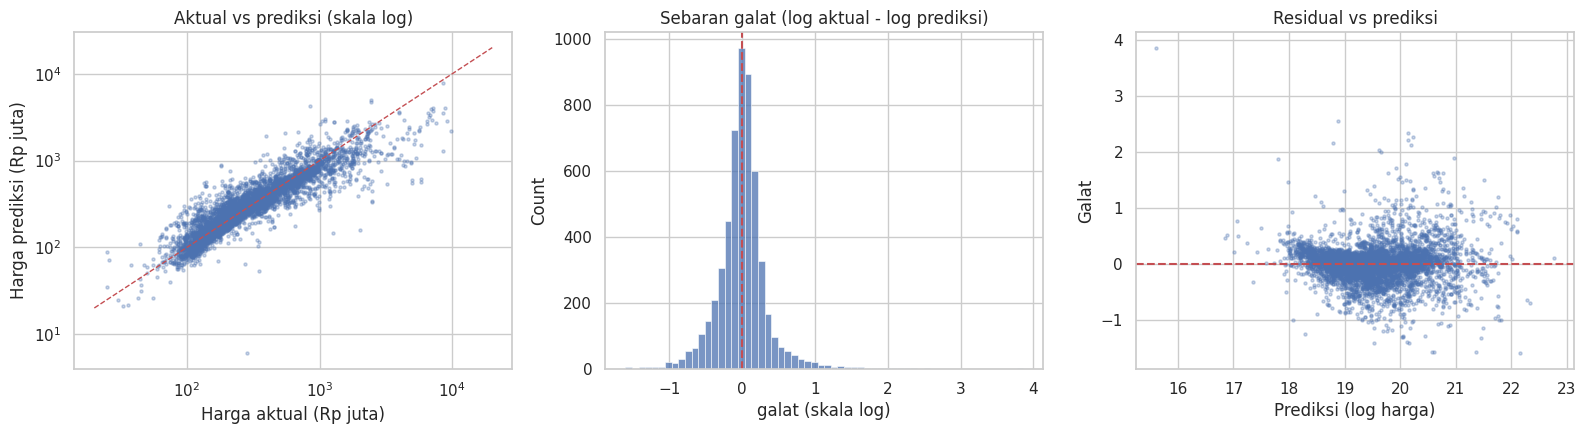

Rata-rata galat (bias, skala log): -0.004
Galat dalam +-20% dari harga aktual: 62.0%
Galat dalam +-30% dari harga aktual: 75.6%


In [104]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].scatter(np.exp(y_uji) / 1e6, np.exp(pred_log) / 1e6, s=5, alpha=0.3)
lim = [20, 20000]
axes[0].plot(lim, lim, "r--", lw=1)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("Harga aktual (Rp juta)"); axes[0].set_ylabel("Harga prediksi (Rp juta)")
axes[0].set_title("Aktual vs prediksi (skala log)")

galat_log = y_uji - pred_log
sns.histplot(galat_log, bins=60, ax=axes[1])
axes[1].axvline(0, color="r", ls="--")
axes[1].set_title("Sebaran galat (log aktual - log prediksi)")
axes[1].set_xlabel("galat (skala log)")

axes[2].scatter(pred_log, galat_log, s=5, alpha=0.3)
axes[2].axhline(0, color="r", ls="--")
axes[2].set_xlabel("Prediksi (log harga)"); axes[2].set_ylabel("Galat")
axes[2].set_title("Residual vs prediksi")
plt.tight_layout(); plt.show()

print("Rata-rata galat (bias, skala log):", round(galat_log.mean(), 3))
print("Galat dalam +-20% dari harga aktual:", f"{(np.abs(np.exp(pred_log)/np.exp(y_uji) - 1) <= 0.20).mean():.1%}")
print("Galat dalam +-30% dari harga aktual:", f"{(np.abs(np.exp(pred_log)/np.exp(y_uji) - 1) <= 0.30).mean():.1%}")

**Grafik Evaluasi**

- **Aktual vs prediksi:** titik mengikuti garis merah (prediksi sempurna) pada harga ratusan juta, lalu **menyimpang ke bawah di harga di atas sekitar Rp 2 miliar**. Ini konsisten dengan contoh Ferrari dan G-Class di atas.
- **Sebaran galat** berpusat dekat nol, dengan rata-rata galat (bias) hanya **-0,004**. Model tidak sistematis terlalu mahal atau terlalu murah secara keseluruhan.
- **Residual vs prediksi:** semakin tinggi prediksi, semakin tidak rata sebaran galatnya, dan galat negatif besar menumpuk di sisi harga tinggi. Ini tanda model linier belum cukup fleksibel.
- **62,0%** prediksi berada dalam ±20% dari harga aktual dan **75,6%** dalam ±30%. Ini angka yang mudah dijelaskan: sekitar tiga dari empat prediksi meleset kurang dari 30%.

#TEMUAN AWAL: di segmen mana baseline lemah?

In [105]:
ev = bersih.loc[X_uji.index, ["brand", "listing__type", "machine_type", "price", "year"]].copy()
ev["prediksi"] = np.exp(pred_log)
ev["ape"] = np.abs(ev["prediksi"] - ev["price"]) / ev["price"] * 100
ev["abs_err_juta"] = np.abs(ev["prediksi"] - ev["price"]) / 1e6
ev["pita_harga"] = pd.cut(ev["price"] / 1e6, [0, 150, 300, 600, 1000, 1e9],
                          labels=["< 150 jt", "150-300 jt", "300-600 jt", "600 jt-1 M", "> 1 M"])

def ringkas_segmen(kolom, minimal=40):
    g = ev.groupby(kolom, observed=True).agg(jumlah=("ape", "size"), MAPE=("ape", "mean"), MedAPE=("ape", "median"),
                                             MAE_juta=("abs_err_juta", "mean"))
    return g[g["jumlah"] >= minimal].round(1)

print("Galat menurut pita harga:");  display(ringkas_segmen("pita_harga"))
print("Galat menurut status iklan:"); display(ringkas_segmen("listing__type"))
print("Galat menurut transmisi:");     display(ringkas_segmen("machine_type"))
print("Merek dengan MAPE tertinggi (>= 40 data uji):")
display(ringkas_segmen("brand").sort_values("MAPE", ascending=False).head(6))
print("Merek dengan MAPE terendah:")
display(ringkas_segmen("brand").sort_values("MAPE").head(4))

Galat menurut pita harga:


,jumlah,MAPE,MedAPE,MAE_juta
pita_harga,,,,
< 150 jt,1116,29.7,17.5,33.5
150-300 jt,2011,20.4,12.0,43.5
300-600 jt,1298,19.9,13.2,85.0
600 jt-1 M,599,22.9,15.7,179.9
> 1 M,456,36.4,34.1,875.2


Galat menurut status iklan:


,jumlah,MAPE,MedAPE,MAE_juta
listing__type,,,,
Baru,550,38.3,28.3,422.9
Bekas,4930,22.2,13.7,103.4


Galat menurut transmisi:


,jumlah,MAPE,MedAPE,MAE_juta
machine_type,,,,
Automatic,4801,22.5,14.0,145.8
Manual,679,32.7,18.4,62.0


Merek dengan MAPE tertinggi (>= 40 data uji):


,jumlah,MAPE,MedAPE,MAE_juta
brand,,,,
Land Rover,56,64.6,48.0,957.9
Porsche,40,49.2,50.1,1467.1
Lexus,124,43.1,34.7,390.9
Wuling,110,34.8,10.8,57.4
Suzuki,350,31.4,17.3,50.5
Mercedes-Benz,523,27.4,17.1,249.5


Merek dengan MAPE terendah:


,jumlah,MAPE,MedAPE,MAE_juta
brand,,,,
MINI,70,15.8,11.3,106.2
Mitsubishi,268,16.4,10.0,39.9
Honda,752,17.6,12.6,43.1
Volkswagen,44,18.0,11.4,69.9


**Galat per Segmen**

| Segmen | MAPE | Catatan |
|---|---|---|
| Harga Rp 150 sampai 600 juta | sekitar 20% | Segmen terbaik dan terbesar |
| Harga < Rp 150 juta | 29,7% | Selisih rupiah kecil (MAE Rp 33,5 juta), tetapi besar secara persentase |
| Harga > Rp 1 miliar | **36,4%** | MAE Rp 875 juta; segmen paling bermasalah |
| Mobil Baru | **38,3%** | vs Bekas 22,2% |
| Transmisi Manual | 32,7% | vs Automatic 22,5% |
| Merek terburuk | Land Rover 64,6%, Porsche 49,2%, Lexus 43,1% | Merek mewah dan variatif |
| Merek terbaik | MINI 15,8%, Mitsubishi 16,4%, Honda 17,6% | Merek massal yang seragam |

---

## Temuan Awal

**1. Apa yang berhasil?**
- Data dan fitur terbukti mendukung masalah: Linear Regression sederhana menurunkan MAE 54% dari tebakan rata-rata (Rp 296 juta menjadi Rp 135 juta) dan mencapai R² 0,826.
- Model stabil dan tidak overfitting (R² latih 0,823, validasi silang 0,821, uji 0,826); pembagian data representatif.
- Mobil massal (Honda, Mitsubishi) diprediksi baik; 75,6% prediksi meleset kurang dari 30%.

**2. Apa masalah yang ditemukan?**
- Mobil mewah dan supercar diprediksi **jauh terlalu murah** (Ferrari sampai -85%); MAPE di atas Rp 1 miliar mencapai 36,4%.
- Mobil Baru (MAPE 38,3%) dan mobil murah di bawah Rp 150 juta (29,7%) kurang akurat.
- RMSE (Rp 429 juta) sekitar 3,2 kali MAE, didominasi segelintir mobil mewah.
- Data terpusat di Jawa dan 6 iklan berharga lebih dari 5 kali median modelnya hanya ditandai, belum ditangani.

**3. Apa kelemahan baseline?**
- Linear Regression bersifat **aditif dan linier pada skala log**: satu pengaruh umur dan kilometer berlaku sama untuk semua merek, padahal depresiasi Ferrari berbeda dengan Avanza.
- Tidak menangkap **interaksi** antar fitur (umur x merek, kilometer x segmen).
- Sekitar 21% data berstatus `OTHER` pada `model_g` (model jarang), sehingga semuanya diperlakukan sama.

**4. Apa yang perlu diperbaiki pada tahap berikutnya?**
- Coba model non-linier (*Random Forest*, *Gradient Boosting*). Uji validasi silang awal pada milestone 2 sudah menunjukkan *Random Forest* mencapai R² sekitar 0,92, jauh di atas 0,82 milik baseline ini.
- Coba regularisasi (Ridge/Lasso) untuk 104 fitur hasil *one-hot*.
- Tambahkan fitur interaksi atau penanganan khusus segmen mewah dan mobil Baru.
- Tinjau 6 iklan berharga janggal dan pertimbangkan metrik yang tidak didominasi mobil mewah (MAPE, MedAE).
- Evaluasi ulang per segmen pada setiap model baru agar perbaikan tidak hanya terlihat di rata-rata.

# MILESTONE PERTEMUAN 4: Dari Baseline Menuju Kandidat Model

Alur pertemuan ini: **Baseline (Linear Regression) → Kandidat Model → Evaluasi → Perbandingan Awal.**
Jenis masalah tetap **Regression** (target `log(price)`), dan model final **belum** diputuskan.

## 4. Kandidat Model

| Kandidat | Alasan pemilihan (berdasarkan temuan milestone 3) |
|---|---|
| **Ridge** | Setelah *one-hot*, fitur menjadi 104 kolom. Regularisasi L2 menguji apakah baseline terganggu oleh banyaknya fitur atau multikolinearitas (umur dan kilometer berkorelasi -0,68). |
| **Lasso** | Regularisasi L1 sekaligus seleksi fitur: koefisien fitur yang tidak berguna menjadi nol. Berguna untuk melihat apakah 104 fitur memang diperlukan. |
| **Polynomial (derajat 2) + Ridge** | Baseline linier tidak menangkap hubungan lengkung dan interaksi (umur x kilometer x mesin). Polynomial menambah suku kuadrat dan interaksi pada fitur numerik. Sesuai contoh materi. |
| **Random Forest** | Kelemahan baseline adalah galat besar pada mobil mewah dan mobil Baru. Model non-linier berbasis pohon menangkap interaksi tanpa perlu menentukan bentuk rumusnya. |

Semua model memakai praproses yang sama (imputasi, scaling, *one-hot*), data latih dan uji yang sama, serta fungsi `evaluasi` yang sama dari milestone 3, sehingga perbandingannya adil.

# Persiapan pembanding (baseline dipertahankan)

In [106]:
import time
from sklearn.linear_model import Ridge, Lasso, RidgeCV, LassoCV
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import RandomForestRegressor

hasil_semua = {}
prediksi_semua = {}
info_tambahan = {}

def jalankan_model(nama, estimator, catatan=""):
    """Latih di data latih, evaluasi di data uji, hitung R2 latih dan R2 validasi silang (5-fold, hanya data latih)."""
    t0 = time.time()
    estimator.fit(X_latih, y_latih)
    waktu = time.time() - t0
    pred = estimator.predict(X_uji)
    hasil_semua[nama] = evaluasi(nama, y_uji, pred)
    prediksi_semua[nama] = pred
    cv = cross_val_score(estimator, X_latih, y_latih, cv=KFold(5, shuffle=True, random_state=42), scoring="r2", n_jobs=-1)
    info_tambahan[nama] = {"R2 latih": estimator.score(X_latih, y_latih), "R2 CV (latih)": cv.mean(),
                           "R2 uji": hasil_semua[nama]["R2 (skala log)"], "waktu latih (detik)": waktu}
    print(f"{nama}: MAE = Rp {hasil_semua[nama]['MAE (Rp juta)']:.1f} juta | RMSE = Rp {hasil_semua[nama]['RMSE (Rp juta)']:.1f} juta | "
          f"R2 uji = {info_tambahan[nama]['R2 uji']:.3f} | R2 latih = {info_tambahan[nama]['R2 latih']:.3f} | {waktu:.1f} detik {catatan}")
    return estimator

hasil_semua["Linear Regression (baseline)"] = hasil_lr
prediksi_semua["Linear Regression (baseline)"] = pred_log
info_tambahan["Linear Regression (baseline)"] = {"R2 latih": baseline.score(X_latih, y_latih), "R2 CV (latih)": cv_r2.mean(),
                                                  "R2 uji": hasil_lr["R2 (skala log)"], "waktu latih (detik)": np.nan}
print("Baseline: MAE = Rp", round(hasil_lr["MAE (Rp juta)"], 1), "juta | RMSE = Rp", round(hasil_lr["RMSE (Rp juta)"], 1),
      "juta | R2 uji =", round(hasil_lr["R2 (skala log)"], 3))

Baseline: MAE = Rp 135.4 juta | RMSE = Rp 429.0 juta | R2 uji = 0.826


# KANDIDAT 1: Ridge Regression (regularisasi L2)

In [107]:
ridge = Pipeline([("pra", buat_praproses(FITUR_NUM, FITUR_KAT)),
                  ("model", RidgeCV(alphas=[0.01, 0.1, 1, 10, 30, 100]))])
jalankan_model("Ridge", ridge)
print("alpha terpilih (validasi silang internal):", ridge.named_steps["model"].alpha_)

Ridge: MAE = Rp 135.4 juta | RMSE = Rp 429.0 juta | R2 uji = 0.826 | R2 latih = 0.823 | 0.6 detik 
alpha terpilih (validasi silang internal): 0.1


**Ridge**

- Hasil Ridge **identik dengan baseline**: MAE Rp 135,4 juta, RMSE Rp 429,0 juta, R² 0,826. Alpha terpilih hanya 0,1 (regularisasi sangat lemah).
- Artinya baseline **tidak bermasalah karena terlalu banyak fitur atau multikolinearitas**. Dengan 21.919 baris latih dan 104 fitur, Linear Regression sudah stabil, sehingga hukuman L2 tidak memberi keuntungan.
- Kesimpulan: kelemahan baseline bukan di sisi *overfitting*, melainkan di **kemampuan model menangkap pola** (underfitting). Perbaikan perlu datang dari model yang lebih ekspresif, bukan dari regularisasi.

# KANDIDAT 2: Lasso Regression (regularisasi L1, sekaligus seleksi fitur)

In [108]:
lasso = Pipeline([("pra", buat_praproses(FITUR_NUM, FITUR_KAT)),
                  ("model", LassoCV(alphas=[1e-4, 3e-4, 1e-3, 3e-3, 1e-2], cv=5, max_iter=5000, random_state=42))])
jalankan_model("Lasso", lasso)
koef = lasso.named_steps["model"].coef_
nama_fitur = lasso.named_steps["pra"].get_feature_names_out()
print("alpha terpilih:", lasso.named_steps["model"].alpha_)
print("Koefisien bernilai nol:", int((koef == 0).sum()), "dari", len(koef), "fitur")
print("\nKoefisien fitur numerik dan biner:")
display(pd.Series(koef, index=nama_fitur).loc[lambda s: s.index.str.startswith(("num", "bin"))].round(3).to_frame("koefisien"))

Lasso: MAE = Rp 135.9 juta | RMSE = Rp 428.9 juta | R2 uji = 0.826 | R2 latih = 0.822 | 5.3 detik 
alpha terpilih: 0.0001
Koefisien bernilai nol: 5 dari 104 fitur

Koefisien fitur numerik dan biner:


,koefisien
num__umur,-0.264
num__km_sqrt,-0.166
num__engine,0.371
bin__is_baru,0.084
bin__is_matic,0.220


**Lasso**

- Hasil Lasso juga **hampir sama dengan baseline**: MAE Rp 135,9 juta (naik 0,4%), RMSE Rp 428,9 juta, R² 0,826.
- Alpha terpilih 0,0001 adalah nilai **terkecil di grid**, artinya validasi silang menginginkan regularisasi seminimal mungkin. Hanya **5 dari 104 koefisien menjadi nol**, jadi hampir semua fitur memang berguna.
- Arah koefisien sesuai logika harga: **kapasitas mesin** paling kuat positif (+0,371 per simpangan baku), **umur** negatif (-0,264), **kilometer** negatif (-0,166). Transmisi matic menaikkan log harga 0,220 (sekitar +25%) dan status Baru 0,084 (sekitar +9%), dengan fitur lain tetap.
- Seperti Ridge, Lasso tidak mengatasi kelemahan baseline di mobil mewah.

# KANDIDAT 3: Polynomial Regression (derajat 2 pada fitur numerik) + Ridge

In [109]:
pra_poly = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                      ("poly", PolynomialFeatures(degree=2, include_bias=False))]), FITUR_NUM),
    ("bin", "passthrough", FITUR_BIN),
    ("kat", OneHotEncoder(handle_unknown="ignore"), FITUR_KAT),
])
poly = Pipeline([("pra", pra_poly), ("model", RidgeCV(alphas=[0.01, 0.1, 1, 10, 30, 100]))])
jalankan_model("Polynomial (deg 2) + Ridge", poly)
print("Fitur numerik 3 menjadi", pra_poly.fit(X_latih).named_transformers_["num"].named_steps["poly"].n_output_features_,
      "fitur (asli + kuadrat + interaksi)")
print("alpha terpilih:", poly.named_steps["model"].alpha_)

Polynomial (deg 2) + Ridge: MAE = Rp 126.3 juta | RMSE = Rp 395.7 juta | R2 uji = 0.847 | R2 latih = 0.846 | 1.7 detik 
Fitur numerik 3 menjadi 9 fitur (asli + kuadrat + interaksi)
alpha terpilih: 0.1


**Polynomial (derajat 2) + Ridge**

- Tiga fitur numerik (umur, kilometer, mesin) menjadi 9 fitur: aslinya, kuadratnya, dan interaksi antar pasangan.
- Ada **perbaikan nyata tetapi sedang**: MAE turun dari Rp 135,4 juta menjadi **Rp 126,3 juta (-6,8%)**, RMSE dari Rp 429,0 juta menjadi **Rp 395,7 juta (-7,8%)**, R² naik dari 0,826 menjadi **0,847**. R² validasi silang 0,844 dan uji 0,847, jadi perbaikannya stabil.
- Ini membuktikan hubungan harga dengan umur, kilometer, dan mesin **tidak sepenuhnya linier**. Namun polynomial hanya mengubah bentuk hubungan numerik; interaksi dengan **merek dan model** (misalnya depresiasi Ferrari vs Avanza) tetap tidak tertangkap.

# KANDIDAT 4: Random Forest Regressor (non-linier, menangkap interaksi)


In [110]:
rf = Pipeline([("pra", buat_praproses(FITUR_NUM, FITUR_KAT)),
               ("model", RandomForestRegressor(n_estimators=100, max_depth=16, min_samples_leaf=2, n_jobs=-1, random_state=42))])
jalankan_model("Random Forest", rf)

# fitur penting
nama_fitur_rf = rf.named_steps["pra"].get_feature_names_out()
pent = pd.Series(rf.named_steps["model"].feature_importances_, index=nama_fitur_rf).sort_values(ascending=False)
display(pent.head(8).round(3).to_frame("kepentingan"))

Random Forest: MAE = Rp 83.7 juta | RMSE = Rp 299.7 juta | R2 uji = 0.917 | R2 latih = 0.961 | 29.1 detik 


,kepentingan
num__engine,0.479
num__km_sqrt,0.285
num__umur,0.080
bin__is_matic,0.026
kat__body_g_MPV,0.014
kat__model_g_Toyota Alphard,0.011
kat__model_g_OTHER,0.009
kat__model_g_Toyota Kijang,0.007


**Random Forest**

- Ini kandidat dengan hasil **paling berbeda**: MAE turun menjadi **Rp 83,7 juta (-38,2%)**, RMSE menjadi **Rp 299,7 juta (-30,1%)**, R² naik menjadi **0,917** (baseline 0,826).
- **Tanda overfitting sedang**: R² latih 0,961, validasi silang 0,922, uji 0,917. Selisih latih-uji sekitar 0,04, tetapi validasi silang dan uji hampir sama, sehingga kemampuan generalisasi tetap konsisten. Parameter (`max_depth=16`, `min_samples_leaf=2`) belum di-*tuning*.
- Fitur terpenting: **kapasitas mesin (0,479)**, **kilometer (0,285)**, dan **umur (0,080)**. Urutan ini sama dengan temuan EDA dan uji ablation milestone 2, sehingga hasil model konsisten dengan data.
- Biaya: training sekitar 28 detik (baseline di bawah 1 detik) dan model sulit ditafsirkan dibanding koefisien regresi.

## 6. Perbandingan Model

Seluruh model dievaluasi pada **data uji yang sama** (5.480 baris) dengan metrik yang sama. Perubahan dihitung relatif terhadap baseline.

PERBANDINGAN: seluruh model pada data uji

In [111]:
urut_target = ["Linear Regression (baseline)", "Ridge", "Lasso", "Polynomial (deg 2) + Ridge", "Random Forest"]
urut = [k for k in urut_target if k in hasil_semua]

if not urut:
    print("Error: Belum ada model yang terdaftar di 'hasil_semua'. Pastikan Anda sudah menjalankan sel pelatihan model terlebih dahulu.")
else:
    tabel = pd.DataFrame([hasil_semua[k] for k in urut]).set_index("model")
    tabel = tabel[["MAE (Rp juta)", "RMSE (Rp juta)", "MedAE (Rp juta)", "MAPE (%)", "R2 (skala log)"]]
    display(tabel.round(3))

    if "Linear Regression (baseline)" in tabel.index:
        dasar = tabel.loc["Linear Regression (baseline)"]
        perubahan = ((tabel - dasar) / dasar * 100).round(1)
        perubahan["R2 (skala log)"] = (tabel["R2 (skala log)"] - dasar["R2 (skala log)"]).round(3)
        perubahan = perubahan.rename(columns={"R2 (skala log)": "selisih R2"})
        print("\nPerubahan terhadap baseline (% untuk MAE, RMSE, MedAE, MAPE; selisih mutlak untuk R2):")
        display(perubahan)

    info_tersedia = [k for k in urut if k in info_tambahan]
    if info_tersedia:
        display(pd.DataFrame(info_tambahan).T.loc[info_tersedia].round(3))

,MAE (Rp juta),RMSE (Rp juta),MedAE (Rp juta),MAPE (%),R2 (skala log)
model,,,,,
Linear Regression (baseline),135.422,429.003,37.390,23.798,0.826
Ridge,135.427,428.999,37.435,23.798,0.826
Lasso,135.911,428.863,37.863,23.841,0.826
Polynomial (deg 2) + Ridge,126.256,395.670,33.746,21.844,0.847
Random Forest,83.725,299.702,17.259,13.237,0.917



Perubahan terhadap baseline (% untuk MAE, RMSE, MedAE, MAPE; selisih mutlak untuk R2):


,MAE (Rp juta),RMSE (Rp juta),MedAE (Rp juta),MAPE (%),selisih R2
model,,,,,
Linear Regression (baseline),0.0,0.0,0.0,0.0,0.000
Ridge,0.0,-0.0,0.1,0.0,0.000
Lasso,0.4,-0.0,1.3,0.2,-0.000
Polynomial (deg 2) + Ridge,-6.8,-7.8,-9.7,-8.2,0.021
Random Forest,-38.2,-30.1,-53.8,-44.4,0.091


,R2 latih,R2 CV (latih),R2 uji,waktu latih (detik)
Linear Regression (baseline),0.823,0.821,0.826,NaN
Ridge,0.823,0.821,0.826,0.607
Lasso,0.822,0.821,0.826,5.299
Polynomial (deg 2) + Ridge,0.846,0.844,0.847,1.667
Random Forest,0.961,0.922,0.917,29.108


In [112]:
print("Model yang sudah tersimpan:", list(hasil_semua.keys()), "\n")

pra_poly = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                      ("poly", PolynomialFeatures(degree=2, include_bias=False))]), FITUR_NUM),
    ("bin", "passthrough", FITUR_BIN),
    ("kat", OneHotEncoder(handle_unknown="ignore"), FITUR_KAT),
])
kandidat = {
    "Ridge": Pipeline([("pra", buat_praproses(FITUR_NUM, FITUR_KAT)),
                       ("model", RidgeCV(alphas=[0.01, 0.1, 1, 10, 30, 100]))]),
    "Lasso": Pipeline([("pra", buat_praproses(FITUR_NUM, FITUR_KAT)),
                       ("model", LassoCV(alphas=[1e-4, 3e-4, 1e-3, 3e-3, 1e-2], cv=5, max_iter=5000, random_state=42))]),
    "Polynomial (deg 2) + Ridge": Pipeline([("pra", pra_poly),
                                            ("model", RidgeCV(alphas=[0.01, 0.1, 1, 10, 30, 100]))]),
    "Random Forest": Pipeline([("pra", buat_praproses(FITUR_NUM, FITUR_KAT)),
                               ("model", RandomForestRegressor(n_estimators=100, max_depth=16, min_samples_leaf=2,
                                                               n_jobs=-1, random_state=42))]),
}
for nama, est in kandidat.items():
    if nama in hasil_semua:
        print("lewati (sudah ada):", nama)
        continue
    jalankan_model(nama, est)

print("\nSekarang tersimpan:", list(hasil_semua.keys()))

Model yang sudah tersimpan: ['Linear Regression (baseline)', 'Ridge', 'Lasso', 'Polynomial (deg 2) + Ridge', 'Random Forest'] 

lewati (sudah ada): Ridge
lewati (sudah ada): Lasso
lewati (sudah ada): Polynomial (deg 2) + Ridge
lewati (sudah ada): Random Forest

Sekarang tersimpan: ['Linear Regression (baseline)', 'Ridge', 'Lasso', 'Polynomial (deg 2) + Ridge', 'Random Forest']


In [113]:
urut = ["Linear Regression (baseline)", "Ridge", "Lasso", "Polynomial (deg 2) + Ridge", "Random Forest"]
tabel = pd.DataFrame([hasil_semua[k] for k in urut]).set_index("model")
tabel = tabel[["MAE (Rp juta)", "RMSE (Rp juta)", "MedAE (Rp juta)", "MAPE (%)", "R2 (skala log)"]]
display(tabel.round(3))

dasar = tabel.loc["Linear Regression (baseline)"]
perubahan = ((tabel - dasar) / dasar * 100).round(1)
perubahan["R2 (skala log)"] = (tabel["R2 (skala log)"] - dasar["R2 (skala log)"]).round(3)
perubahan = perubahan.rename(columns={"R2 (skala log)": "selisih R2"})
print("\nPerubahan terhadap baseline (% untuk MAE, RMSE, MedAE, MAPE; selisih mutlak untuk R2):")
display(perubahan)

display(pd.DataFrame(info_tambahan).T.loc[urut].round(3))

,MAE (Rp juta),RMSE (Rp juta),MedAE (Rp juta),MAPE (%),R2 (skala log)
model,,,,,
Linear Regression (baseline),135.422,429.003,37.390,23.798,0.826
Ridge,135.427,428.999,37.435,23.798,0.826
Lasso,135.911,428.863,37.863,23.841,0.826
Polynomial (deg 2) + Ridge,126.256,395.670,33.746,21.844,0.847
Random Forest,83.725,299.702,17.259,13.237,0.917



Perubahan terhadap baseline (% untuk MAE, RMSE, MedAE, MAPE; selisih mutlak untuk R2):


,MAE (Rp juta),RMSE (Rp juta),MedAE (Rp juta),MAPE (%),selisih R2
model,,,,,
Linear Regression (baseline),0.0,0.0,0.0,0.0,0.000
Ridge,0.0,-0.0,0.1,0.0,0.000
Lasso,0.4,-0.0,1.3,0.2,-0.000
Polynomial (deg 2) + Ridge,-6.8,-7.8,-9.7,-8.2,0.021
Random Forest,-38.2,-30.1,-53.8,-44.4,0.091


,R2 latih,R2 CV (latih),R2 uji,waktu latih (detik)
Linear Regression (baseline),0.823,0.821,0.826,NaN
Ridge,0.823,0.821,0.826,0.607
Lasso,0.822,0.821,0.826,5.299
Polynomial (deg 2) + Ridge,0.846,0.844,0.847,1.667
Random Forest,0.961,0.922,0.917,29.108


**Hasil Perbandingan (data uji)**

| Model | MAE (Rp juta) | RMSE (Rp juta) | MedAE (Rp juta) | MAPE (%) | R² (log) | R² latih | R² CV |
|---|---|---|---|---|---|---|---|
| Linear Regression (baseline) | 135,4 | 429,0 | 37,4 | 23,8 | 0,826 | 0,823 | 0,821 |
| Ridge | 135,4 | 429,0 | 37,4 | 23,8 | 0,826 | 0,823 | 0,821 |
| Lasso | 135,9 | 428,9 | 37,9 | 23,8 | 0,826 | 0,822 | 0,821 |
| Polynomial (deg 2) + Ridge | 126,3 | 395,7 | 33,7 | 21,8 | 0,847 | 0,846 | 0,844 |
| **Random Forest** | **83,7** | **299,7** | **17,3** | **13,2** | **0,917** | 0,961 | 0,922 |

**Insight**

1. Ridge dan Lasso **tidak berbeda** dari baseline (selisih di bawah 0,5%). Regularisasi tidak menyelesaikan masalah.
2. Polynomial memberi perbaikan **sedang** (MAE -6,8%, R² +0,021), sedangkan Random Forest memberi perbaikan **besar**: MAE -38,2%, MedAE -53,8%, MAPE turun dari 23,8% menjadi 13,2%, R² +0,091.
3. Median galat Random Forest (MedAE) hanya **Rp 17,3 juta**, sedangkan baseline Rp 37,4 juta: separuh lebih kecil untuk mobil tipikal.
4. Random Forest paling lambat dan punya selisih R² latih-uji terbesar (0,961 vs 0,917), meski validasi silang (0,922) menunjukkan hasilnya konsisten.

PERBANDINGAN: grafik

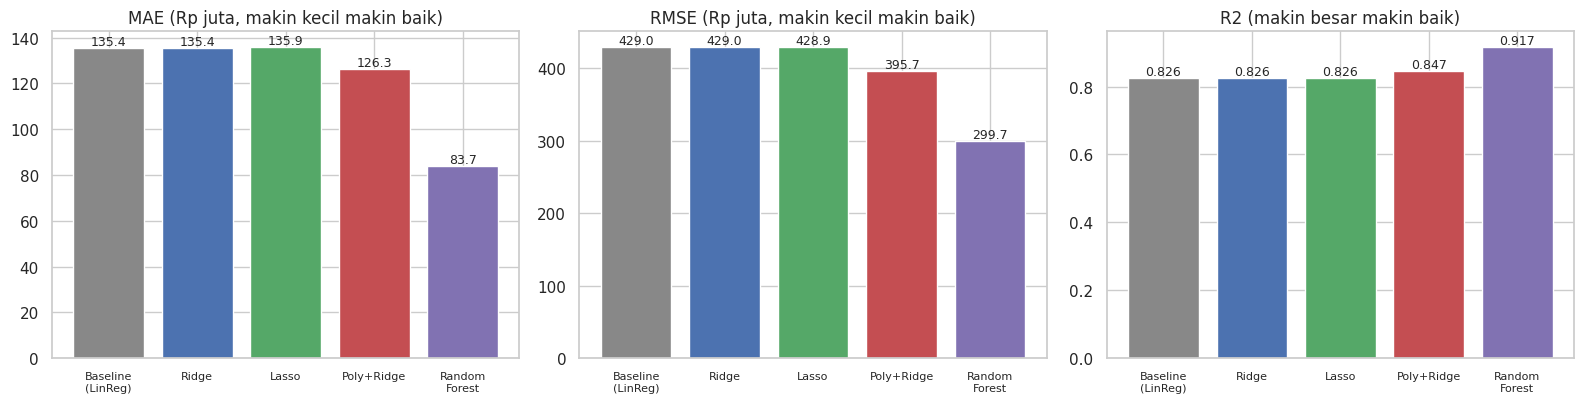

In [114]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
nama_pendek = ["Baseline\n(LinReg)", "Ridge", "Lasso", "Poly+Ridge", "Random\nForest"]
warna = ["#888888", "#4C72B0", "#55A868", "#C44E52", "#8172B2"]
for ax, kolom, judul in zip(axes, ["MAE (Rp juta)", "RMSE (Rp juta)", "R2 (skala log)"],
                            ["MAE (Rp juta, makin kecil makin baik)", "RMSE (Rp juta, makin kecil makin baik)", "R2 (makin besar makin baik)"]):
    nilai = tabel[kolom].values
    ax.bar(nama_pendek, nilai, color=warna)
    for i, v in enumerate(nilai):
        ax.text(i, v, f"{v:.1f}" if "R2" not in kolom else f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(judul)
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

**Grafik**

Tiga model linier (baseline, Ridge, Lasso) menghasilkan batang yang hampir sama tinggi pada MAE, RMSE, dan R². Polynomial sedikit lebih baik, dan **Random Forest menonjol** pada ketiganya. Pola ini menunjukkan batas performa model linier: menambah regularisasi tidak membantu, sedangkan menambah kemampuan non-linier membantu.

# ERROR ANALYSIS RINGAN: apakah kelemahan baseline di segmen mewah dan mobil Baru membaik?

In [115]:
ev4 = bersih.loc[X_uji.index, ["listing__type", "price", "brand"]].copy()
ev4["pita_harga"] = pd.cut(ev4["price"] / 1e6, [0, 150, 300, 600, 1000, 1e9],
                           labels=["< 150 jt", "150-300 jt", "300-600 jt", "600 jt-1 M", "> 1 M"])
for nama in urut:
    ev4[nama] = np.abs(np.exp(prediksi_semua[nama]) - ev4["price"]) / ev4["price"] * 100

print("MAPE (%) per pita harga:")
display(ev4.groupby("pita_harga", observed=True)[urut].mean().round(1).assign(jumlah=ev4.groupby("pita_harga", observed=True).size()))
print("MAPE (%) per status iklan:")
display(ev4.groupby("listing__type")[urut].mean().round(1))

contoh = ev4.nlargest(5, "price")[["brand", "price"]].copy()
for nama in ["Linear Regression (baseline)", "Random Forest"]:
    contoh[nama] = (np.exp(prediksi_semua[nama][X_uji.index.get_indexer(contoh.index)]) / 1e6).round(0)
contoh["price"] = (contoh["price"] / 1e6).round(0)
print("\nLima mobil termahal pada data uji (Rp juta):")
display(contoh.rename(columns={"price": "aktual"}))

MAPE (%) per pita harga:


,Linear Regression (baseline),Ridge,Lasso,Polynomial (deg 2) + Ridge,Random Forest,jumlah
pita_harga,,,,,,
< 150 jt,29.7,29.7,29.4,25.9,11.1,1116
150-300 jt,20.4,20.4,20.6,17.6,10.7,2011
300-600 jt,19.9,19.9,19.9,20.1,14.3,1298
600 jt-1 M,22.9,22.9,23.2,22.9,15.6,599
> 1 M,36.4,36.4,36.7,34.2,23.5,456


MAPE (%) per status iklan:


,Linear Regression (baseline),Ridge,Lasso,Polynomial (deg 2) + Ridge,Random Forest
listing__type,,,,,
Baru,38.3,38.3,38.4,35.0,22.2
Bekas,22.2,22.2,22.2,20.4,12.2



Lima mobil termahal pada data uji (Rp juta):


,brand,aktual,Linear Regression (baseline),Random Forest
20145,Ferrari,9800.0,2202.0,2526.0
26179,Porsche,9200.0,2817.0,7233.0
11477,Lamborghini,8800.0,3999.0,3122.0
15615,Lamborghini,8550.0,7750.0,3751.0
7773,Ferrari,8500.0,1280.0,4679.0


**Galat per Segmen (MAPE %)**

| Segmen | Baseline | Polynomial | Random Forest |
|---|---|---|---|
| Harga < Rp 150 juta | 29,7 | 25,9 | **11,1** |
| Rp 150 sampai 300 juta | 20,4 | 17,6 | **10,7** |
| Rp 300 sampai 600 juta | 19,9 | 20,1 | **14,3** |
| Rp 600 juta sampai 1 miliar | 22,9 | 22,9 | **15,6** |
| Harga > Rp 1 miliar | 36,4 | 34,2 | **23,5** |
| Mobil Baru | 38,3 | 35,0 | **22,2** |
| Mobil Bekas | 22,2 | 20,4 | **12,2** |

- Random Forest memperbaiki **semua segmen**, terbesar pada mobil murah (29,7% menjadi 11,1%) dan mobil Baru (38,3% menjadi 22,2%), dua kelemahan baseline di milestone 3.
- Polynomial tidak membantu pada segmen Rp 300 juta ke atas (hampir sama dengan baseline), sehingga perbaikannya terutama di segmen murah.
- **Segmen mewah (> Rp 1 miliar) tetap yang terlemah** (MAPE 23,5%). Pada lima mobil termahal, Random Forest memperbaiki Porsche (Rp 9,2 miliar: baseline Rp 2,8 miliar, RF Rp 7,2 miliar) dan Ferrari 488 (Rp 8,5 miliar: Rp 1,3 miliar menjadi Rp 4,7 miliar), tetapi Ferrari 296 GTB masih diprediksi Rp 2,5 miliar (aktual Rp 9,8 miliar) dan Lamborghini Rp 8,8 miliar justru lebih dekat pada baseline (Rp 4,0 miliar) dibanding RF (Rp 3,1 miliar). Mobil super mewah jumlahnya sedikit sehingga sulit dipelajari model mana pun.

## 7. Temuan Awal

1. **Model yang memberi hasil berbeda: Random Forest.** MAE turun 38,2% (Rp 135,4 juta menjadi Rp 83,7 juta), R² naik dari 0,826 menjadi 0,917. Polynomial memberi perbaikan sedang (R² 0,847), sedangkan Ridge dan Lasso tidak berbeda dari baseline. Perbaikan datang dari **kemampuan menangkap pola non-linier dan interaksi**, bukan dari regularisasi.
2. **Metrik paling informatif: MedAE dan MAPE, dilengkapi R² dan analisis per segmen.** RMSE dan MAE dalam rupiah didominasi segelintir mobil mewah (RMSE Random Forest masih 3,6 kali MAE-nya). MedAE (Rp 17,3 juta) dan MAPE (13,2%) lebih mewakili mobil tipikal, sedangkan MAPE per segmen menunjukkan di mana model lemah.
3. **Masalah yang ditemukan.** Segmen mobil mewah (> Rp 1 miliar) masih memiliki MAPE 23,5% dan beberapa supercar diprediksi jauh di bawah harga aktual. Random Forest juga menunjukkan *overfitting* sedang (R² latih 0,961 vs uji 0,917), dan data terpusat di Pulau Jawa.
4. **Yang perlu diperbaiki berikutnya.** (a) *Tuning* Random Forest (`max_depth`, `min_samples_leaf`, `n_estimators`) dengan validasi silang untuk menekan *overfitting*; (b) coba *Gradient Boosting* sebagai kandidat berikutnya; (c) *error analysis* mendalam pada segmen mewah dan mobil Baru; (d) periksa 6 iklan berharga janggal (> 5x median model) yang baru ditandai.

### Kelebihan dan kelemahan tiap model

| Model | Kelebihan | Kelemahan |
|---|---|---|
| Linear Regression (baseline) | Sederhana, cepat (< 1 detik), koefisien mudah ditafsirkan, tidak overfit | Hanya hubungan linier dan aditif; galat besar pada mobil mewah dan mobil Baru |
| Ridge | Stabil, tahan multikolinearitas | Tidak lebih baik dari baseline pada data ini |
| Lasso | Bisa menyeleksi fitur dan hasilnya tetap mudah dibaca | Hanya 5 dari 104 fitur dibuang; tidak ada peningkatan akurasi |
| Polynomial + Ridge | Menangkap lengkungan dan interaksi numerik, perbaikan stabil | Perbaikan hanya sedang; tidak menangkap interaksi dengan merek/model |
| Random Forest | Akurasi tertinggi, menangkap interaksi, tidak perlu transformasi manual | Lebih lambat, kurang mudah ditafsirkan, ada *overfitting* sedang, belum di-*tuning* |

**Catatan.** Model final belum diputuskan. Perbandingan ini memakai satu pembagian data latih-uji, dan hasil Random Forest belum melalui *tuning*. Keputusan final dilakukan setelah validasi, *error analysis*, dan *tuning* pada tahap berikutnya.

# MILESTONE PERTEMUAN 5: Dari Perbandingan Model Menuju Validasi

Alur: **Baseline → Kandidat Model → Validasi → Ensemble → Diagnosis Awal.** Jenis masalah tetap **Regression**.

Tiga pertanyaan yang dijawab pada pertemuan ini:
1. Apakah performa model **stabil** ketika pembagian data berubah? (Tugas 1 dan 2)
2. Apakah **ensemble learning** meningkatkan performa dibandingkan model awal? (Tugas 3)
3. Apakah distribusi kelas memengaruhi evaluasi? **Tidak relevan**: target `price` bersifat numerik kontinu, bukan kelas, sehingga sesuai arahan slide, fokus pada dua pertanyaan pertama. Tugas 4 (imbalanced data) tidak dikerjakan.

Metrik: **MAE** dan **RMSE** (Rp juta, setelah dikembalikan dari `log(price)`), ditambah MAPE dan R².

# TUGAS 1: Audit Strategi Validasi

| Pertanyaan audit | Jawaban |
|---|---|
| Bagaimana data dibagi menjadi training dan testing? | *Hold-out* acak 80% latih (21.919) dan 20% test (5.480), `random_state=42`. |
| Apakah validation set diperlukan untuk tuning? | Tidak dipisah. Fungsi validation dijalankan oleh **5-Fold Cross-Validation di dalam data latih**, sehingga test set tetap tersembunyi. |
| Apakah pembagian sesuai jenis masalah? | Ya. Regresi dengan data iid memakai `KFold` acak (bukan `StratifiedKFold`, yang untuk klasifikasi). Tidak ada kolom waktu atau ID grup, sehingga `TimeSeriesSplit` dan `GroupKFold` tidak bisa dipakai. |
| Apakah preprocessing dipelajari hanya dari data training? | **Hampir seluruhnya.** Imputasi median, scaling, dan *one-hot* ada di dalam `Pipeline`. **Temuan audit:** pengelompokan kategori jarang (`gabung_jarang`) dihitung dari seluruh data sebelum split (hanya memakai frekuensi, bukan harga). Dampaknya diuji di bawah. |
| Apakah test set sudah dipakai berulang untuk memilih model? | Test set dipakai di milestone 4 untuk **membandingkan** 5 model (tanpa tuning). Untuk milestone 5, pemilihan model memakai CV pada data latih, dan test hanya dipakai **sekali** di akhir sebagai konfirmasi. |

In [116]:
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import time

kunci = ["brand", "brand_type", "year", "KM_1", "price", "location", "machine_type"]
gabungan = bersih.loc[X_latih.index.union(X_uji.index)]
audit = pd.DataFrame({
    "Pertanyaan audit": [
        "Jumlah data latih / uji",
        "Rasio pembagian",
        "Irisan indeks latih-uji",
        "Duplikat 7 kolom kunci di seluruh data",
        "Praproses (imputasi, scaling, one-hot) ada di dalam Pipeline?",
        "Kolom waktu / ID grup tersedia?"],
    "Hasil": [
        f"{len(X_latih):,} / {len(X_uji):,}",
        f"{len(X_latih)/len(X):.0%} / {len(X_uji)/len(X):.0%} (acak, random_state=42)",
        len(set(X_latih.index) & set(X_uji.index)),
        int(gabungan.duplicated(kunci).sum()),
        "Ya (ColumnTransformer di dalam Pipeline)",
        "Tidak ada -> tidak bisa memakai TimeSeriesSplit / GroupKFold"],
})
display(audit)

def kategori_aman(s, ambang):
    persen = s.value_counts(normalize=True) * 100
    return set(persen[persen >= ambang].index)

for kolom, ambang in [("model", 0.3), ("location", 1.0), ("body_type", 1.0)]:
    penuh = kategori_aman(bersih[kolom], ambang)
    latih = kategori_aman(bersih.loc[X_latih.index, kolom], ambang)
    print(f"{kolom:10s}: kategori 'aman' dari seluruh data = {len(penuh)}, dari data latih saja = {len(latih)}, "
          f"berbeda = {len(penuh ^ latih)}")

,Pertanyaan audit,Hasil
0,Jumlah data latih / uji,"21,919 / 5,480"
1,Rasio pembagian,"80% / 20% (acak, random_state=42)"
2,Irisan indeks latih-uji,0
3,Duplikat 7 kolom kunci di seluruh data,0
4,"Praproses (imputasi, scaling, one-hot) ada di ...",Ya (ColumnTransformer di dalam Pipeline)
5,Kolom waktu / ID grup tersedia?,Tidak ada -> tidak bisa memakai TimeSeriesSpli...


model     : kategori 'aman' dari seluruh data = 83, dari data latih saja = 83, berbeda = 2
location  : kategori 'aman' dari seluruh data = 6, dari data latih saja = 6, berbeda = 0
body_type : kategori 'aman' dari seluruh data = 7, dari data latih saja = 6, berbeda = 1


# TUGAS 1: DIAGRAM PEMBAGIAN DATA

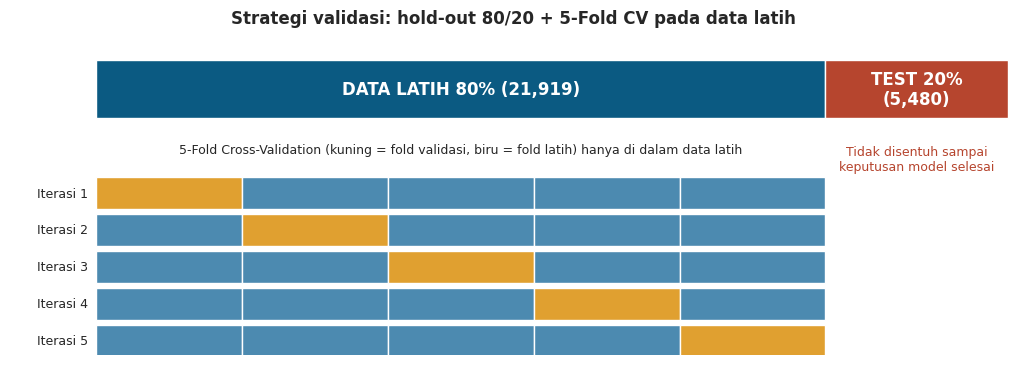

In [117]:
fig, ax = plt.subplots(figsize=(13, 4.2))
n_latih, n_uji = len(X_latih), len(X_uji)
ax.barh(2.6, n_latih, color="#0B5A82", height=0.5)
ax.barh(2.6, n_uji, left=n_latih, color="#B6452E", height=0.5)
ax.text(n_latih/2, 2.6, f"DATA LATIH 80% ({n_latih:,})", ha="center", va="center", color="white", fontweight="bold")
ax.text(n_latih+n_uji/2, 2.6, f"TEST 20%\n({n_uji:,})", ha="center", va="center", color="white", fontweight="bold")
lebar = n_latih / 5
for i in range(5):
    for j in range(5):
        warna = "#E0A030" if i == j else "#4C8AB0"
        ax.barh(1.7 - i*0.32, lebar, left=j*lebar, color=warna, edgecolor="white", height=0.28)
    ax.text(-250, 1.7 - i*0.32, f"Iterasi {i+1}", ha="right", va="center", fontsize=9)
ax.text(n_latih/2, 2.05, "5-Fold Cross-Validation (kuning = fold validasi, biru = fold latih) hanya di dalam data latih",
        ha="center", fontsize=9)
ax.text(n_latih+n_uji/2, 1.9, "Tidak disentuh sampai\nkeputusan model selesai", ha="center", fontsize=9, color="#B6452E")
ax.set_xlim(-2600, len(X)+300); ax.set_ylim(0.3, 3.1); ax.axis("off")
ax.set_title("Strategi validasi: hold-out 80/20 + 5-Fold CV pada data latih", fontweight="bold")
plt.show()

# TUGAS 1: apakah 5 fold seimbang? (regresi memakai KFold acak, bukan Stratified)

In [118]:
kf5 = KFold(n_splits=5, shuffle=True, random_state=42)
baris = []
for i, (tr, va) in enumerate(kf5.split(X_latih), 1):
    harga_va = np.exp(y_latih.iloc[va]) / 1e6
    baris.append({"fold": i, "n validasi": len(va), "median harga (Rp juta)": harga_va.median(),
                  "% Baru": X_latih.iloc[va]["is_baru"].mean() * 100,
                  "% harga > 1 miliar": (harga_va > 1000).mean() * 100,
                  "% Automatic": X_latih.iloc[va]["is_matic"].mean() * 100})
tabel_fold = pd.DataFrame(baris).set_index("fold")
display(tabel_fold.round(2))
print("Simpangan baku antar fold:")
display(tabel_fold.std().round(2).to_frame("std").T)

,n validasi,median harga (Rp juta),% Baru,% harga > 1 miliar,% Automatic
fold,,,,,
1,4384,245.0,9.83,8.19,87.50
2,4384,259.0,10.40,8.35,88.41
3,4384,255.0,10.17,9.03,87.89
4,4384,255.0,9.01,7.78,88.02
5,4383,250.0,10.70,8.44,88.50


Simpangan baku antar fold:


,n validasi,median harga (Rp juta),% Baru,% harga > 1 miliar,% Automatic
std,0.45,5.4,0.65,0.45,0.41


# TUGAS 1: uji dampak temuan audit (pengelompokan kategori jarang di dalam Pipeline, tanpa kebocoran)

In [119]:
fitur_mentah = ["umur", "km_sqrt", "engine", "is_baru", "is_matic", "model", "location", "body_type"]
Xm_latih, Xm_uji = bersih.loc[X_latih.index, fitur_mentah], bersih.loc[X_uji.index, fitur_mentah]

def praproses_bersih(dense=False):
    """Kategori jarang digabung OLEH ENCODER pada data latih tiap fold (min_frequency), bukan dari seluruh data."""
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), ["umur", "km_sqrt", "engine"]),
        ("bin", "passthrough", ["is_baru", "is_matic"]),
        ("mdl", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.003, sparse_output=not dense), ["model"]),
        ("lok", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=not dense), ["location", "body_type"]),
    ])

lama = Pipeline([("pra", buat_praproses(FITUR_NUM, FITUR_KAT)), ("m", LinearRegression())])
baru = Pipeline([("pra", praproses_bersih()), ("m", LinearRegression())])

def skor_cv(est, Xd):
    mae, r2 = [], []
    for tr, va in kf5.split(Xd):
        m = clone(est).fit(Xd.iloc[tr], y_latih.iloc[tr])
        p = m.predict(Xd.iloc[va])
        mae.append(mean_absolute_error(np.exp(y_latih.iloc[va]), np.exp(p)) / 1e6)
        r2.append(r2_score(y_latih.iloc[va], p))
    return np.mean(mae), np.mean(r2)

mae_l, r2_l = skor_cv(lama, X_latih)
mae_b, r2_b = skor_cv(baru, Xm_latih)
display(pd.DataFrame({"pengelompokan dari seluruh data (lama)": [mae_l, r2_l],
                      "pengelompokan di dalam Pipeline (bersih)": [mae_b, r2_b]}, index=["MAE CV (Rp juta)", "R2 CV"]).round(4))

,pengelompokan dari seluruh data (lama),pengelompokan di dalam Pipeline (bersih)
MAE CV (Rp juta),136.5957,136.7461
R2 CV,0.8212,0.8205


**Audit Validasi**

- Pembagian bersih: irisan latih-uji **nol** dan duplikat pada 7 kolom kunci juga **nol**, jadi tidak ada iklan yang sama di kedua sisi.
- **Lima fold seimbang**: median harga validasi hanya berkisar Rp 245 sampai 259 juta, proporsi mobil Baru 9,0 sampai 10,7%, proporsi harga di atas Rp 1 miliar 7,8 sampai 9,0%, dan Automatic 87,5 sampai 88,5%. Tanpa stratifikasi pun, tiap fold mewakili data.
- **Temuan audit:** pengelompokan kategori jarang memakai seluruh data. Perbedaannya kecil: 2 dari 83 kategori model dan 1 kategori bodi berbeda status bila dihitung dari data latih saja, sedangkan provinsi tidak berbeda.
- **Dampaknya diuji dan hampir nol**: MAE CV 136,60 menjadi 136,75 juta (+0,11%) dan R² 0,8212 menjadi 0,8205. Jadi kebocoran ini nyata secara prinsip tetapi tidak mengubah kesimpulan. Pada versi final, pengelompokan sebaiknya dipindah ke dalam `Pipeline` (`min_frequency`).
- **Alasan memilih strategi:** (1) hold-out 80/20 menyisakan test set yang benar-benar tersembunyi; (2) 5-Fold CV di dalam data latih menggantikan validation set tetap, memberi rata-rata dan simpangan baku, dan memanfaatkan seluruh data latih; (3) `KFold` acak dipilih karena target kontinu dan data dianggap iid; (4) K=5 adalah kompromi biaya dan bias estimasi, penting karena Random Forest mahal dilatih.

# TUGAS 2: Uji Kestabilan Model

Apakah hasil model konsisten ketika data validasi berubah? Setiap model dievaluasi dengan **5-Fold CV pada data latih** yang sama. Skor tiap fold dicatat, lalu dihitung rata-rata dan simpangan bakunya. Model yang diuji: baseline Linear Regression, Polynomial + Ridge (kandidat milestone 4), Random Forest (ensemble bagging), dan **HistGradientBoosting** (ensemble boosting, baru).

UJI KESTABILAN (5-Fold CV, metrik sama untuk semua model)

In [120]:
def praproses_padat():
    """Versi dense (untuk HistGradientBoosting yang tidak menerima matriks sparse)."""
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), FITUR_NUM),
        ("bin", "passthrough", FITUR_BIN),
        ("kat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FITUR_KAT),
    ])

pra_poly = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                      ("poly", PolynomialFeatures(degree=2, include_bias=False))]), FITUR_NUM),
    ("bin", "passthrough", FITUR_BIN),
    ("kat", OneHotEncoder(handle_unknown="ignore"), FITUR_KAT),
])
model_cv = {
    "Linear Regression (baseline)": Pipeline([("pra", buat_praproses(FITUR_NUM, FITUR_KAT)), ("m", LinearRegression())]),
    "Polynomial (deg 2) + Ridge": Pipeline([("pra", pra_poly), ("m", RidgeCV(alphas=[0.01, 0.1, 1, 10, 30, 100]))]),
    "Random Forest (bagging)": Pipeline([("pra", buat_praproses(FITUR_NUM, FITUR_KAT)),
                                         ("m", RandomForestRegressor(n_estimators=100, max_depth=16, min_samples_leaf=2, n_jobs=-1, random_state=42))]),
    "HistGradientBoosting (boosting)": Pipeline([("pra", praproses_padat()),
                                                 ("m", HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=42))]),
}

hasil_fold = {}
for nama, est in model_cv.items():
    baris = []
    for i, (tr, va) in enumerate(kf5.split(X_latih), 1):
        m = clone(est)
        t0 = time.time(); m.fit(X_latih.iloc[tr], y_latih.iloc[tr]); waktu = time.time() - t0
        p = m.predict(X_latih.iloc[va]); p_tr = m.predict(X_latih.iloc[tr])
        y_va = y_latih.iloc[va]
        baris.append({"fold": i,
                      "MAE (Rp juta)": mean_absolute_error(np.exp(y_va), np.exp(p)) / 1e6,
                      "RMSE (Rp juta)": np.sqrt(mean_squared_error(np.exp(y_va), np.exp(p))) / 1e6,
                      "MAPE (%)": np.mean(np.abs(np.exp(p) - np.exp(y_va)) / np.exp(y_va)) * 100,
                      "R2 validasi": r2_score(y_va, p), "R2 latih": r2_score(y_latih.iloc[tr], p_tr),
                      "waktu latih (detik)": waktu})
    hasil_fold[nama] = pd.DataFrame(baris).set_index("fold")
    print(f"selesai: {nama}")

print("\nSkor per fold (format tabel slide), metrik MAE (Rp juta):")
tabel_mae = pd.DataFrame({k: v["MAE (Rp juta)"] for k, v in hasil_fold.items()})
tabel_mae.loc["Rata-rata"] = tabel_mae.mean()
tabel_mae.loc["Standar deviasi"] = tabel_mae.iloc[:5].std()
display(tabel_mae.round(2))

selesai: Linear Regression (baseline)
selesai: Polynomial (deg 2) + Ridge
selesai: Random Forest (bagging)
selesai: HistGradientBoosting (boosting)

Skor per fold (format tabel slide), metrik MAE (Rp juta):


,Linear Regression (baseline),Polynomial (deg 2) + Ridge,Random Forest (bagging),HistGradientBoosting (boosting)
fold,,,,
1,140.03,134.83,90.03,86.90
2,145.74,133.98,89.08,86.15
3,134.54,126.25,84.96,86.19
4,127.71,118.90,82.60,83.22
5,134.96,125.92,84.74,83.60
Rata-rata,136.60,127.98,86.28,85.21
Standar deviasi,6.73,6.57,3.15,1.68


**TUGAS 2: ringkasan kestabilan semua metrik**

In [121]:
ringkas = pd.DataFrame({
    nama: {
        "MAE rata-rata (Rp juta)": d["MAE (Rp juta)"].mean(), "MAE std": d["MAE (Rp juta)"].std(),
        "RMSE rata-rata (Rp juta)": d["RMSE (Rp juta)"].mean(), "RMSE std": d["RMSE (Rp juta)"].std(),
        "MAPE rata-rata (%)": d["MAPE (%)"].mean(),
        "R2 validasi rata-rata": d["R2 validasi"].mean(), "R2 std": d["R2 validasi"].std(),
        "R2 latih rata-rata": d["R2 latih"].mean(),
        "waktu latih per fold (detik)": d["waktu latih (detik)"].mean(),
    } for nama, d in hasil_fold.items()}).T
ringkas["koef. variasi MAE (%)"] = ringkas["MAE std"] / ringkas["MAE rata-rata (Rp juta)"] * 100
ringkas["celah R2 latih-validasi"] = ringkas["R2 latih rata-rata"] - ringkas["R2 validasi rata-rata"]
display(ringkas.round(3))

,MAE rata-rata (Rp juta),MAE std,RMSE rata-rata (Rp juta),RMSE std,MAPE rata-rata (%),R2 validasi rata-rata,R2 std,R2 latih rata-rata,waktu latih per fold (detik),koef. variasi MAE (%),celah R2 latih-validasi
Linear Regression (baseline),136.596,6.733,457.892,63.638,23.966,0.821,0.015,0.823,0.100,4.929,0.002
Polynomial (deg 2) + Ridge,127.975,6.567,432.317,57.065,21.907,0.844,0.013,0.846,0.646,5.131,0.002
Random Forest (bagging),86.282,3.147,325.036,33.309,13.531,0.922,0.008,0.961,22.220,3.647,0.039
HistGradientBoosting (boosting),85.214,1.678,324.484,26.710,13.068,0.930,0.007,0.950,4.549,1.970,0.021


**TUGAS 2: satu kali split bisa menipu? 20 pembagian acak berbeda (khusus model cepat)**

In [122]:
from sklearn.model_selection import ShuffleSplit
ss = ShuffleSplit(n_splits=20, test_size=0.2, random_state=0)
hasil = {"Linear Regression (baseline)": [], "Polynomial (deg 2) + Ridge": []}
for tr, te in ss.split(X):
    for nama in hasil:
        m = clone(model_cv[nama]).fit(X.iloc[tr], y.iloc[tr])
        hasil[nama].append(mean_absolute_error(np.exp(y.iloc[te]), np.exp(m.predict(X.iloc[te]))) / 1e6)
for nama, v in hasil.items():
    v = np.array(v)
    print(f"{nama:30s}: MAE terendah {v.min():.1f} | tertinggi {v.max():.1f} | rata-rata {v.mean():.1f} | std {v.std():.1f} (Rp juta)")

Linear Regression (baseline)  : MAE terendah 129.2 | tertinggi 142.8 | rata-rata 134.9 | std 3.6 (Rp juta)
Polynomial (deg 2) + Ridge    : MAE terendah 117.8 | tertinggi 133.1 | rata-rata 125.3 | std 3.9 (Rp juta)


**TUGAS 2 dan 3: grafik kestabilan antar-fold**

/tmp/ipykernel_539/4172444241.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=nama_pendek, patch_artist=True, widths=0.55)
/tmp/ipykernel_539/4172444241.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=nama_pendek, patch_artist=True, widths=0.55)
/tmp/ipykernel_539/4172444241.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=nama_pendek, patch_artist=True, widths=0.55)


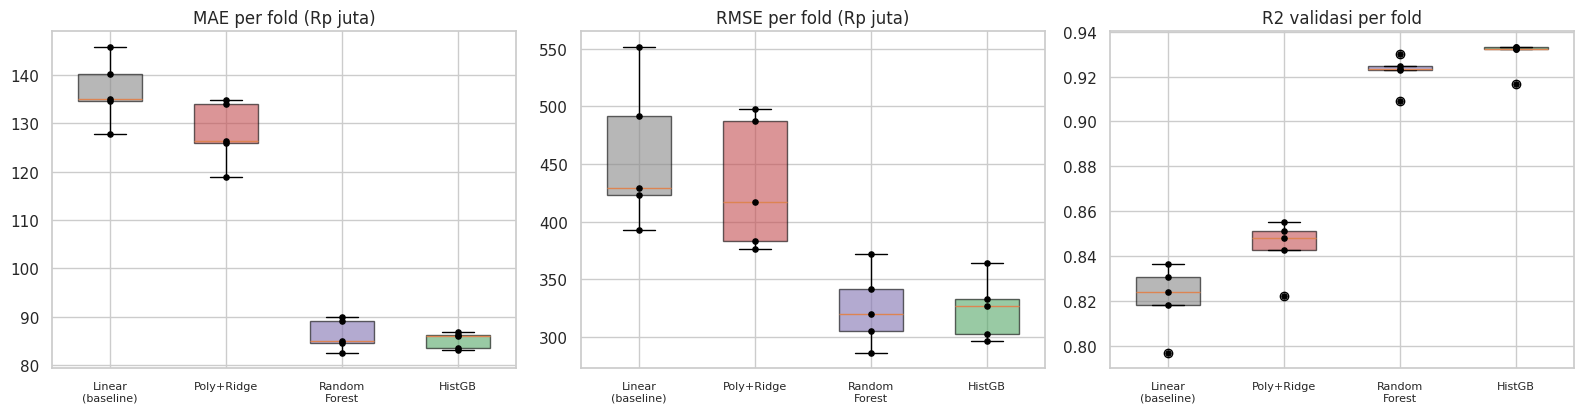

In [123]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
nama_pendek = ["Linear\n(baseline)", "Poly+Ridge", "Random\nForest", "HistGB"]
warna = ["#888888", "#C44E52", "#8172B2", "#55A868"]
for ax, kolom, judul in zip(axes, ["MAE (Rp juta)", "RMSE (Rp juta)", "R2 validasi"],
                            ["MAE per fold (Rp juta)", "RMSE per fold (Rp juta)", "R2 validasi per fold"]):
    data = [hasil_fold[k][kolom].values for k in hasil_fold]
    bp = ax.boxplot(data, labels=nama_pendek, patch_artist=True, widths=0.55)
    for patch, w in zip(bp["boxes"], warna):
        patch.set_facecolor(w); patch.set_alpha(0.6)
    for i, d in enumerate(data, 1):
        ax.scatter(np.full(len(d), i), d, color="black", s=14, zorder=3)
    ax.set_title(judul); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

**Hasil CV 5-Fold (data latih)**

| Model | MAE (Rp juta) rata-rata ± std | Rentang antar fold | RMSE (Rp juta) ± std | MAPE | R² validasi ± std | Celah R² latih-validasi | Waktu per fold |
|---|---|---|---|---|---|---|---|
| Linear Regression (baseline) | 136,6 ± 6,7 | 127,7 sampai 145,7 | 457,9 ± 63,6 | 24,0% | 0,821 ± 0,015 | 0,002 | 0,04 detik |
| Polynomial + Ridge | 128,0 ± 6,6 | 118,9 sampai 134,8 | 432,3 ± 57,1 | 21,9% | 0,844 ± 0,013 | 0,002 | 0,2 detik |
| Random Forest | 86,3 ± 3,1 | 82,6 sampai 90,0 | 325,0 ± 33,3 | 13,5% | 0,922 ± 0,008 | 0,039 | 21,1 detik |
| HistGradientBoosting | **85,2 ± 1,7** | 83,2 sampai 86,9 | **324,5 ± 26,7** | **13,1%** | **0,930 ± 0,007** | 0,021 | 2,9 detik |

**Interpretasi kestabilan**

1. **Semua model relatif stabil.** Koefisien variasi MAE antar-fold hanya 2% sampai 5%, dan simpangan baku R² di bawah 0,016. Peringkat model sama di kelima fold: baseline dan polynomial selalu di atas Rp 118 juta, sedangkan Random Forest dan HistGB selalu di bawah Rp 91 juta. Kesimpulan "ensemble lebih baik" tidak bergantung pada pembagian data tertentu.
2. **Ensemble tidak hanya lebih akurat tetapi juga lebih stabil**: std MAE turun dari 6,7 (baseline) menjadi 3,1 (Random Forest) dan 1,7 (HistGB).
3. **RMSE paling tidak stabil** (std 63,6 pada baseline, variasi 14%). Penyebabnya mobil mewah: fold yang kebetulan memuat supercar mahal menghasilkan RMSE besar. MAE dan R² lebih dapat diandalkan sebagai ukuran utama.
4. **Satu kali split memang bisa menipu, tetapi ringan di data ini.** Pada 20 pembagian acak, MAE baseline berkisar Rp 129,2 sampai 142,8 juta (std 3,6) dan polynomial Rp 117,8 sampai 133,1 juta. Skor baseline dari satu split (Rp 135,4 juta) ada di tengah rentang itu. Pita ketidakpastian sekitar ±Rp 7 juta, sehingga selisih di bawah itu (mis. baseline vs polynomial) tidak boleh dibesar-besarkan.
5. **Diagnosis bias-variance.** Baseline dan polynomial memiliki celah latih-validasi hampir nol (0,002) tetapi R² hanya 0,82 sampai 0,84: ciri **underfitting/bias tinggi**. Random Forest memiliki celah 0,039 (R² latih 0,961): *overfitting* ringan, tetapi R² validasinya tetap jauh lebih tinggi. HistGB memiliki celah lebih kecil (0,021) dengan R² validasi tertinggi.

# TUGAS 3: Ensemble Learning

**Pertanyaan:** apakah menggabungkan banyak model memberi manfaat dibanding baseline? Baseline dipertahankan, kedua ensemble dievaluasi dengan strategi validasi (5-Fold CV, `random_state=42`) dan metrik yang sama.

| Kandidat | Jenis | Alasan relevan untuk proyek ini |
|---|---|---|
| Random Forest | Bagging | Menurunkan *variance*, tahan noise. Pada milestone 4 sudah terbukti menurunkan MAE paling besar. |
| HistGradientBoosting | Boosting | Menurunkan *bias*: model linier terbukti *underfitting* (celah latih-validasi nol, R² 0,82). Berbasis histogram sehingga jauh lebih cepat daripada Gradient Boosting biasa pada 21.919 baris x 104 fitur. XGBoost/LightGBM ditunda karena HistGB sudah tersedia di scikit-learn tanpa instalasi tambahan. |

Keputusan ensemble terbaik diambil dari **hasil CV**, bukan dari test set. Test set dipakai **satu kali** untuk konfirmasi akhir baseline vs ensemble terpilih.

TUGAS 3: PERBANDINGAN BASELINE vs ENSEMBLE + uji akhir pada test set (SEKALI SAJA)

keputusan kandidat diambil dari hasil CV di atas, bukan dari test set

In [124]:
terbaik_ensemble = min(["Random Forest (bagging)", "HistGradientBoosting (boosting)"],
                       key=lambda k: hasil_fold[k]["MAE (Rp juta)"].mean())
print("Ensemble terbaik menurut CV (MAE):", terbaik_ensemble, "\n")

baris = []
for nama in ["Linear Regression (baseline)", terbaik_ensemble]:
    m = clone(model_cv[nama])
    t0 = time.time(); m.fit(X_latih, y_latih); waktu = time.time() - t0
    h = evaluasi(nama, y_uji, m.predict(X_uji))
    h["waktu latih penuh (detik)"] = waktu
    h["MAE CV (Rp juta)"] = hasil_fold[nama]["MAE (Rp juta)"].mean()
    baris.append(h)
akhir = pd.DataFrame(baris).set_index("model")
display(akhir[["MAE CV (Rp juta)", "MAE (Rp juta)", "RMSE (Rp juta)", "MedAE (Rp juta)", "MAPE (%)",
               "R2 (skala log)", "waktu latih penuh (detik)"]].rename(columns={"MAE (Rp juta)": "MAE uji (Rp juta)"}).round(3))

dasar = akhir.iloc[0]; ens = akhir.iloc[1]
print(f"\nPerbaikan ensemble vs baseline pada CV : MAE turun {(1 - ens['MAE CV (Rp juta)']/dasar['MAE CV (Rp juta)']):.1%}")
print(f"Perbaikan ensemble vs baseline pada TEST: MAE turun {(1 - ens['MAE (Rp juta)']/dasar['MAE (Rp juta)']):.1%}, "
      f"RMSE turun {(1 - ens['RMSE (Rp juta)']/dasar['RMSE (Rp juta)']):.1%}")
print(f"Biaya komputasi: {ens['waktu latih penuh (detik)']/max(dasar['waktu latih penuh (detik)'], 1e-6):.0f}x lebih lama dari baseline")

Ensemble terbaik menurut CV (MAE): HistGradientBoosting (boosting) 



,MAE CV (Rp juta),MAE uji (Rp juta),RMSE (Rp juta),MedAE (Rp juta),MAPE (%),R2 (skala log),waktu latih penuh (detik)
model,,,,,,,
Linear Regression (baseline),136.596,135.422,429.003,37.390,23.798,0.826,0.103
HistGradientBoosting (boosting),85.214,79.531,283.555,18.225,12.727,0.925,6.566



Perbaikan ensemble vs baseline pada CV : MAE turun 37.6%
Perbaikan ensemble vs baseline pada TEST: MAE turun 41.3%, RMSE turun 33.9%
Biaya komputasi: 64x lebih lama dari baseline


**Tabel Perbandingan Baseline vs Ensemble**

| Model | MAE CV (Rp juta) | MAE uji (Rp juta) | RMSE uji (Rp juta) | MedAE uji (Rp juta) | MAPE uji | R² uji (log) | Waktu latih |
|---|---|---|---|---|---|---|---|
| Linear Regression (baseline) | 136,6 | 135,4 | 429,0 | 37,4 | 23,8% | 0,826 | 0,05 detik |
| **HistGradientBoosting** | **85,2** | **79,5** | **283,6** | **18,2** | **12,7%** | **0,925** | 4,0 detik |

**Insight**

1. **Ensemble memberikan manfaat besar dan konsisten.** MAE turun 37,6% pada CV (Rp 136,6 menjadi 85,2 juta) dan 41,3% pada test (Rp 135,4 menjadi 79,5 juta). RMSE turun 33,9% dan R² naik dari 0,826 menjadi 0,925. CV dan test searah, jadi hasilnya bukan kebetulan satu split.
2. **Random Forest dan HistGB nyaris setara pada MAE** (86,3 vs 85,2 juta). Selisih Rp 1,1 juta jauh lebih kecil daripada simpangan baku antar-fold Random Forest (3,1), dan HistGB unggul di 3 dari 5 fold. Karena itu **belum ada bukti kuat bahwa satu lebih akurat**. HistGB dipilih sebagai ensemble terbaik karena R² CV sedikit lebih tinggi (0,930 vs 0,922), variasi antar-fold lebih kecil, dan **sekitar 7 kali lebih cepat** (2,9 vs 21,1 detik per fold).
3. **Biaya komputasi:** ensemble sekitar 88 kali lebih lama dilatih daripada baseline (4,0 vs 0,05 detik), tetapi masih kecil dalam angka mutlak untuk 21.919 baris. Harganya juga hilangnya interpretasi koefisien yang jelas pada regresi linier.
4. **Test lebih baik daripada CV (79,5 vs 85,2)**. Itu wajar: model akhir dilatih pada seluruh data latih (25% lebih banyak daripada tiap fold CV), dan ini pertama kalinya HistGB melihat test set. Tidak ada tanda *overfitting* ke test set.
5. **Alasan pemilihan model:** HistGradientBoosting dipilih untuk dilanjutkan karena akurasi tertinggi, paling stabil, dan murah. Ini belum berarti model final, karena belum di-*tuning* dan masih lemah di segmen mobil mewah.

# Interpretasi Hasil dan Keterbatasan Eksperimen

**Keterbatasan**
1. **Data iid diasumsikan.** Tidak ada kolom waktu atau penjual, sehingga iklan yang sama dengan sedikit perubahan (mis. harga atau kilometer berbeda) masih mungkin muncul di data latih dan uji. Duplikat persis sudah dibuang, tetapi duplikat samar tidak dapat dideteksi.
2. **Kebocoran kecil pada pengelompokan kategori jarang** (dihitung dari seluruh data). Dampaknya diuji dan hampir nol (MAE +0,11%), tetapi akan dipindah ke dalam Pipeline.
3. **Test set sudah pernah dilihat** pada milestone 4 untuk membandingkan 5 model. Keputusan milestone 5 berdasar CV, dan test hanya dipakai satu kali untuk konfirmasi.
4. **Hiperparameter ensemble belum di-tuning** (nilai standar). Skor ensemble kemungkinan masih bisa naik sedikit, dan perbedaan Random Forest vs HistGB belum bermakna.
5. **Segmen mobil mewah** (sekitar 8% data) jarang sehingga RMSE tidak stabil antar-fold (variasi 14% pada baseline). Hasil model hanya mewakili pasar Pulau Jawa (95,9% data) dan merupakan harga permintaan penjual.

# Rencana Eksperimen Pertemuan 6 dan 7

| Pertemuan | Rencana | Bukti yang mendasari |
|---|---|---|
| **6: Unsupervised dan dimensionality reduction** | (a) *K-Means* pada fitur numerik latih (umur, kilometer, kapasitas mesin) untuk menemukan segmen mobil (massal, menengah, premium/supercar) dan menilai kualitas dengan silhouette score; (b) PCA pada fitur numerik dan *one-hot* untuk melihat apakah 104 fitur dapat diringkas. Label klaster dipakai sebagai fitur tambahan **hanya jika di-fit pada data latih** (cegah kebocoran). | Galat terbesar ada di mobil mewah dan Baru; model linier terbukti underfitting |
| **7: Feature selection, diagnosis, error analysis** | (a) *Permutation importance* dan Lasso untuk menyeleksi fitur; (b) tuning HistGB dengan `RandomizedSearchCV` di dalam CV data latih (learning_rate, max_depth, min_samples_leaf, max_iter); (c) error analysis per segmen (mewah > Rp 1 miliar, Baru) dan 6 iklan berharga janggal; (d) pemindahan pengelompokan kategori ke dalam Pipeline; (e) evaluasi akhir pada test set **sekali**. | Celah CV vs test, ketidakstabilan RMSE, dan MAPE segmen mewah 23,5% |

# Checkpoint Pertemuan 5

| Pertanyaan checkpoint | Jawaban dan bukti |
|---|---|
| **Validasi:** bagaimana model diuji dan mengapa strategi itu dipilih? | Hold-out 80/20 acak + 5-Fold CV pada data latih; test dipakai sekali di akhir. Dipilih karena target kontinu (KFold acak sesuai), tidak ada kolom waktu/grup, dan K=5 menyeimbangkan biaya dan bias estimasi. Audit: tidak ada irisan, tidak ada duplikat, satu temuan kecil (kategori jarang) sudah diuji. |
| **Kestabilan:** apakah hasil konsisten antar-fold atau pembagian data? | Ya. Koefisien variasi MAE 2 sampai 5%, simpangan baku R² < 0,016; peringkat model sama di seluruh fold; pada 20 split acak, MAE baseline berkisar Rp 129 sampai 143 juta. RMSE paling tidak stabil karena mobil mewah. |
| **Perbandingan:** apakah kandidat baru bermanfaat dibanding baseline? | Ya. HistGB menurunkan MAE 37,6% (CV) dan 41,3% (test), RMSE 33,9%, R² 0,826 menjadi 0,925. Random Forest setara pada MAE. Biayanya 88x lebih lama latih. |
| **Imbalance:** apakah distribusi kelas memengaruhi evaluasi? | Tidak relevan (regresi). Analoginya: segmen mewah (sekitar 8%) dan mobil Baru (sekitar 10%) jarang, dan memang menjadi sumber galat terbesar serta ketidakstabilan RMSE. |
| **Keputusan:** apa yang akan diperbaiki dan apa buktinya? | Tuning HistGB, pemindahan pengelompokan kategori ke Pipeline, serta error analysis segmen mewah dan Baru. Bukti: celah R² latih-validasi (Random Forest 0,039), MAPE segmen mewah 23,5%, dan variasi RMSE antar-fold. |

# MILESTONE PERTEMUAN 6: Unsupervised Learning dan Dimensionality Reduction

**Project ID A02 – Faktor Penentu Harga Mobil Bekas.** Dataset, tujuan, dan target (`log(price)`) sama seperti milestone sebelumnya. Model terbaik sementara: HistGradientBoosting (milestone 5).

## Apakah clustering dan PCA relevan?
Proyek ini **regresi** (ada target `price`), jadi clustering dan PCA bukan tujuan utama. Tapi tetap relevan karena:
- Galat terbesar ada di mobil mewah dan mobil Baru, jadi mungkin ada **kelompok mobil** yang berbeda. Clustering dipakai untuk mencari kelompok itu **tanpa melihat harga**.
- Setelah one-hot fiturnya jadi **104 kolom**. PCA dicoba untuk melihat apakah bisa diringkas dan apakah itu membantu model.

Jadi keduanya dipakai sebagai **eksperimen pendukung**. Kalau ternyata tidak membantu, itu juga hasil yang dilaporkan.

## Aturan agar tidak leakage
- `log_price` tidak dipakai untuk membentuk klaster atau PCA. Harga hanya dipakai **setelah** klaster jadi, untuk profil dan validasi (`eta2` = berapa persen varians log harga yang dijelaskan klaster; pengganti ARI karena tidak ada label kelas).
- Imputer, scaler, KMeans, dan PCA di-fit hanya di data latih (di dalam Pipeline saat dipakai untuk model).
- **Data uji tidak disentuh**. Semua keputusan pakai data latih dan 5-fold CV.
- Seed = 42 di semua eksperimen.

**PERSIAPAN: library, fungsi bantu, dan pengecekan prasyarat**

In [125]:
perlu = ["bersih", "X_latih", "X_uji", "y_latih", "y_uji", "FITUR_NUM", "FITUR_BIN", "FITUR_KAT",
         "buat_praproses", "praproses_padat", "kf5", "evaluasi"]
hilang = [v for v in perlu if v not in globals()]
assert not hilang, f"Jalankan dulu sel milestone 3-5. Variabel belum ada: {hilang}"

import warnings
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import FeatureUnion
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
SIL_N = 5000

def eta2(label, y):
    """Persen varians log_price yang dijelaskan klaster (0 = tidak berguna, 1 = sempurna).
    log_price HANYA dipakai untuk menilai klaster, tidak untuk membentuknya."""
    y, label = np.asarray(y, float), np.asarray(label)
    sst = ((y - y.mean()) ** 2).sum()
    ssb = sum(((y[label == g].mean() - y.mean()) ** 2) * (label == g).sum() for g in np.unique(label))
    return ssb / sst

def sil(Z, label, n=SIL_N):
    return silhouette_score(Z, label, sample_size=min(n, len(Z)), random_state=SEED)

print("Siap. Data latih:", X_latih.shape, "| data uji:", X_uji.shape, "(data uji TIDAK dipakai di milestone 6)")

Siap. Data latih: (21919, 8) | data uji: (5480, 8) (data uji TIDAK dipakai di milestone 6)


## A. K-Means (baseline clustering)
Fitur: `umur`, `km_sqrt`, `engine` (3 numerik). Imputasi median + StandardScaler, di-fit di data latih.

**A1. Ruang fitur untuk clustering dan pengaruh scaling **

Fitur clustering = 3 numerik (umur, km_sqrt, engine), sesuai rencana milestone 5. Imputer dan scaler di-fit HANYA pada data latih.

In [126]:
imp_k = SimpleImputer(strategy="median").fit(X_latih[FITUR_NUM])
X_imp = imp_k.transform(X_latih[FITUR_NUM])
sc_k = StandardScaler().fit(X_imp)
X_std = sc_k.transform(X_imp)

print("Varians tiap fitur SEBELUM scaling (yang menentukan jarak Euclidean):")
display(pd.DataFrame({"varians": X_imp.var(axis=0)}, index=FITUR_NUM).round(2))

K0 = 3
km_raw = KMeans(K0, n_init=10, random_state=SEED).fit(X_imp)
km_std = KMeans(K0, n_init=10, random_state=SEED).fit(X_std)
tab = pd.DataFrame({
    "tanpa scaling":     {"eta2 log_price": eta2(km_raw.labels_, y_latih), "silhouette": sil(X_imp, km_raw.labels_),
                          "ukuran klaster": str(np.bincount(km_raw.labels_).tolist())},
    "setelah StandardScaler": {"eta2 log_price": eta2(km_std.labels_, y_latih), "silhouette": sil(X_std, km_std.labels_),
                          "ukuran klaster": str(np.bincount(km_std.labels_).tolist())},
}).T
display(tab)
print("ARI antara kedua hasil klaster:", round(adjusted_rand_score(km_raw.labels_, km_std.labels_), 3))

Varians tiap fitur SEBELUM scaling (yang menentukan jarak Euclidean):


,varians
umur,20.69
km_sqrt,8933.09
engine,0.50


,eta2 log_price,silhouette,ukuran klaster
tanpa scaling,0.231895,0.535331,"[6239, 6231, 9449]"
setelah StandardScaler,0.340026,0.3605,"[11783, 8080, 2056]"


ARI antara kedua hasil klaster: 0.318


**Scaling.** Varians `km_sqrt` (sekitar 8.933) jauh lebih besar dari `umur` (20,7) dan `engine` (0,5), jadi tanpa scaling jaraknya didominasi kilometer. `eta2` tanpa scaling 0,232 vs **0,340** dengan scaling. Silhouette tanpa scaling malah lebih tinggi (0,535 vs 0,361) padahal klasternya lebih jelek, jadi silhouette tidak boleh dibandingkan antar ruang fitur yang berbeda. **Kesimpulan:** scaling wajib.

**A2. Inisialisasi: random vs k-means++ (n_init=1, 30 seed) dan kestabilan hasil**

In [127]:
baris = []
for init in ["random", "k-means++"]:
    ine, itr = [], []
    for s in range(30):
        m = KMeans(K0, init=init, n_init=1, random_state=s).fit(X_std)
        ine.append(m.inertia_); itr.append(m.n_iter_)
    baris.append({"inisialisasi (n_init=1)": init, "inertia rata-rata": np.mean(ine), "simpangan baku": np.std(ine),
                  "terburuk": np.max(ine), "iterasi rata-rata": np.mean(itr)})
display(pd.DataFrame(baris).set_index("inisialisasi (n_init=1)").round(1))

ref1 = KMeans(K0, n_init=1, random_state=0).fit_predict(X_std)
ari_1 = [adjusted_rand_score(ref1, KMeans(K0, n_init=1, random_state=s).fit_predict(X_std)) for s in range(1, 11)]
ref10 = KMeans(K0, n_init=10, random_state=0).fit_predict(X_std)
ari_10 = [adjusted_rand_score(ref10, KMeans(K0, n_init=10, random_state=s).fit_predict(X_std)) for s in range(1, 11)]
print("ARI antar seed, n_init=1 :", np.round(ari_1, 3), "| minimum", round(min(ari_1), 3))
print("ARI antar seed, n_init=10:", np.round(ari_10, 3), "| minimum", round(min(ari_10), 3))

,inertia rata-rata,simpangan baku,terburuk,iterasi rata-rata
inisialisasi (n_init=1),,,,
random,33604.4,646.3,35293.2,21.0
k-means++,33412.3,562.4,34100.9,19.1


ARI antar seed, n_init=1 : [0.399 0.415 0.398 0.398 0.818 0.398 0.998 0.959 0.963 0.821] | minimum 0.398
ARI antar seed, n_init=10: [1.    1.    1.    0.989 1.    1.    1.    0.997 1.    1.   ] | minimum 0.989


**Memilih K.** Elbow tidak punya siku yang jelas. Silhouette tertinggi di K=3 (0,360). Davies-Bouldin terendah di K=8 (0,973) tapi K=3 hampir sama (0,989), dan Calinski-Harabasz tertinggi di K=2. Jadi metrik tidak sepakat, artinya struktur klasternya lemah. Saya pilih **K=3** karena silhouette tertinggi, klaster terkecil masih 9,4% data, dan hasilnya bisa dijelaskan.

**A4. Profil klaster (K = 3) dalam SATUAN ASLI**

,jumlah,median_harga_juta,umur_median,km_median,mesin_median,persen_baru,persen_matic,persen_harga_di_atas_1M,persen_data,bodi_dominan
klaster,,,,,,,,,,
0,8080,179.0,9.0,83400.5,1.6,0.0,83.6,0.1,36.9,MPV
1,11783,285.0,3.0,24000.0,1.5,15.4,89.6,6.2,53.8,SUV
2,2056,1080.0,7.0,20005.0,3.0,18.5,97.0,53.0,9.4,SUV


eta2 log_price (varians harga yang dijelaskan klaster): 0.34


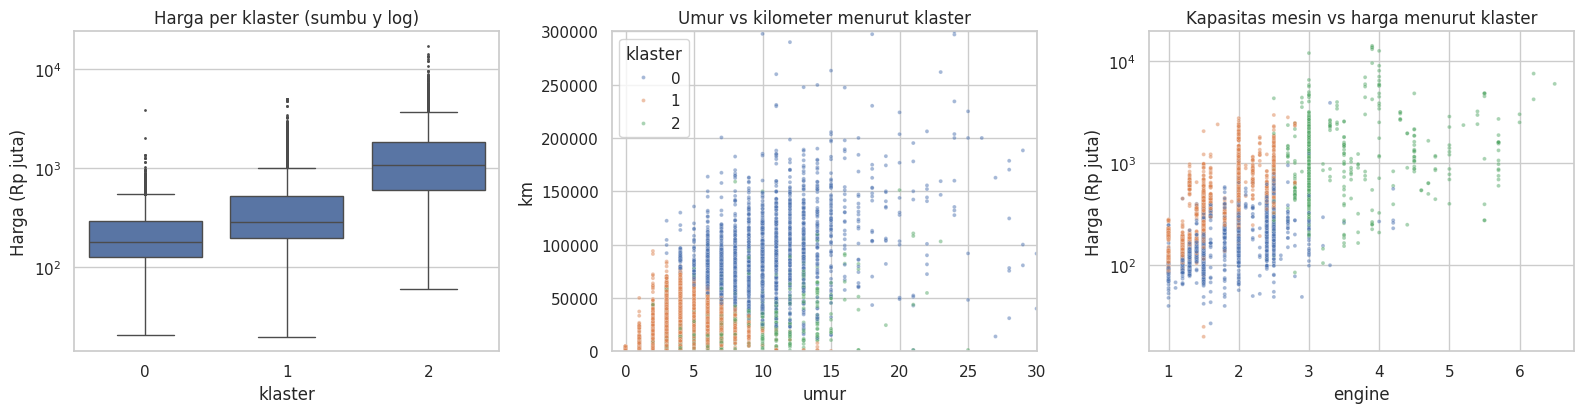

In [128]:
K = 3
km = KMeans(K, n_init=10, random_state=SEED).fit(X_std)
lab = km.labels_

prof = X_latih.copy()
prof["harga_juta"] = np.exp(y_latih) / 1e6
prof["km"] = prof["km_sqrt"] ** 2
prof["klaster_mentah"] = lab
urut_k = prof.groupby("klaster_mentah")["harga_juta"].median().sort_values().index
peta = {lama: baru for baru, lama in enumerate(urut_k)}
prof["klaster"] = prof["klaster_mentah"].map(peta)
lab_urut = prof["klaster"].values

profil = prof.groupby("klaster").agg(
    jumlah=("harga_juta", "size"), median_harga_juta=("harga_juta", "median"),
    umur_median=("umur", "median"), km_median=("km", "median"), mesin_median=("engine", "median"),
    persen_baru=("is_baru", lambda s: s.mean() * 100), persen_matic=("is_matic", lambda s: s.mean() * 100),
    persen_harga_di_atas_1M=("harga_juta", lambda s: (s > 1000).mean() * 100))
profil["persen_data"] = profil["jumlah"] / len(prof) * 100
profil["bodi_dominan"] = prof.groupby("klaster")["body_g"].agg(lambda s: s.value_counts().index[0])
display(profil.round(1))

print("eta2 log_price (varians harga yang dijelaskan klaster):", round(eta2(lab_urut, y_latih), 3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
sns.boxplot(data=prof, x="klaster", y="harga_juta", ax=axes[0], fliersize=1); axes[0].set_yscale("log")
axes[0].set_title("Harga per klaster (sumbu y log)"); axes[0].set_ylabel("Harga (Rp juta)")
ac = prof.sample(6000, random_state=SEED)
sns.scatterplot(data=ac, x="umur", y="km", hue="klaster", palette="deep", s=8, alpha=0.5, ax=axes[1])
axes[1].set_ylim(0, 300000); axes[1].set_xlim(-1, 30); axes[1].set_title("Umur vs kilometer menurut klaster")
sns.scatterplot(data=ac, x="engine", y="harga_juta", hue="klaster", palette="deep", s=8, alpha=0.5, ax=axes[2], legend=False)
axes[2].set_yscale("log"); axes[2].set_title("Kapasitas mesin vs harga menurut klaster"); axes[2].set_ylabel("Harga (Rp juta)")
plt.tight_layout(); plt.show()

**Profil klaster (K=3).** Nomor klaster diurutkan dari median harga terendah.

| Klaster | Jumlah | Median harga | Ciri | Nama (tafsiran saya) |
|---|---|---|---|---|
| 0 | 8.080 (36,9%) | Rp 179 juta | umur 9 th, 83 ribu km | Tua, KM tinggi |
| 1 | 11.783 (53,8%) | Rp 285 juta | umur 3 th, 24 ribu km | Muda, KM rendah |
| 2 | 2.056 (9,4%) | Rp 1,08 miliar | mesin 3,0 L | Mesin besar (premium) |

Klaster dibentuk tanpa harga, tapi median harganya terurut jelas dan `eta2` = 0,340. Klaster 2 hanya 9,4% data tapi 53% isinya berharga di atas Rp 1 miliar, cocok dengan segmen mewah yang sulit diprediksi. Nama klaster adalah tafsiran saya, bukan dari data.

A5. Kestabilan klaster: bootstrap (10 resampel data latih)

In [129]:
rng = np.random.default_rng(SEED)
ari_boot = []
for b in range(10):
    idx = rng.choice(len(X_std), len(X_std), replace=True)
    mb = KMeans(K, n_init=10, random_state=b).fit(X_std[idx])
    ari_boot.append(adjusted_rand_score(km.labels_, mb.predict(X_std)))
print("ARI klaster asli vs klaster hasil bootstrap:", np.round(ari_boot, 3))
print("Rata-rata:", round(np.mean(ari_boot), 3), "| minimum:", round(np.min(ari_boot), 3))

ARI klaster asli vs klaster hasil bootstrap: [0.986 0.983 0.979 0.994 0.98  0.983 0.984 0.788 0.994 0.974]
Rata-rata: 0.964 | minimum: 0.788


**Kestabilan.** Dari 10 bootstrap, ARI rata-rata terhadap klaster asli 0,964 (minimum 0,788). Cukup stabil, meski ada satu resampel yang agak berbeda karena batas klaster tidak tegas.

## B. Algoritma alternatif: Hierarchical dan DBSCAN
Hierarchical memakai sampel 3.000 titik karena butuh memori O(n²).

,ukuran klaster,klaster terbesar (%),eta2 log_price,silhouette
linkage,,,,
ward,"[1636, 1187, 177]",54.533,0.270,0.299
complete,"[2577, 394, 29]",85.900,0.137,0.377
average,"[2916, 46, 38]",97.200,0.061,0.544
single,"[2996, 2, 2]",99.867,0.004,0.620


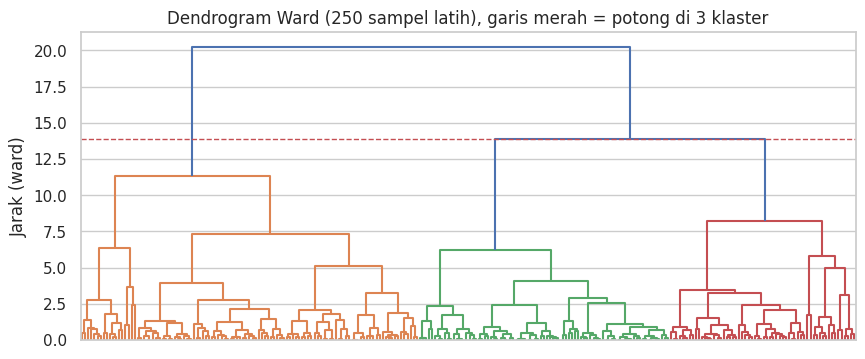

Lompatan jarak 5 penggabungan terakhir: [ 7.3  8.2 11.3 13.9 20.3]


In [130]:
rs = np.random.default_rng(SEED).choice(len(X_std), 3000, replace=False)
Xh, yh = X_std[rs], y_latih.iloc[rs]

baris = []
for link in ["ward", "complete", "average", "single"]:
    a = AgglomerativeClustering(n_clusters=K, linkage=link).fit_predict(Xh)
    baris.append({"linkage": link, "ukuran klaster": str(sorted(np.bincount(a).tolist(), reverse=True)),
                  "klaster terbesar (%)": np.bincount(a).max() / len(a) * 100, "eta2 log_price": eta2(a, yh), "silhouette": sil(Xh, a)})
display(pd.DataFrame(baris).set_index("linkage").round(3))

Zl = linkage(Xh[:250], method="ward")
fig, ax = plt.subplots(figsize=(10, 4))
tinggi_potong = Zl[-K + 1, 2] - 1e-9 if K > 1 else 0
dendrogram(Zl, no_labels=True, color_threshold=tinggi_potong, ax=ax)
ax.axhline(tinggi_potong, color="r", ls="--", lw=1)
ax.set_title("Dendrogram Ward (250 sampel latih), garis merah = potong di 3 klaster"); ax.set_ylabel("Jarak (ward)")
plt.show()
print("Lompatan jarak 5 penggabungan terakhir:", np.round(Zl[-5:, 2], 1))

**Hierarchical.** Ward masuk akal (ukuran 1.636 / 1.187 / 177, `eta2` 0,270). Linkage single, average, dan complete menaruh 86 sampai 99,9% titik di satu klaster (chaining), jadi gagal walaupun silhouette-nya tinggi. Di dendrogram lompatan terbesar ada di penggabungan terakhir (13,9 ke 20,3) yang menunjuk 2 klaster, jadi dukungan untuk K=3 tidak kuat.

**B2. DBSCAN: pilih eps dari grafik k-distance, lalu uji beberapa eps**

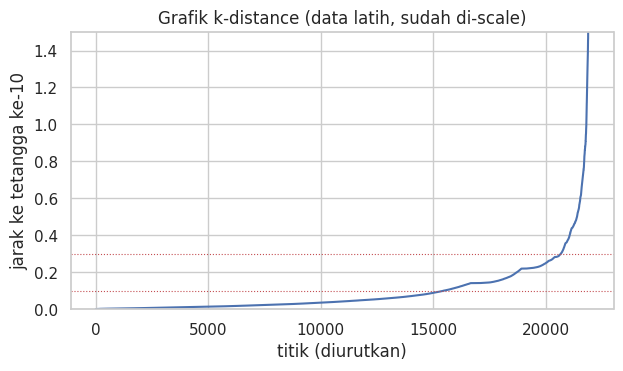

Persentil jarak tetangga ke-10: {50: np.float64(0.042), 90: np.float64(0.232), 95: np.float64(0.337), 99: np.float64(0.774)}


,jumlah klaster,noise (%),klaster terbesar (% data)
eps,,,
0.1,176,24.7,6.1
0.2,99,11.7,8.2
0.3,12,4.0,94.3
0.5,2,1.5,98.1
0.8,3,0.5,99.4


In [131]:
MIN_S = 10
dist, _ = NearestNeighbors(n_neighbors=MIN_S).fit(X_std).kneighbors(X_std)
kd = np.sort(dist[:, -1])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(kd); ax.set_ylim(0, 1.5); ax.set_xlabel("titik (diurutkan)"); ax.set_ylabel(f"jarak ke tetangga ke-{MIN_S}")
for e in [0.1, 0.3]: ax.axhline(e, color="r", ls=":", lw=0.8)
ax.set_title("Grafik k-distance (data latih, sudah di-scale)"); plt.show()
print("Persentil jarak tetangga ke-10:", dict(zip([50, 90, 95, 99], np.percentile(kd, [50, 90, 95, 99]).round(3))))

baris = []
for eps in [0.1, 0.2, 0.3, 0.5, 0.8]:
    l = DBSCAN(eps=eps, min_samples=MIN_S).fit_predict(X_std)
    ada = l[l >= 0]
    baris.append({"eps": eps, "jumlah klaster": len(set(ada)), "noise (%)": (l == -1).mean() * 100,
                  "klaster terbesar (% data)": (np.bincount(ada).max() / len(l) * 100) if len(ada) else 0})
display(pd.DataFrame(baris).set_index("eps").round(1))

**DBSCAN.** Grafik k-distance tidak punya siku yang jelas. `eps` kecil (0,1 sampai 0,2) memecah jadi 99 sampai 176 klaster, `eps` 0,3 menghasilkan satu klaster berisi 94,3% data, dan `eps` 0,5 ke atas hampir semuanya menyatu. Sepertinya data ini tidak punya wilayah padat yang terpisah, jadi DBSCAN kurang cocok untuk segmentasi.

**B3. DBSCAN eps = 0,3: siapa yang ditandai noise (kandidat anomali)?**

In [132]:
db = DBSCAN(eps=0.3, min_samples=MIN_S).fit(X_std)
nz = db.labels_ == -1
cmp_ = pd.DataFrame({
    "jumlah": [nz.sum(), (~nz).sum()],
    "median harga (Rp juta)": [prof.loc[nz, "harga_juta"].median(), prof.loc[~nz, "harga_juta"].median()],
    "% harga > Rp 1 miliar": [(prof.loc[nz, "harga_juta"] > 1000).mean() * 100, (prof.loc[~nz, "harga_juta"] > 1000).mean() * 100],
    "umur median": [prof.loc[nz, "umur"].median(), prof.loc[~nz, "umur"].median()],
    "mesin median (L)": [prof.loc[nz, "engine"].median(), prof.loc[~nz, "engine"].median()],
    "km median": [prof.loc[nz, "km"].median(), prof.loc[~nz, "km"].median()],
}, index=["noise (-1)", "bukan noise"]).round(1)
display(cmp_)

lab_ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Xh)
ringkas_algo = pd.DataFrame({
    "K-Means (K=3)":        {"data dipakai": len(X_std), "jumlah klaster": K, "noise (%)": 0.0, "eta2 log_price": eta2(lab_urut, y_latih), "silhouette": sil(X_std, lab_urut)},
    "Ward (K=3, sampel)":   {"data dipakai": len(Xh), "jumlah klaster": K, "noise (%)": 0.0, "eta2 log_price": eta2(lab_ward, yh), "silhouette": sil(Xh, lab_ward)},
    "DBSCAN (eps=0,3)":     {"data dipakai": len(X_std), "jumlah klaster": len(set(db.labels_)) - 1, "noise (%)": nz.mean() * 100,
                             "eta2 log_price": eta2(db.labels_, y_latih), "silhouette": sil(X_std[~nz], db.labels_[~nz])},
}).T
display(ringkas_algo.round(3))

,jumlah,median harga (Rp juta),% harga > Rp 1 miliar,umur median,mesin median (L),km median
noise (-1),872,258.0,23.5,15.0,3.0,74069.5
bukan noise,21047,252.0,7.7,5.0,1.5,38904.0


,data dipakai,jumlah klaster,noise (%),eta2 log_price,silhouette
K-Means (K=3),21919.0,3.0,0.000,0.340,0.360
"Ward (K=3, sampel)",3000.0,3.0,0.000,0.270,0.299
"DBSCAN (eps=0,3)",21919.0,12.0,3.978,0.092,0.140


**Perbandingan.** `eta2`: K-Means 0,340 > Ward 0,270 > DBSCAN 0,092, jadi K-Means paling cocok di sini. Tapi noise DBSCAN (872 titik) menarik: umur median 15 tahun (vs 5), mesin 3,0 L (vs 1,5), dan 23,5% berharga di atas Rp 1 miliar (vs 7,7%). Noise ini bisa jadi kandidat anomali untuk error analysis nanti.

## C. Curse of dimensionality di data kita
Diukur: jarak tetangga ke-10 dibanding rata-rata jarak (makin mendekati 1, makin sulit membedakan tetangga dekat dari titik lain).

**3 fitur numerik vs 104 kolom hasil one-hot**

In [133]:
pra_full = praproses_padat().fit(X_latih)
Z_full = pra_full.transform(X_latih)
print("Bentuk matriks fitur lengkap:", Z_full.shape, "| proporsi nilai nol:", round((Z_full == 0).mean(), 3))

ri = np.random.default_rng(SEED).choice(len(X_std), 1000, replace=False)
ruang = {"3 fitur numerik (scaled)": X_std[ri], f"{Z_full.shape[1]} kolom (numerik + biner + one-hot)": Z_full[ri]}
baris = []
for nama, M in ruang.items():
    D = squareform(pdist(M)); D.sort(axis=1)
    rata = D.mean(axis=1)
    baris.append({"ruang fitur": nama, "dimensi": M.shape[1],
                  "jarak tetangga ke-10 / rata-rata jarak": np.median(D[:, 10] / rata),
                  "jarak terjauh / jarak tetangga ke-10": np.median(D[:, -1] / D[:, 10]),
                  "simpangan baku / rata-rata jarak": pdist(M).std() / pdist(M).mean()})
display(pd.DataFrame(baris).set_index("ruang fitur").round(3))

Bentuk matriks fitur lengkap: (21919, 104) | proporsi nilai nol: 0.933


,dimensi,jarak tetangga ke-10 / rata-rata jarak,jarak terjauh / jarak tetangga ke-10,simpangan baku / rata-rata jarak
ruang fitur,,,,
3 fitur numerik (scaled),3,0.165,23.000,0.584
104 kolom (numerik + biner + one-hot),104,0.529,4.751,0.313


Pada 3 fitur rasionya 0,165, pada 104 kolom naik jadi 0,529. Jarak terjauh dibanding tetangga ke-10 turun dari 23 kali menjadi 4,8 kali. Jadi jarak memang makin kurang informatif di dimensi tinggi (walau tidak seekstrem simulasi di slide). Itu alasan clustering saya pakai 3 fitur numerik saja.

## D. PCA
Alasan mencoba PCA: ada 104 kolom hasil one-hot, ingin tahu apakah bisa diringkas dan apakah itu membantu prediksi. Scaling dan PCA dimasukkan ke dalam Pipeline saat dipakai untuk model.

**D1. PCA pada matriks fitur lengkap (104 kolom): explained variance dan jumlah komponen**

Jumlah komponen untuk target varians: {'80%': 10, '90%': 24, '95%': 48, '99%': 85}
PC1..PC5: [30.8 20.   6.8  5.8  5.6] (%) | PC1+PC2 = 50.8 %


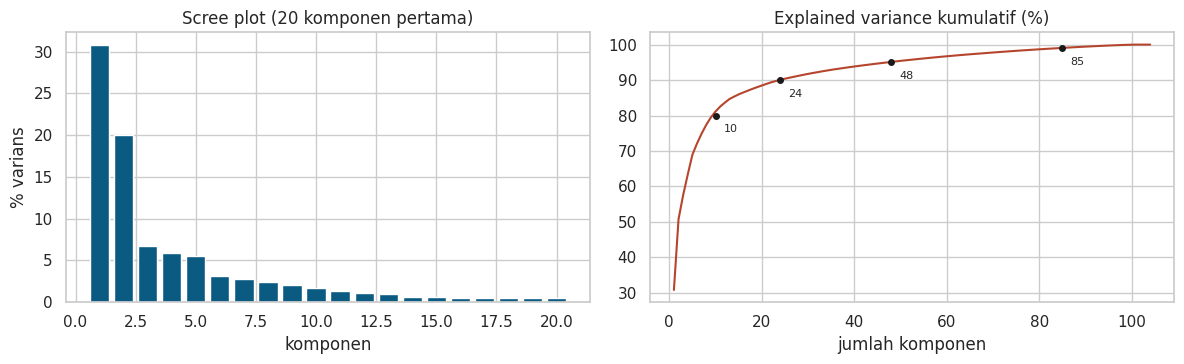

In [134]:
pca_full = PCA(random_state=SEED).fit(Z_full)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
perlu_k = {f"{int(t*100)}%": int(np.searchsorted(cum, t) + 1) for t in [0.80, 0.90, 0.95, 0.99]}
print("Jumlah komponen untuk target varians:", perlu_k)
print("PC1..PC5:", np.round(evr[:5] * 100, 1), "(%) | PC1+PC2 =", round(evr[:2].sum() * 100, 1), "%")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(range(1, 21), evr[:20] * 100, color="#0B5A82"); axes[0].set_title("Scree plot (20 komponen pertama)")
axes[0].set_xlabel("komponen"); axes[0].set_ylabel("% varians")
axes[1].plot(range(1, len(cum) + 1), cum * 100, color="#B6452E")
for t, kk in perlu_k.items():
    axes[1].plot(kk, float(t[:-1]), "ko", ms=4); axes[1].annotate(f"{kk}", (kk, float(t[:-1])), textcoords="offset points", xytext=(6, -12), fontsize=8)
axes[1].set_title("Explained variance kumulatif (%)"); axes[1].set_xlabel("jumlah komponen")
plt.tight_layout(); plt.show()

PC1 = 30,8% dan PC2 = 20,0% varians, jadi plot 2D hanya menangkap 50,8%. Untuk menyimpan 80% / 90% / 95% / 99% varians dibutuhkan **10 / 24 / 48 / 85 komponen** dari 104 kolom.

**D2. PCA pada fitur numerik + biner: arti tiap komponen (interpretabilitas)**

In [135]:
FITUR_PCA5 = FITUR_NUM + FITUR_BIN
X5 = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X_latih[FITUR_PCA5]))
pca5 = PCA(random_state=SEED).fit(X5)
print("Explained variance ratio (%):", np.round(pca5.explained_variance_ratio_ * 100, 1))
muatan = pd.DataFrame(pca5.components_[:3], columns=FITUR_PCA5, index=["PC1", "PC2", "PC3"]).round(2)
display(muatan)

Explained variance ratio (%): [41.  24.8 17.7 11.   5.5]


,umur,km_sqrt,engine,is_baru,is_matic
PC1,0.57,0.62,0.05,-0.51,-0.16
PC2,0.22,-0.04,0.77,0.08,0.60
PC3,-0.31,0.10,-0.41,-0.48,0.71


PCA pada 5 fitur numerik dan biner supaya bisa dibaca: **PC1** kira-kira umur dan kilometer (lawan status Baru), yaitu sumbu usia/pemakaian; **PC2** kira-kira kapasitas mesin dan matic, yaitu sumbu kelas mobil. Pada 104 kolom, komponen sulit dibaca karena campuran semua fitur (interpretabilitas turun).

**D3. Rekonstruksi: seberapa mirip data hasil kompresi dengan aslinya? (5-fold CV, PCA di-fit di fold latih)**

In [136]:
baris = []
for k in [2, 5, 10, 20, 40, 60, 90]:
    mse = []
    for tr, va in kf5.split(X_latih):
        pr = praproses_padat().fit(X_latih.iloc[tr])
        A, B = pr.transform(X_latih.iloc[tr]), pr.transform(X_latih.iloc[va])
        p = PCA(k, random_state=SEED).fit(A)
        mse.append(((B - p.inverse_transform(p.transform(B))) ** 2).mean())
    baris.append({"komponen k": k, "% varians (data latih penuh)": cum[k - 1] * 100, "MSE rekonstruksi (validasi)": np.mean(mse)})
display(pd.DataFrame(baris).set_index("komponen k").round(4))

,% varians (data latih penuh),MSE rekonstruksi (validasi)
komponen k,,
2,50.7731,0.0261
5,68.9503,0.0165
10,81.1319,0.0100
20,88.4553,0.0061
40,93.8204,0.0033
60,96.7079,0.0018
90,99.4272,0.0003


Error rekonstruksi turun cepat lalu melambat (0,0261 untuk 2 komponen, 0,0061 untuk 20, 0,0003 untuk 90). 20 komponen sudah menyimpan 88,5% varians, tapi sisanya tetap hilang (kompresi dengan kehilangan).

D4. Apakah PCA meningkatkan model regresi? PCA di DALAM Pipeline, dinilai dengan 5-fold CV

,model,PCA,MAE CV (Rp juta),std,R2 CV,waktu (detik)
0,Linear,tanpa PCA (104 kolom),136.596,6.733,0.821,1.096
1,Linear,2 komponen,197.025,7.081,0.692,0.599
2,Linear,5 komponen,199.302,7.399,0.697,0.555
3,Linear,10 komponen,189.955,7.396,0.713,0.739
4,Linear,20 komponen,176.329,7.692,0.740,0.905
5,Linear,40 komponen,169.930,7.298,0.755,1.144
6,Linear,60 komponen,160.611,7.000,0.775,1.245
7,HistGB,tanpa PCA (104 kolom),85.214,1.678,0.930,24.778
8,HistGB,2 komponen,149.765,5.435,0.787,1.708
9,HistGB,5 komponen,123.733,5.217,0.849,6.282


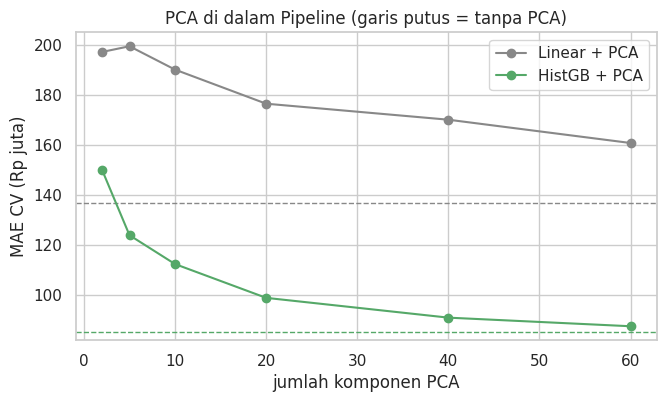

In [137]:
def cv_skor(est, X=None):
    """5-fold CV pada data latih. Mengembalikan MAE per fold (Rp juta) dan R2 rata-rata (skala log)."""
    X = X_latih if X is None else X
    mae, r2 = [], []
    for tr, va in kf5.split(X):
        m = clone(est).fit(X.iloc[tr], y_latih.iloc[tr])
        p = m.predict(X.iloc[va]); yv = y_latih.iloc[va]
        mae.append(mean_absolute_error(np.exp(yv), np.exp(p)) / 1e6); r2.append(r2_score(yv, p))
    return np.array(mae), float(np.mean(r2))

def buat_model(jenis):
    if jenis == "Linear": return LinearRegression()
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=SEED)   # sama dengan milestone 5

baris = []
for jenis in ["Linear", "HistGB"]:
    t0 = time.time()
    mae, r2 = cv_skor(Pipeline([("pra", praproses_padat()), ("m", buat_model(jenis))]))
    baris.append({"model": jenis, "PCA": "tanpa PCA (104 kolom)", "MAE CV (Rp juta)": mae.mean(), "std": mae.std(ddof=1), "R2 CV": r2, "waktu (detik)": time.time() - t0})
    for k in [2, 5, 10, 20, 40, 60]:
        t0 = time.time()
        mae, r2 = cv_skor(Pipeline([("pra", praproses_padat()), ("pca", PCA(k, random_state=SEED)), ("m", buat_model(jenis))]))
        baris.append({"model": jenis, "PCA": f"{k} komponen", "MAE CV (Rp juta)": mae.mean(), "std": mae.std(ddof=1), "R2 CV": r2, "waktu (detik)": time.time() - t0})
tab_pca = pd.DataFrame(baris)
display(tab_pca.round(3))

fig, ax = plt.subplots(figsize=(7.5, 4))
for jenis, w in [("Linear", "#888888"), ("HistGB", "#55A868")]:
    d = tab_pca[(tab_pca["model"] == jenis) & (tab_pca["PCA"] != "tanpa PCA (104 kolom)")]
    ks = d["PCA"].str.split().str[0].astype(int)
    ax.plot(ks, d["MAE CV (Rp juta)"], "o-", color=w, label=f"{jenis} + PCA")
    ax.axhline(tab_pca[(tab_pca["model"] == jenis) & (tab_pca["PCA"] == "tanpa PCA (104 kolom)")]["MAE CV (Rp juta)"].iloc[0], color=w, ls="--", lw=1)
ax.set_xlabel("jumlah komponen PCA"); ax.set_ylabel("MAE CV (Rp juta)"); ax.legend(); ax.set_title("PCA di dalam Pipeline (garis putus = tanpa PCA)")
plt.show()

**Dengan vs tanpa PCA (5-fold CV, PCA di dalam Pipeline).**

| Model | Tanpa PCA | PCA 60 | PCA 20 | PCA 10 |
|---|---|---|---|---|
| Linear (MAE CV, Rp juta) | **136,6** | 160,6 | 176,3 | 190,0 |
| HistGB (MAE CV, Rp juta) | **85,2** | 87,3 | 98,7 | 112,2 |

PCA **tidak** meningkatkan akurasi, malah menurun. Dugaan saya: PCA memilih arah berdasarkan varians, bukan kaitannya dengan harga, jadi informasi seperti model mobil (one-hot dengan varians kecil) ikut terbuang. Ini baru dugaan, belum saya uji. PCA hanya menghemat waktu HistGB (sekitar 4 kali lebih cepat pada 10 komponen). **Trade-off:** dimensi turun dan lebih cepat, tapi akurasi dan interpretabilitas turun. Jadi PCA tidak dipakai di model akhir.

## E. K-Means di ruang berbeda (3 numerik, PCA, 104 kolom)

PCA + K-Means: klaster pada ruang yang berbeda (K = 3), dinilai dengan eta2 DAN silhouette

In [138]:
ruang_k = {"3 numerik (scaled)": X_std}
for k in [2, 10, perlu_k["90%"]]:
    ruang_k[f"PCA {k} komponen (dari 104 kolom)"] = PCA(k, random_state=SEED).fit_transform(Z_full)
ruang_k["104 kolom penuh"] = Z_full

baris = []
for nama, M in ruang_k.items():
    l = KMeans(K, n_init=10, random_state=SEED).fit_predict(M)
    baris.append({"input K-Means": nama, "eta2 log_price": eta2(l, y_latih), "silhouette": sil(M, l),
                  "ARI vs klaster 3 numerik": adjusted_rand_score(lab, l), "ukuran klaster": str(sorted(np.bincount(l).tolist(), reverse=True))})
display(pd.DataFrame(baris).set_index("input K-Means").round(3))

,eta2 log_price,silhouette,ARI vs klaster 3 numerik,ukuran klaster
input K-Means,,,,
3 numerik (scaled),0.340,0.360,1.000,"[11783, 8080, 2056]"
PCA 2 komponen (dari 104 kolom),0.338,0.393,0.946,"[11707, 8112, 2100]"
PCA 10 komponen (dari 104 kolom),0.341,0.221,0.945,"[11592, 8255, 2072]"
PCA 24 komponen (dari 104 kolom),0.342,0.198,0.950,"[11707, 8147, 2065]"
104 kolom penuh,0.342,0.174,0.949,"[11703, 8148, 2068]"


`eta2` hampir sama di semua ruang (0,338 sampai 0,342) dan klasternya mirip (ARI sekitar 0,95), jadi tiga segmen ini cukup kokoh. Silhouette berubah-ubah (0,393 pada PCA 2 komponen, 0,174 pada 104 kolom), tapi itu karena ruangnya beda, bukan klasternya lebih baik. Jadi silhouette tidak dipakai untuk membandingkan ruang.

## F. Visualisasi: PCA vs t-SNE vs UMAP
Sampel 3.000 titik latih. Hanya untuk melihat data, tidak dipakai sebagai fitur.

**F. Visualisasi: PCA 2D vs t-SNE vs UMAP (sampel 3.000 titik latih; TIDAK dipakai sebagai fitur model)**

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Waktu hitung tiga proyeksi: 59 detik


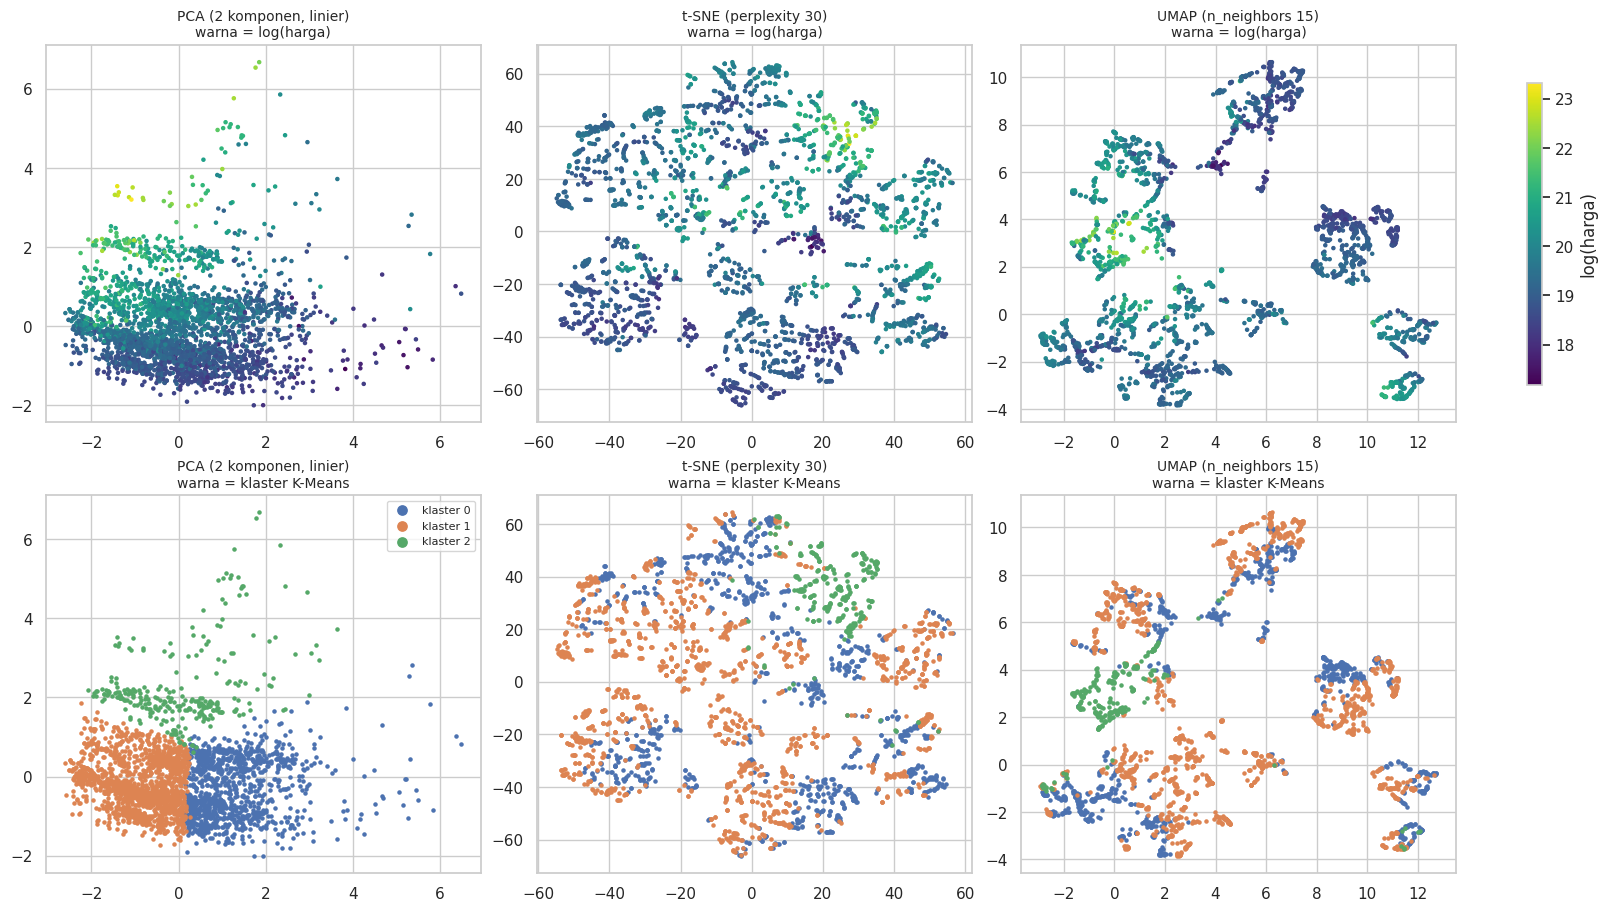

,trustworthiness (k=10)
"PCA (2 komponen, linier)",0.890
t-SNE (perplexity 30),0.990
UMAP (n_neighbors 15),0.983


In [139]:
try:
    import umap
except ImportError:
    get_ipython().system("pip install -q umap-learn")
    import umap

vi = np.random.default_rng(SEED).choice(len(Z_full), 3000, replace=False)
Zv = Z_full[vi]; warna_harga = y_latih.iloc[vi].values; warna_klaster = lab_urut[vi]

t0 = time.time(); emb = {}
emb["PCA (2 komponen, linier)"] = PCA(2, random_state=SEED).fit_transform(Zv)
emb["t-SNE (perplexity 30)"]    = TSNE(2, perplexity=30, init="pca", random_state=SEED).fit_transform(Zv)
emb["UMAP (n_neighbors 15)"]    = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED).fit_transform(Zv)
print(f"Waktu hitung tiga proyeksi: {time.time() - t0:.0f} detik")

fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
for j, (nama, E) in enumerate(emb.items()):
    sc = axes[0, j].scatter(E[:, 0], E[:, 1], c=warna_harga, s=5, cmap="viridis"); axes[0, j].set_title(nama + "\nwarna = log(harga)", fontsize=10)
    for g in np.unique(warna_klaster):
        axes[1, j].scatter(E[warna_klaster == g, 0], E[warna_klaster == g, 1], s=5, label=f"klaster {g}")
    axes[1, j].set_title(nama + "\nwarna = klaster K-Means", fontsize=10)
axes[1, 0].legend(markerscale=3, fontsize=8)
fig.colorbar(sc, ax=axes[0, :].tolist(), shrink=0.8, label="log(harga)")
plt.show()

tw = {nama: trustworthiness(Zv, E, n_neighbors=10) for nama, E in emb.items()}
display(pd.Series(tw, name="trustworthiness (k=10)").round(3).to_frame())

Trustworthiness (makin dekat 1 makin setia menjaga tetangga): PCA 0,890, UMAP 0,983, t-SNE 0,990. Di PCA 2D, mobil mahal dan klaster 2 terlihat di bagian atas. Di t-SNE dan UMAP, klaster 0 dan 1 tampak bercampur. Saya menduga gugusnya lebih dipengaruhi model/merek mobil, tapi ini belum saya uji. Jadi plot ini tidak dipakai untuk menentukan jumlah klaster.

**F2. Jebakan membaca t-SNE: hasil berubah menurut perplexity dan seed**

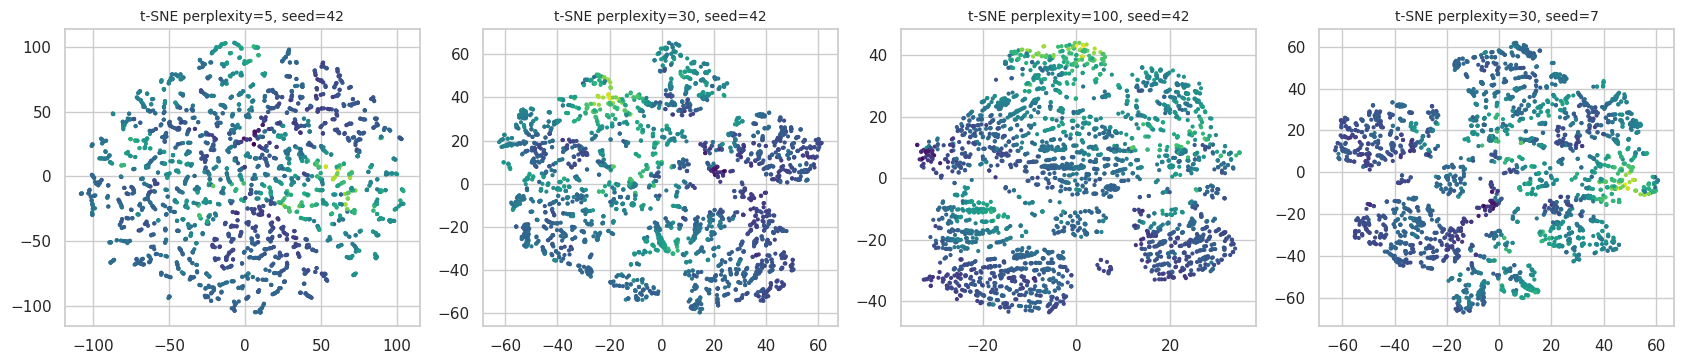

In [140]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (pp, sd) in zip(axes, [(5, SEED), (30, SEED), (100, SEED), (30, 7)]):
    E = TSNE(2, perplexity=pp, init="random", random_state=sd).fit_transform(Zv)
    ax.scatter(E[:, 0], E[:, 1], c=warna_harga, s=4, cmap="viridis"); ax.set_title(f"t-SNE perplexity={pp}, seed={sd}", fontsize=10)
plt.tight_layout(); plt.show()

Bentuk t-SNE berubah ketika perplexity dan seed diganti, jadi jarak dan ukuran gugus tidak boleh ditafsirkan.

## G. Apakah hasil unsupervised membantu model regresi?
Label/jarak klaster ditambahkan sebagai fitur lewat transformer `FiturKlaster` yang di-fit di tiap fold (tanpa memakai `y`). Dibandingkan dengan baseline pada 5-fold CV yang sama.

**G1. Menghubungkan ke regresi: label/jarak klaster sebagai fitur tambahan, di-fit DI DALAM Pipeline**

In [141]:
class FiturKlaster(BaseEstimator, TransformerMixin):
    """K-Means (imputasi + scaling + KMeans) di-fit HANYA pada data latih tiap fold. Tidak memakai y (log_price) sama sekali.
    keluaran='label' -> one-hot label klaster; keluaran='jarak' -> jarak ke setiap pusat klaster."""
    def __init__(self, k=3, kolom=("umur", "km_sqrt", "engine"), keluaran="label", random_state=42):
        self.k = k; self.kolom = kolom; self.keluaran = keluaran; self.random_state = random_state
    def fit(self, X, y=None):
        Xk = X[list(self.kolom)]
        self.imp_ = SimpleImputer(strategy="median").fit(Xk)
        self.sc_ = StandardScaler().fit(self.imp_.transform(Xk))
        self.km_ = KMeans(self.k, n_init=10, random_state=self.random_state).fit(self.sc_.transform(self.imp_.transform(Xk)))
        return self
    def transform(self, X):
        Zk = self.sc_.transform(self.imp_.transform(X[list(self.kolom)]))
        return np.eye(self.k)[self.km_.predict(Zk)] if self.keluaran == "label" else self.km_.transform(Zk)

def model_dengan(jenis, tambahan=None):
    if tambahan is None:
        return Pipeline([("pra", praproses_padat()), ("m", buat_model(jenis))])
    return Pipeline([("fitur", FeatureUnion([("pra", praproses_padat()), ("tambahan", tambahan)])), ("m", buat_model(jenis))])

skenario = {
    "baseline (tanpa tambahan)":       None,
    "+ label klaster K=3":             FiturKlaster(3, keluaran="label"),
    "+ jarak ke pusat klaster K=3":    FiturKlaster(3, keluaran="jarak"),
    "+ label klaster K=8":             FiturKlaster(8, keluaran="label"),
    "+ jarak ke pusat klaster K=8":    FiturKlaster(8, keluaran="jarak"),
    "+ 10 komponen PCA":               Pipeline([("p", praproses_padat()), ("pca", PCA(10, random_state=SEED))]),
}
hasil_g, mae_fold = [], {}
for jenis in ["Linear", "HistGB"]:
    for nama, tambahan in skenario.items():
        t0 = time.time()
        mae, r2 = cv_skor(model_dengan(jenis, tambahan)); mae_fold[(jenis, nama)] = mae
        dasar = mae_fold[(jenis, "baseline (tanpa tambahan)")]
        hasil_g.append({"model": jenis, "skenario": nama, "MAE CV (Rp juta)": mae.mean(), "std": mae.std(ddof=1),
                        "perubahan vs baseline (%)": (mae.mean() / dasar.mean() - 1) * 100,
                        "fold membaik (dari 5)": int((mae < dasar - 0.05).sum()), "R2 CV": r2, "waktu (detik)": time.time() - t0})
tab_g = pd.DataFrame(hasil_g)
display(tab_g.round(3))

,model,skenario,MAE CV (Rp juta),std,perubahan vs baseline (%),fold membaik (dari 5),R2 CV,waktu (detik)
0,Linear,baseline (tanpa tambahan),136.596,6.733,0.000,0,0.821,1.229
1,Linear,+ label klaster K=3,134.378,6.423,-1.623,5,0.823,4.146
2,Linear,+ jarak ke pusat klaster K=3,134.421,5.790,-1.592,5,0.825,3.166
3,Linear,+ label klaster K=8,130.097,7.099,-4.758,5,0.833,3.735
4,Linear,+ jarak ke pusat klaster K=8,128.773,6.709,-5.727,5,0.847,3.812
5,Linear,+ 10 komponen PCA,136.596,6.733,-0.000,0,0.821,4.738
6,HistGB,baseline (tanpa tambahan),85.214,1.678,0.000,0,0.930,24.141
7,HistGB,+ label klaster K=3,84.402,1.804,-0.953,4,0.930,29.017
8,HistGB,+ jarak ke pusat klaster K=3,86.006,2.047,0.930,1,0.927,26.329
9,HistGB,+ label klaster K=8,84.799,2.110,-0.486,2,0.930,28.747


| Model | Baseline | + klaster | Catatan |
|---|---|---|---|
| Linear | 136,6 | **128,8** (jarak, K=8) | membaik di 5 dari 5 fold (-5,7%) |
| HistGB | 85,2 | 84,4 (label, K=3) | -1,0%, tapi variannya tidak konsisten (jarak K=3 malah 86,0; +10 komponen PCA 87,9), dan selisihnya sebanding simpangan baku antar-fold (1,7 sampai 2,5). Tidak dianggap perbaikan. |

PCA sebagai fitur tambahan tidak menambah apa-apa: pada model linier hasilnya persis sama dengan baseline (PCA hanya kombinasi linier dari fitur yang sudah ada).

K untuk fitur dipilih dengan CV, bukan silhouette. Untuk model linier MAE terus turun saat K naik (K=20: 124,5; K=40: 120,0), jadi K-Means di sini lebih berfungsi seperti basis non-linier, bukan segmen yang bermakna. Maka K=3 dipakai untuk interpretasi, dan K untuk fitur dianggap hiperparameter.

**G3. Error analysis: apakah klaster membantu segmen lemah (mewah > Rp 1 miliar, mobil Baru)? Prediksi out-of-fold**

In [142]:
from sklearn.model_selection import cross_val_predict
harga = np.exp(y_latih)
pita = pd.cut(harga / 1e6, [0, 150, 300, 600, 1000, 1e9], labels=["< 150 jt", "150-300 jt", "300-600 jt", "600 jt-1 M", "> 1 M"])
model_bandingan = {"Linear (baseline)": model_dengan("Linear"),
                   "Linear + jarak klaster K=8": model_dengan("Linear", FiturKlaster(8, keluaran="jarak")),
                   "HistGB (baseline)": model_dengan("HistGB"),
                   "HistGB + label klaster K=3": model_dengan("HistGB", FiturKlaster(3, keluaran="label"))}
ape = pd.DataFrame(index=X_latih.index)
for nama, m in model_bandingan.items():
    p = cross_val_predict(m, X_latih, y_latih, cv=kf5)
    ape[nama] = np.abs(np.exp(p) - harga) / harga * 100
ape["pita"] = pita.values; ape["status"] = np.where(X_latih["is_baru"] == 1, "Baru", "Bekas")
print("MAPE out-of-fold (%) per pita harga:")
display(ape.groupby("pita", observed=True)[list(model_bandingan)].mean().round(1).assign(jumlah=ape.groupby("pita", observed=True).size()))
print("MAPE out-of-fold (%) per status iklan:")
display(ape.groupby("status")[list(model_bandingan)].mean().round(1))
print("MAPE total (%):"); display(ape[list(model_bandingan)].mean().round(2).to_frame("MAPE").T)

MAPE out-of-fold (%) per pita harga:


,Linear (baseline),Linear + jarak klaster K=8,HistGB (baseline),HistGB + label klaster K=3,jumlah
pita,,,,,
< 150 jt,31.3,26.1,11.7,11.5,4350
150-300 jt,20.6,16.9,10.3,10.3,8132
300-600 jt,19.8,21.0,14.0,13.9,5227
600 jt-1 M,21.6,22.6,15.3,14.8,2378
> 1 M,36.5,32.9,23.0,22.8,1832


MAPE out-of-fold (%) per status iklan:


,Linear (baseline),Linear + jarak klaster K=8,HistGB (baseline),HistGB + label klaster K=3
status,,,,
Baru,45.6,40.0,25.0,25.2
Bekas,21.6,19.6,11.7,11.6


MAPE total (%):


,Linear (baseline),Linear + jarak klaster K=8,HistGB (baseline),HistGB + label klaster K=3
MAPE,23.97,21.65,13.07,12.94


**Error analysis (out-of-fold di data latih).** Pada model linier, klaster memperbaiki segmen murah, segmen di atas Rp 1 miliar (36,5% menjadi 32,9%), dan mobil Baru (45,6% menjadi 40,0%), tapi memperburuk segmen Rp 300 juta sampai 1 miliar. Pada HistGB hampir tidak ada perubahan (MAPE total 13,07% menjadi 12,94%; di atas Rp 1 miliar 23,0% menjadi 22,8%; mobil Baru 25,0% menjadi 25,2%). Segmen lemah masih ada: HistGB MAPE sekitar 23% di atas Rp 1 miliar dan 25% untuk mobil Baru. Jadi masalah itu belum selesai dengan unsupervised.

## Tabel ringkasan

| Eksperimen | Hasil | Dipakai di model akhir? |
|---|---|---|
| K-Means K=3 (scaled) | silhouette 0,360; `eta2` 0,340; bootstrap ARI 0,964 | Ya, untuk profil dan error analysis |
| Ward (sampel) / DBSCAN | `eta2` 0,270 / 0,092 | Tidak (noise DBSCAN dipakai sebagai kandidat anomali) |
| PCA (90% varians = 24 komponen) | HistGB MAE 85,2 menjadi 87,3 (60 komp.) dan 98,7 (20 komp.) | Tidak |
| Fitur klaster + Linear | MAE 136,6 menjadi 128,8 | Tidak (model akhir bukan Linear) |
| Fitur klaster + HistGB | MAE 85,2 menjadi 84,4 (tidak konsisten) | Tidak |

**Keterbatasan:** klaster dibentuk dari 3 fitur numerik saja dan strukturnya lemah (metrik tidak sepakat soal K); `eta2` memakai harga hanya untuk menilai; nama klaster adalah tafsiran; hasil berlaku untuk data latih (data uji belum dipakai); dugaan penyebab PCA menurunkan akurasi belum diuji.